# 局部视角骨架构建

## 骨架构建 -- 静态图片

endpoints: 8
path length: 934
start: (21, 545) end: (564, 26)


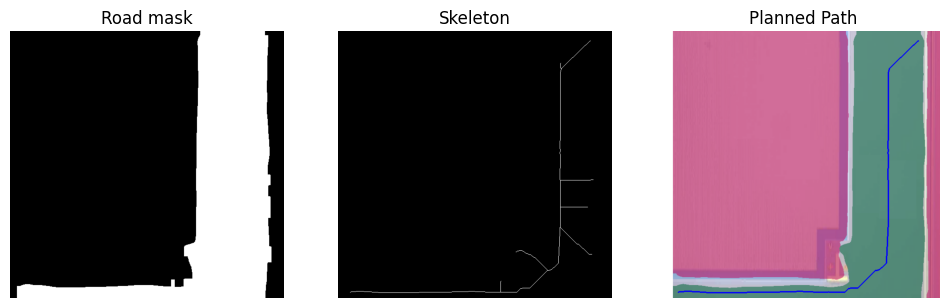

In [2]:
import cv2
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

# 读取红绿分割路径图
image_segment_path = r'c:/users/mr/desktop/Figure_1.png'

def extract_road_mask(rgb_img):
    """
    从语义分割彩色图中提取 road 区域
    你的图里 road 是绿色，因此用 G 通道阈值提取
    """
    R = rgb_img[:, :, 0]
    G = rgb_img[:, :, 1]
    B = rgb_img[:, :, 2]

    # road: G 通道明显大于 R/B
    road = (G > 100) & (G > R) & (G > B)
    return road


def clean_mask(mask):
    """
    形态学去噪，让road区域更连贯
    """
    kernel = np.ones((7, 7), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)

    return mask


def skeleton_to_graph(skel):
    """
    skeleton图转换为无向图
    """
    G = nx.Graph()
    h, w = skel.shape

    # 8邻域
    directions = [(-1, -1), (-1, 0), (-1, 1),
                  (0, -1),           (0, 1),
                  (1, -1),  (1, 0),  (1, 1)]

    for y in range(h):
        for x in range(w):
            if skel[y, x] == 1:
                G.add_node((y, x))
                for dy, dx in directions:
                    ny, nx_ = y + dy, x + dx
                    if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                        G.add_edge((y, x), (ny, nx_), weight=1)
    return G


def find_endpoints(skel):
    """
    找骨架端点：邻居数 == 1
    """
    h, w = skel.shape
    endpoints = []

    directions = [(-1, -1), (-1, 0), (-1, 1),
                  (0, -1),           (0, 1),
                  (1, -1),  (1, 0),  (1, 1)]

    for y in range(h):
        for x in range(w):
            if skel[y, x] == 1:
                neighbors = 0
                for dy, dx in directions:
                    ny, nx_ = y + dy, x + dx
                    if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                        neighbors += 1
                if neighbors == 1:
                    endpoints.append((y, x))

    return endpoints


def find_longest_path_in_skeleton(G, endpoints):
    """
    无起点终点情况下：
    - 在所有端点对中找最远的两个端点
    - 再用 shortest_path 得到主路径
    """
    if len(endpoints) < 2:
        raise ValueError("端点太少，无法规划路径（可能road区域不连通或骨架失败）")

    max_dist = -1
    best_pair = None

    # 计算端点之间的最短路径长度，找最大者
    for i in range(len(endpoints)):
        for j in range(i + 1, len(endpoints)):
            p1, p2 = endpoints[i], endpoints[j]
            try:
                dist = nx.shortest_path_length(G, p1, p2)
                if dist > max_dist:
                    max_dist = dist
                    best_pair = (p1, p2)
            except nx.NetworkXNoPath:
                continue

    if best_pair is None:
        raise ValueError("所有端点之间都不连通，无法找到路径")

    # 主路径：两端点最远距离的最短路径
    path = nx.shortest_path(G, best_pair[0], best_pair[1])
    return path, best_pair


def draw_path_on_image(rgb_img, path, color=(255, 0, 0), radius=1):
    """
    在原图上绘制路径（RGB）
    """
    out = rgb_img.copy()
    for (y, x) in path:
        cv2.circle(out, (x, y), radius, color, -1)
    return out

# 语义分割图
img_path = image_segment_path  
bgr = cv2.imread(img_path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# 1) 提取 road 掩码
road_mask = extract_road_mask(rgb).astype(np.uint8)

# 2) 去噪
road_mask = clean_mask(road_mask)

# 3) 提取骨架
skel = skeletonize(road_mask > 0).astype(np.uint8)

# 4) 骨架 TO 图结构
G = skeleton_to_graph(skel)

# 5) endpoints
endpoints = find_endpoints(skel)
print("endpoints:", len(endpoints))

# 6) longest main path
path, (start, end) = find_longest_path_in_skeleton(G, endpoints)
print("path length:", len(path))
print("start:", start, "end:", end)

# 7) visualize
vis = draw_path_on_image(rgb, path, color=(0, 0, 255), radius=1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1)
plt.title("Road mask")
plt.imshow(road_mask, cmap="gray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Skeleton")
plt.imshow(skel, cmap="gray")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Planned Path")
plt.imshow(vis)
plt.axis("off")

plt.show()


## 骨架构建 -- 视频单帧级别

In [5]:
import cv2
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

# ------------------
# 以下复用你的路径规划函数
# ------------------

def extract_road_mask(rgb_img):
    R = rgb_img[:, :, 0]
    G = rgb_img[:, :, 1]
    B = rgb_img[:, :, 2]
    road = (G > 100) & (G > R) & (G > B)
    return road.astype(np.uint8)

def clean_mask(mask):
    mask = (mask * 255).astype(np.uint8)
    kernel = np.ones((7, 7), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = (mask > 127).astype(np.uint8)
    return mask

def skeleton_to_graph(skel):
    G = nx.Graph()
    h, w = skel.shape
    dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    for y in range(h):
        for x in range(w):
            if skel[y, x] == 1:
                G.add_node((y, x))
                for dy, dx in dirs:
                    ny, nx_ = y + dy, x + dx
                    if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                        G.add_edge((y, x), (ny, nx_), weight=1)
    return G

def find_endpoints(skel):
    h, w = skel.shape
    endpoints = []
    dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    for y in range(h):
        for x in range(w):
            if skel[y, x] == 1:
                nbs = 0
                for dy, dx in dirs:
                    ny, nx_ = y + dy, x + dx
                    if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                        nbs += 1
                if nbs == 1:
                    endpoints.append((y, x))
    return endpoints

def find_longest_path_in_skeleton(G, endpoints):
    if len(endpoints) < 2:
        return [], None
    max_dist = -1
    best_pair = None
    for i in range(len(endpoints)):
        for j in range(i + 1, len(endpoints)):
            p1, p2 = endpoints[i], endpoints[j]
            try:
                dist = nx.shortest_path_length(G, p1, p2)
                if dist > max_dist:
                    max_dist = dist
                    best_pair = (p1, p2)
            except:
                continue
    if best_pair is None:
        return [], None
    path = nx.shortest_path(G, best_pair[0], best_pair[1])
    return path, best_pair

def draw_path_on_image(rgb_img, path, color=(255, 0, 0), radius=1):
    out = rgb_img.copy()
    for (y, x) in path:
        cv2.circle(out, (x, y), radius, color, -1)
    return out

# ------------------
# 视频规划部分
# ------------------

# video_path = r"G:\MyDataset\PHD\1R_seg.mp4"
# output_path = r"G:\MyDataset\PHD\1R_seg_lingo.mp4"

video_path = r"G:\MyDataset\PHD\Scan_Croe_seg_3_classes_112_frames.mp4"
output_path = r"G:\MyDataset\PHD\Scan_Croe_seg_3_classes_112_frames_seg_lingo.mp4"

# video_path = r"G:\MyDataset\PHD\1R_seg_frames.mp4"
# output_path = r"G:\MyDataset\PHD\1R_seg_frames_seg_lingo.mp4"



cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print("无法打开视频")
    exit(0)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0

while True:
    ret, frame_bgr = cap.read()
    if not ret:
        break

    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    road_mask = extract_road_mask(rgb)
    road_mask = clean_mask(road_mask)
    skel = skeletonize(road_mask > 0).astype(np.uint8)

    G = skeleton_to_graph(skel)
    endpoints = find_endpoints(skel)

    path, ep_pair = find_longest_path_in_skeleton(G, endpoints)

    if len(path) > 0:
        vis = draw_path_on_image(rgb, path, color=(0, 0, 255), radius=1)
        vis_bgr = cv2.cvtColor(vis, cv2.COLOR_RGB2BGR)
    else:
        vis_bgr = frame_bgr.copy()

    writer.write(vis_bgr)

    frame_idx += 1
    if frame_idx % 30 == 0:
        print(f"Process {frame_idx} frames...")

cap.release()
writer.release()
print("Finished.")


Process 30 frames...
Process 60 frames...
Process 90 frames...
Process 120 frames...
Process 150 frames...
Process 180 frames...
Process 210 frames...
Process 240 frames...
Process 270 frames...
Process 300 frames...
Process 330 frames...
Process 360 frames...
Process 390 frames...
Process 420 frames...
Process 450 frames...
Process 480 frames...
Process 510 frames...
Process 540 frames...
Process 570 frames...
Process 600 frames...
Process 630 frames...
Process 660 frames...
Process 690 frames...
Process 720 frames...
Process 750 frames...
Process 780 frames...
Process 810 frames...
Process 840 frames...
Process 870 frames...
Process 900 frames...
Process 930 frames...
Process 960 frames...
Process 990 frames...
Process 1020 frames...
Process 1050 frames...
Process 1080 frames...
Process 1110 frames...
Process 1140 frames...
Process 1170 frames...
Process 1200 frames...
Process 1230 frames...
Process 1260 frames...
Process 1290 frames...
Process 1320 frames...
Process 1350 frames...
P

# 芯片全局地图绘制

In [ ]:
# 位姿(编码器) + 视觉重叠/特征匹配 + 边界检测
# 基于边界 判断驱动器的移动：下移尺度 = 一个画面的高度；边界尺度 = 基于"boundary"类型进行



## 基于SLAM局部蛇形视角扫描的全局地图绘制（手动蛇形扫描视频 > 全局地图）

### V1


In [21]:
"""
基于局部视角视频扫描的全局地图绘制
输入: 蛇形扫描的局部视角视频
输出: 全局地图图片
"""

import cv2
import numpy as np
import argparse
import os
import sys
from pathlib import Path


# ─────────────────────────────────────────────
# 1. 帧提取
# ─────────────────────────────────────────────
def extract_frames(video_path: str, sample_interval: int = 10,
                   max_frames: int = 2000) -> list[np.ndarray]:
    """
    从视频中均匀采样帧。
    sample_interval: 每隔多少帧取一帧
    max_frames: 最多取多少帧（防止内存溢出）
    """
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"无法打开视频: {video_path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps   = cap.get(cv2.CAP_PROP_FPS)
    print(f"[视频信息] 总帧数={total}, FPS={fps:.1f}, "
          f"时长={total/fps:.1f}s")

    frames, idx = [], 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % sample_interval == 0:
            frames.append(frame)
            if len(frames) >= max_frames:
                break
        idx += 1
    cap.release()
    print(f"[帧提取] 采样帧数: {len(frames)}")
    return frames


# ─────────────────────────────────────────────
# 2. 关键帧筛选（去掉相似度过高的冗余帧）
# ─────────────────────────────────────────────
def filter_keyframes(frames: list[np.ndarray],
                     diff_threshold: float = 15.0) -> list[np.ndarray]:
    """
    基于帧差筛选关键帧，避免相邻帧过于相似导致拼接困难。
    diff_threshold: 平均像素差阈值，低于此值认为帧变化太小
    """
    if not frames:
        return []
    keyframes = [frames[0]]
    for f in frames[1:]:
        prev_gray = cv2.cvtColor(keyframes[-1], cv2.COLOR_BGR2GRAY)
        curr_gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        diff = cv2.absdiff(prev_gray, curr_gray)
        if diff.mean() > diff_threshold:
            keyframes.append(f)
    print(f"[关键帧] 筛选后关键帧数: {len(keyframes)}")
    return keyframes


# ─────────────────────────────────────────────
# 3. 特征检测与匹配（SIFT / ORB 自适应）
# ─────────────────────────────────────────────
def create_detector():
    """优先使用 SIFT（精度高），不可用则退回 ORB（速度快）"""
    try:
        det = cv2.SIFT_create(nfeatures=3000)
        matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
        print("[特征] 使用 SIFT 特征检测器")
        return det, matcher, "SIFT"
    except:
        det = cv2.ORB_create(nfeatures=3000)
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
        print("[特征] 使用 ORB 特征检测器")
        return det, matcher, "ORB"


def match_features(desc1, desc2, matcher, method: str,
                   ratio: float = 0.75) -> list:
    """Lowe's ratio test 筛选优质匹配对"""
    if desc1 is None or desc2 is None:
        return []
    matches = matcher.knnMatch(desc1, desc2, k=2)
    good = []
    for m_pair in matches:
        if len(m_pair) == 2:
            m, n = m_pair
            if m.distance < ratio * n.distance:
                good.append(m)
    return good


# ─────────────────────────────────────────────
# 4. 单对帧的单应矩阵估计
# ─────────────────────────────────────────────
def estimate_homography(kp1, kp2, matches,
                        min_match: int = 10):
    """
    用 RANSAC 估计单应矩阵 H，将 img2 投影到 img1 坐标系。
    返回 (H, mask) 或 (None, None)。
    """
    if len(matches) < min_match:
        return None, None
    pts1 = np.float32([kp1[m.queryIdx].pt for m in matches])
    pts2 = np.float32([kp2[m.trainIdx].pt for m in matches])
    H, mask = cv2.findHomography(pts2, pts1,
                                 cv2.RANSAC, 5.0,
                                 maxIters=2000,
                                 confidence=0.995)
    if H is None:
        return None, None
    inliers = mask.ravel().sum()
    print(f"    匹配点={len(matches)}, 内点={inliers}")
    if inliers < min_match:
        return None, None
    return H, mask


# ─────────────────────────────────────────────
# 5. 渐进式全局地图拼接
# ─────────────────────────────────────────────
def stitch_frames(keyframes: list[np.ndarray],
                  output_size_limit: int = 8000) -> np.ndarray:
    """
    核心拼接流程：
    - 以第一帧为基准，逐帧累积单应矩阵（全局变换）
    - 动态扩展画布，将每帧 warp 到全局坐标系
    - 使用加权融合（alpha blending）减少接缝
    """
    det, matcher, method = create_detector()

    # 预计算所有关键帧的特征
    print("[特征提取] 计算所有关键帧特征点...")
    kps, descs = [], []
    for i, f in enumerate(keyframes):
        gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        # 直方图均衡化，增强对比度
        gray = cv2.equalizeHist(gray)
        kp, desc = det.detectAndCompute(gray, None)
        kps.append(kp)
        descs.append(desc)
        if (i+1) % 10 == 0:
            print(f"  已处理 {i+1}/{len(keyframes)} 帧")

    # 全局单应矩阵列表（相对于第0帧）
    H_global = [np.eye(3, dtype=np.float64)]  # H[0] = I

    print("[单应矩阵] 估计帧间变换...")
    for i in range(1, len(keyframes)):
        good = match_features(descs[i-1], descs[i], matcher, method)
        H_local, _ = estimate_homography(kps[i-1], kps[i], good)

        if H_local is None:
            print(f"  帧 {i}: 匹配失败，复用前一帧变换")
            H_global.append(H_global[-1].copy())
        else:
            # 全局 = 前一帧全局 @ 本帧局部
            H_global.append(H_global[-1] @ H_local)

    # ── 计算全局画布大小 ──
    h, w = keyframes[0].shape[:2]
    corners_base = np.float32([[0,0],[w,0],[w,h],[0,h]])

    all_corners = []
    for H in H_global:
        c = cv2.perspectiveTransform(
            corners_base.reshape(-1,1,2), H).reshape(-1,2)
        all_corners.append(c)
    all_corners = np.vstack(all_corners)

    x_min, y_min = all_corners.min(axis=0)
    x_max, y_max = all_corners.max(axis=0)

    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))

    # 限制最大画布尺寸，防止内存溢出
    scale = 1.0
    if canvas_w > output_size_limit or canvas_h > output_size_limit:
        scale = output_size_limit / max(canvas_w, canvas_h)
        canvas_w = int(canvas_w * scale)
        canvas_h = int(canvas_h * scale)
        print(f"[画布缩放] 输出过大，缩放比例={scale:.3f}")

    print(f"[画布] 尺寸: {canvas_w} x {canvas_h} px")

    # 平移矩阵，将所有坐标移入正坐标系
    T = np.array([[scale, 0, -x_min*scale],
                  [0, scale, -y_min*scale],
                  [0, 0, 1]], dtype=np.float64)

    # ── 渐进式 Warp + 融合 ──
    canvas       = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
    weight_map   = np.zeros((canvas_h, canvas_w),    dtype=np.float32)

    print("[拼接] 正在将帧融合到全局地图...")
    for i, (frame, H) in enumerate(zip(keyframes, H_global)):
        H_final = T @ H
        warped = cv2.warpPerspective(
            frame.astype(np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        # 生成该帧的遮罩（非零区域）
        mask = cv2.warpPerspective(
            np.ones((h, w), dtype=np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        # 距离加权：帧中心权重高，边缘低（减少接缝）
        dist_weight = cv2.distanceTransform(
            (mask > 0.5).astype(np.uint8),
            cv2.DIST_L2, 3).astype(np.float32)
        dist_weight = np.clip(dist_weight / (dist_weight.max() + 1e-6), 0, 1)

        canvas     += warped * dist_weight[:,:,None]
        weight_map += dist_weight

        if (i+1) % 10 == 0:
            print(f"  已融合 {i+1}/{len(keyframes)} 帧")

    # 归一化
    weight_map = np.maximum(weight_map, 1e-6)
    result = (canvas / weight_map[:,:,None]).astype(np.uint8)

    return result


# ─────────────────────────────────────────────
# 6. 后处理：裁剪空白、增强对比度
# ─────────────────────────────────────────────
def post_process(img: np.ndarray) -> np.ndarray:
    """裁掉黑色边框，做轻微锐化"""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 5, 255, cv2.THRESH_BINARY)
    coords = cv2.findNonZero(thresh)
    if coords is None:
        return img
    x, y, w, h = cv2.boundingRect(coords)
    cropped = img[y:y+h, x:x+w]

    # 轻微锐化
    kernel = np.array([[0,-0.3,0],[-0.3,2.2,-0.3],[0,-0.3,0]])
    sharpened = cv2.filter2D(cropped, -1, kernel)
    return sharpened


# ─────────────────────────────────────────────
# 7. 备用方案：OpenCV Stitcher（快速模式）
# ─────────────────────────────────────────────
def try_opencv_stitcher(frames: list[np.ndarray]) -> np.ndarray | None:
    """
    使用 OpenCV 内置 Stitcher，适合小批量帧。
    成功返回图像，失败返回 None。
    """
    print("[备用] 尝试 OpenCV 内置 Stitcher...")
    # 均匀取最多50帧
    step = max(1, len(frames) // 50)
    subset = frames[::step][:50]
    stitcher = cv2.Stitcher_create(cv2.Stitcher_SCANS)
    status, pano = stitcher.stitch(subset)
    if status == cv2.Stitcher_OK:
        print("[备用] Stitcher 成功！")
        return pano
    else:
        codes = {1: "ERR_NEED_MORE_IMGS", 2: "ERR_HOMOGRAPHY_EST_FAIL",
                 3: "ERR_CAMERA_PARAMS_ADJUST_FAIL"}
        print(f"[备用] Stitcher 失败: {codes.get(status, status)}")
        return None


# ─────────────────────────────────────────────
# 主流程
# ─────────────────────────────────────────────
def build_map(video_path: str,
              output_path: str = "global_map.png",
              sample_interval: int = 3,
              diff_threshold: float = 10.0,
              use_builtin_stitcher: bool = False) -> str:
    """
    完整流程入口。
    返回输出文件路径。
    """
    print("=" * 55)
    print("  全局地图绘制 — 局部视角视频 → 全景地图")
    print("=" * 55)

    # Step 1: 提取帧
    frames = extract_frames(video_path, sample_interval)
    if len(frames) < 3:
        raise ValueError("帧数不足，请检查视频文件")

    # Step 2: 尝试内置 Stitcher（可选）
    result = None
    if use_builtin_stitcher:
        result = try_opencv_stitcher(frames)

    # Step 3: 自定义渐进式拼接
    if result is None:
        keyframes = filter_keyframes(frames, diff_threshold)
        if len(keyframes) < 3:
            print("[警告] 关键帧过少，降低 diff_threshold 重试")
            keyframes = filter_keyframes(frames, diff_threshold / 2)
        result = stitch_frames(keyframes)

    # Step 4: 后处理
    print("[后处理] 裁剪 & 锐化...")
    result = post_process(result)

    # Step 5: 保存
    os.makedirs(os.path.dirname(os.path.abspath(output_path)), exist_ok=True)
    cv2.imwrite(output_path, result)
    h, w = result.shape[:2]
    size_kb = os.path.getsize(output_path) // 1024
    print(f"\n✅ 全局地图已保存: {output_path}")
    print(f"   图像尺寸: {w} x {h} px  |  文件大小: {size_kb} KB")
    return output_path


# ─────────────────────────────────────────────
# CLI 入口
# ─────────────────────────────────────────────
'''
if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="基于局部视角视频扫描的全局地图绘制",
        formatter_class=argparse.RawDescriptionHelpFormatter,
        epilog="""
示例用法:
  python video_to_map.py input.mp4
  python video_to_map.py input.mp4 -o my_map.png
  python video_to_map.py input.mp4 --interval 5 --diff 15
  python video_to_map.py input.mp4 --builtin   # 使用内置 Stitcher
        """)
    parser.add_argument("video", help="输入视频路径")
    parser.add_argument("-o", "--output", default="global_map.png", help="输出地图路径 (默认: global_map.png)")
    parser.add_argument("--interval", type=int, default=3, help="帧采样间隔 (默认: 3, 越小帧越多)")
    parser.add_argument("--diff", type=float, default=10.0, help="关键帧差异阈值 (默认: 10.0)")
    parser.add_argument("--builtin", action="store_true", help="优先尝试 OpenCV 内置 Stitcher")
    args = parser.parse_args()

    try:
        build_map(args.video, args.output, args.interval,
                  args.diff, args.builtin)
    except Exception as e:
        print(f"\n❌ 错误: {e}")
        sys.exit(1)
'''

# Scan_Video_Path = r'G:\MyDataset\PHD\Scan_Croe.mp4'
# Lingo_Map_Path = r'G:\MyDataset\PHD\global_map.png'

Scan_Video_Path = r'F:\0_My_jupyter\0_Optical\scan_output\ToupView\scan_process.mp4'
# Scan_Video_Path = r'C:\Users\Mr\Desktop\0316.mp4'
Lingo_Map_Path = r'F:\0_My_jupyter\0_Optical\scan_output\ToupView\global_map_test.png'
Interval = 5
Diff = 10
Builtin = ''


build_map(Scan_Video_Path, Lingo_Map_Path, Interval, Diff, Builtin)

  全局地图绘制 — 局部视角视频 → 全景地图
[视频信息] 总帧数=79, FPS=10.0, 时长=7.9s
[帧提取] 采样帧数: 16
[关键帧] 筛选后关键帧数: 14
[特征] 使用 SIFT 特征检测器
[特征提取] 计算所有关键帧特征点...
  已处理 10/14 帧
[单应矩阵] 估计帧间变换...
    匹配点=115, 内点=42
    匹配点=142, 内点=52
    匹配点=718, 内点=308
    匹配点=42, 内点=9
  帧 4: 匹配失败，复用前一帧变换
    匹配点=300, 内点=70
    匹配点=63, 内点=10
    匹配点=117, 内点=15
    匹配点=325, 内点=109
    匹配点=186, 内点=49
    匹配点=210, 内点=38
    匹配点=267, 内点=39
    匹配点=761, 内点=171
    匹配点=262, 内点=51
[画布缩放] 输出过大，缩放比例=0.087
[画布] 尺寸: 7999 x 2381 px
[拼接] 正在将帧融合到全局地图...
  已融合 10/14 帧
[后处理] 裁剪 & 锐化...

✅ 全局地图已保存: F:\0_My_jupyter\0_Optical\scan_output\ToupView\global_map_test.png
   图像尺寸: 7999 x 2381 px  |  文件大小: 1409 KB


'F:\\0_My_jupyter\\0_Optical\\scan_output\\ToupView\\global_map_test.png'

### V2


In [ ]:
"""
基于局部视角视频扫描的全局地图绘制
输入: 蛇形扫描的局部视角视频
输出: 全局地图图片
"""

import cv2
import numpy as np
import os


# ─────────────────────────────────────────────
# 1. 帧提取
# ─────────────────────────────────────────────
def extract_frames(video_path: str, sample_interval: int = 10,
                   max_frames: int = 2000) -> list[np.ndarray]:
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"无法打开视频: {video_path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps   = cap.get(cv2.CAP_PROP_FPS)
    print(f"[视频信息] 总帧数={total}, FPS={fps:.1f}, 时长={total/fps:.1f}s")

    frames, idx = [], 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % sample_interval == 0:
            frames.append(frame)
            if len(frames) >= max_frames:
                break
        idx += 1
    cap.release()
    print(f"[帧提取] 采样帧数: {len(frames)}")
    return frames


# ─────────────────────────────────────────────
# 2. 关键帧筛选
# ─────────────────────────────────────────────
def filter_keyframes(frames: list[np.ndarray],
                     diff_threshold: float = 15.0) -> list[np.ndarray]:
    if not frames:
        return []
    keyframes = [frames[0]]
    for f in frames[1:]:
        prev_gray = cv2.cvtColor(keyframes[-1], cv2.COLOR_BGR2GRAY)
        curr_gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        diff = cv2.absdiff(prev_gray, curr_gray)
        if diff.mean() > diff_threshold:
            keyframes.append(f)
    print(f"[关键帧] 筛选后关键帧数: {len(keyframes)}")
    return keyframes


# ─────────────────────────────────────────────
# 3. 特征检测与匹配
# ─────────────────────────────────────────────
def create_detector(nfeatures: int = 3000):
    try:
        det = cv2.SIFT_create(nfeatures=nfeatures)
        matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
        print("[特征] 使用 SIFT 特征检测器")
        return det, matcher, "SIFT"
    except:
        det = cv2.ORB_create(nfeatures=nfeatures)
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
        print("[特征] 使用 ORB 特征检测器")
        return det, matcher, "ORB"


def match_features(desc1, desc2, matcher, method: str, ratio: float = 0.75) -> list:
    if desc1 is None or desc2 is None:
        return []
    matches = matcher.knnMatch(desc1, desc2, k=2)
    good = []
    for m_pair in matches:
        if len(m_pair) == 2:
            m, n = m_pair
            if m.distance < ratio * n.distance:
                good.append(m)
    return good


# ─────────────────────────────────────────────
# 4. 仿射变换估计
# ─────────────────────────────────────────────
def estimate_homography(kp1, kp2, matches,
                        min_match: int = 10,
                        ransac_thresh: float = 3.0,
                        max_iters: int = 2000,
                        confidence: float = 0.995):
    if len(matches) < min_match:
        return None, None
    pts1 = np.float32([kp1[m.queryIdx].pt for m in matches])
    pts2 = np.float32([kp2[m.trainIdx].pt for m in matches])

    M, mask = cv2.estimateAffinePartial2D(
        pts2, pts1,
        method=cv2.RANSAC,
        ransacReprojThreshold=ransac_thresh,
        maxIters=max_iters,
        confidence=confidence
    )
    if M is None or mask.ravel().sum() < min_match:
        return None, None

    inliers = mask.ravel().sum()
    print(f"    匹配点={len(matches)}, 内点={inliers}")

    H = np.eye(3, dtype=np.float64)
    H[:2, :] = M
    return H, mask


# ─────────────────────────────────────────────
# 5. 漂移校正（修复：必须在完整 H_global 建立后调用）
# ─────────────────────────────────────────────
def correct_drift(H_global: list) -> list:
    n = len(H_global)
    if n < 2:
        return H_global

    H_last = H_global[-1]
    drift_angle = np.arctan2(H_last[1, 0], H_last[0, 0])
    drift_scale = np.sqrt(H_last[0, 0]**2 + H_last[1, 0]**2) - 1.0

    print(f"[漂移校正] 累积旋转={np.degrees(drift_angle):.2f}°, 缩放漂移={drift_scale:.4f}")

    H_corrected = []
    for i, H in enumerate(H_global):
        frac = i / (n - 1) if n > 1 else 0
        angle_fix = -drift_angle * frac
        scale_fix = 1.0 / (1.0 + drift_scale * frac)
        R_fix = np.array([
            [scale_fix * np.cos(angle_fix), -scale_fix * np.sin(angle_fix), 0],
            [scale_fix * np.sin(angle_fix),  scale_fix * np.cos(angle_fix), 0],
            [0, 0, 1]
        ])
        H_corrected.append(R_fix @ H)
    return H_corrected


# ─────────────────────────────────────────────
# 6. 拉普拉斯金字塔多频段融合
# ─────────────────────────────────────────────
def _build_laplacian_pyramid(img: np.ndarray, levels: int) -> list:
    gaussian = [img.astype(np.float32)]
    for _ in range(levels):
        gaussian.append(cv2.pyrDown(gaussian[-1]))
    laplacian = []
    for i in range(levels):
        h, w = gaussian[i].shape[:2]
        up = cv2.pyrUp(gaussian[i + 1], dstsize=(w, h))
        laplacian.append(gaussian[i] - up)
    laplacian.append(gaussian[levels])
    return laplacian


def _build_gaussian_pyramid(mask: np.ndarray, levels: int) -> list:
    pyr = [mask.astype(np.float32)]
    for _ in range(levels):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr


def laplacian_blend_into_canvas(canvas: np.ndarray,
                                 warped: np.ndarray,
                                 blend_mask: np.ndarray,
                                 levels: int = 4) -> np.ndarray:
    lp_canvas = _build_laplacian_pyramid(canvas, levels)
    lp_warped = _build_laplacian_pyramid(warped, levels)
    gp_mask   = _build_gaussian_pyramid(blend_mask, levels)

    blended_pyr = []
    for lc, lw, m in zip(lp_canvas, lp_warped, gp_mask):
        m3 = m[:, :, np.newaxis] if lc.ndim == 3 else m
        blended_pyr.append(lc * (1.0 - m3) + lw * m3)

    result = blended_pyr[-1]
    for lb in reversed(blended_pyr[:-1]):
        h, w = lb.shape[:2]
        result = cv2.pyrUp(result, dstsize=(w, h)) + lb

    return np.clip(result, 0, 255).astype(np.float32)


# ─────────────────────────────────────────────
# 7. 渐进式全局地图拼接（核心修复版）
# ─────────────────────────────────────────────
def stitch_frames(keyframes: list[np.ndarray],
                  output_size_limit: int = 8000,
                  blend_levels: int = 4,
                  look_back: int = 3,
                  nfeatures: int = 3000,
                  ratio: float = 0.75,
                  min_match: int = 10,
                  ransac_thresh: float = 3.0,
                  max_iters: int = 2000,
                  confidence: float = 0.995,
                  edge_blend_width: float = 20.0) -> np.ndarray:

    det, matcher, method = create_detector(nfeatures)

    print("[特征提取] 计算所有关键帧特征点...")
    kps, descs = [], []
    for i, f in enumerate(keyframes):
        gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        gray = cv2.equalizeHist(gray)
        kp, desc = det.detectAndCompute(gray, None)
        kps.append(kp)
        descs.append(desc)
        if (i + 1) % 10 == 0:
            print(f"  已处理 {i+1}/{len(keyframes)} 帧")

    # ── 多锚帧匹配，构建 H_global ──
    H_global = [np.eye(3, dtype=np.float64)]

    print("[单应矩阵] 估计帧间变换（多锚帧匹配）...")
    for i in range(1, len(keyframes)):
        best_H       = None
        best_inliers = 0

        for j in range(max(0, i - look_back), i):
            good = match_features(descs[j], descs[i], matcher, method, ratio)
            H_local, mask = estimate_homography(
                kps[j], kps[i], good,
                min_match, ransac_thresh, max_iters, confidence
            )
            if H_local is None:
                continue
            inliers = mask.ravel().sum()
            if inliers > best_inliers:
                best_inliers = inliers
                best_H = H_global[j] @ H_local

        H_global.append(best_H if best_H is not None else H_global[-1].copy())

    # ── ✅ 修复1：漂移校正必须在完整 H_global 建立后调用 ──
    H_global = correct_drift(H_global)

    # 计算全局画布尺寸
    h, w = keyframes[0].shape[:2]
    corners_base = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    all_corners = []
    for H in H_global:
        c = cv2.perspectiveTransform(corners_base.reshape(-1, 1, 2), H).reshape(-1, 2)
        all_corners.append(c)
    all_corners = np.vstack(all_corners)

    x_min, y_min = all_corners.min(axis=0)
    x_max, y_max = all_corners.max(axis=0)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))

    scale = 1.0
    if canvas_w > output_size_limit or canvas_h > output_size_limit:
        scale = output_size_limit / max(canvas_w, canvas_h)
        canvas_w = int(canvas_w * scale)
        canvas_h = int(canvas_h * scale)
        print(f"[画布缩放] 缩放比例={scale:.3f}")

    print(f"[画布] 尺寸: {canvas_w} x {canvas_h} px")

    T = np.array([[scale, 0, -x_min * scale],
                  [0, scale, -y_min * scale],
                  [0, 0, 1]], dtype=np.float64)

    # ── ✅ 修复2：融合策略改为"新帧优先覆盖 + 仅边缘渐变融合" ──
    canvas   = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
    visit_count = np.zeros((canvas_h, canvas_w), dtype=np.int32)

    print(f"[拼接] 拉普拉斯金字塔融合（levels={blend_levels}）...")
    for i, (frame, H) in enumerate(zip(keyframes, H_global)):
        H_final = T @ H

        warped = cv2.warpPerspective(
            frame.astype(np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0
        )

        raw_mask = cv2.warpPerspective(
            np.ones((h, w), dtype=np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0
        )
        frame_valid = (raw_mask > 0.5)

        dist = cv2.distanceTransform(
            frame_valid.astype(np.uint8), cv2.DIST_L2, 3
        ).astype(np.float32)

        soft_mask = np.clip(dist / edge_blend_width, 0.0, 1.0)

        canvas_valid = (canvas.sum(axis=2) > 0)
        overlap  = canvas_valid & frame_valid
        new_only = frame_valid & ~canvas_valid

        if overlap.sum() < 100:
            canvas[frame_valid] = warped[frame_valid]
        else:
            edge_blend_region = overlap & (soft_mask < 1.0)
            center_overwrite  = frame_valid & (soft_mask >= 1.0)

            blend_mask = np.where(edge_blend_region, soft_mask, 0.0).astype(np.float32)
            if edge_blend_region.sum() > 10:
                canvas = laplacian_blend_into_canvas(
                    canvas, warped, blend_mask, levels=blend_levels
                )

            canvas[center_overwrite] = warped[center_overwrite]
            canvas[new_only] = warped[new_only]

        visit_count[frame_valid] += 1

        if (i + 1) % 10 == 0:
            print(f"  已融合 {i+1}/{len(keyframes)} 帧")

    return canvas.astype(np.uint8)


# ─────────────────────────────────────────────
# 8. 后处理
# ─────────────────────────────────────────────
def post_process(img: np.ndarray,
                 sharpen_center: float = 2.2,
                 sharpen_edge: float = 0.3) -> np.ndarray:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 5, 255, cv2.THRESH_BINARY)
    coords = cv2.findNonZero(thresh)
    if coords is None:
        return img
    x, y, w, h = cv2.boundingRect(coords)
    cropped = img[y:y+h, x:x+w]
    kernel = np.array([[0, -sharpen_edge, 0],
                       [-sharpen_edge, sharpen_center, -sharpen_edge],
                       [0, -sharpen_edge, 0]])
    return cv2.filter2D(cropped, -1, kernel)


# ─────────────────────────────────────────────
# 9. 备用方案
# ─────────────────────────────────────────────
def try_opencv_stitcher(frames: list[np.ndarray]) -> np.ndarray | None:
    print("[备用] 尝试 OpenCV 内置 Stitcher...")
    step = max(1, len(frames) // 50)
    subset = frames[::step][:50]
    stitcher = cv2.Stitcher_create(cv2.Stitcher_SCANS)
    status, pano = stitcher.stitch(subset)
    if status == cv2.Stitcher_OK:
        print("[备用] Stitcher 成功！")
        return pano
    codes = {1: "ERR_NEED_MORE_IMGS", 2: "ERR_HOMOGRAPHY_EST_FAIL",
             3: "ERR_CAMERA_PARAMS_ADJUST_FAIL"}
    print(f"[备用] Stitcher 失败: {codes.get(status, status)}")
    return None


# ─────────────────────────────────────────────
# 主流程
# ─────────────────────────────────────────────
def build_map(video_path: str,
              output_path: str = "global_map.png",
              sample_interval: int = 3,
              max_frames: int = 2000,
              diff_threshold: float = 10.0,
              use_builtin_stitcher: bool = False,
              nfeatures: int = 3000,
              ratio: float = 0.75,
              look_back: int = 3,
              min_match: int = 10,
              ransac_thresh: float = 3.0,
              max_iters: int = 2000,
              confidence: float = 0.995,
              blend_levels: int = 4,
              edge_blend_width: float = 20.0,
              output_size_limit: int = 8000,
              sharpen_center: float = 2.2,
              sharpen_edge: float = 0.3) -> str:
    print("=" * 55)
    print("  全局地图绘制 — 局部视角视频 → 全景地图")
    print("=" * 55)

    frames = extract_frames(video_path, sample_interval, max_frames)
    if len(frames) < 3:
        raise ValueError("帧数不足，请检查视频文件")

    result = None
    if use_builtin_stitcher:
        result = try_opencv_stitcher(frames)

    if result is None:
        keyframes = filter_keyframes(frames, diff_threshold)
        if len(keyframes) < 3:
            print("[警告] 关键帧过少，降低 diff_threshold 重试")
            keyframes = filter_keyframes(frames, diff_threshold / 2)
        result = stitch_frames(
            keyframes,
            output_size_limit=output_size_limit,
            blend_levels=blend_levels,
            look_back=look_back,
            nfeatures=nfeatures,
            ratio=ratio,
            min_match=min_match,
            ransac_thresh=ransac_thresh,
            max_iters=max_iters,
            confidence=confidence,
            edge_blend_width=edge_blend_width,
        )

    print("[后处理] 裁剪 & 锐化...")
    result = post_process(result, sharpen_center, sharpen_edge)

    os.makedirs(os.path.dirname(os.path.abspath(output_path)), exist_ok=True)
    cv2.imwrite(output_path, result)
    h, w = result.shape[:2]
    size_kb = os.path.getsize(output_path) // 1024
    print(f"\n✅ 全局地图已保存: {output_path}")
    print(f"   图像尺寸: {w} x {h} px  |  文件大小: {size_kb} KB")
    return output_path


# ── 路径 ──────────────────────────────────────────────
Scan_Video_Path = r'F:\0_My_jupyter\0_Optical\scan_output\Target_1_layer.mp4'
Lingo_Map_Path  = r'F:\0_My_jupyter\0_Optical\scan_output\global_map_test_auto_1.png'

# ── 帧提取 ────────────────────────────────────────────
Interval    = 5        # 每隔多少帧采样一次（越小帧越密，越慢）
Max_Frames  = 2000     # 最多采样帧数上限

# ── 关键帧筛选 ────────────────────────────────────────
Diff        = 10.0     # 相邻帧差异阈值，越大筛选越严（关键帧越少）

# ── 特征检测 ──────────────────────────────────────────
NFeatures   = 3500     # SIFT/ORB 最大特征点数，越多匹配越准但越慢

# ── 特征匹配 ──────────────────────────────────────────
Ratio       = 0.95     # Lowe's ratio test 阈值，越小匹配越严格

# ── 多锚帧回溯 ────────────────────────────────────────
Look_Back   = 3        # 向前回溯的锚帧数量，越大越鲁棒但越慢

# ── RANSAC 单应矩阵估计 ───────────────────────────────
Min_Match       = 10      # 最少内点数，低于此则放弃该帧对
Ransac_Thresh   = 4.0     # 重投影误差容限（像素），越小越严格【该参数较为重要】
Max_Iters       = 2000    # RANSAC 最大迭代次数
Confidence      = 0.995   # RANSAC 置信度

# ── 融合 ──────────────────────────────────────────────
Blend_Levels    = 2       # 拉普拉斯金字塔层数，越多过渡越平滑
Edge_Blend_Width = 8.0   # 边缘渐变带宽度（像素），越大过渡越柔和

# ── 画布输出 ──────────────────────────────────────────
Output_Size_Limit = 10000  # 画布最大边长（像素），超出则等比缩放

# ── 后处理锐化 ────────────────────────────────────────
Sharpen_Center  = 3.0     # 锐化核中心权重，越大越锐利
Sharpen_Edge    = 0.5     # 锐化核边缘权重，越大越锐利

# ── 备用拼接器 ────────────────────────────────────────
Builtin = False           # True = 优先使用 OpenCV 内置 Stitcher

# ═══════════════════════════════════════════════════════

build_map( video_path = Scan_Video_Path, output_path = Lingo_Map_Path, sample_interval = Interval, max_frames = Max_Frames, diff_threshold = Diff, use_builtin_stitcher = Builtin,
    nfeatures = NFeatures, ratio = Ratio, look_back = Look_Back, min_match = Min_Match, ransac_thresh = Ransac_Thresh, max_iters = Max_Iters, confidence = Confidence, 
    blend_levels = Blend_Levels, edge_blend_width  = Edge_Blend_Width, output_size_limit = Output_Size_Limit, sharpen_center = Sharpen_Center, sharpen_edge = Sharpen_Edge,
)

  全局地图绘制 — 局部视角视频 → 全景地图
[视频信息] 总帧数=121, FPS=30.0, 时长=4.0s
[帧提取] 采样帧数: 25
[关键帧] 筛选后关键帧数: 24
[特征] 使用 SIFT 特征检测器
[特征提取] 计算所有关键帧特征点...
  已处理 10/24 帧
  已处理 20/24 帧
[单应矩阵] 估计帧间变换（多锚帧匹配）...
    匹配点=1543, 内点=297
    匹配点=1003, 内点=12
    匹配点=1345, 内点=10
    匹配点=1780, 内点=45
    匹配点=1664, 内点=26
    匹配点=1741, 内点=30
    匹配点=1783, 内点=13
    匹配点=1814, 内点=16
    匹配点=1835, 内点=16
    匹配点=1821, 内点=20
    匹配点=1778, 内点=74
    匹配点=1761, 内点=23
    匹配点=1763, 内点=24
    匹配点=1705, 内点=13
    匹配点=1771, 内点=12
    匹配点=1700, 内点=13
    匹配点=1758, 内点=15
    匹配点=1672, 内点=40
    匹配点=1661, 内点=15
    匹配点=1597, 内点=12
    匹配点=1720, 内点=63
    匹配点=1742, 内点=10
    匹配点=1678, 内点=86
    匹配点=1728, 内点=10
    匹配点=1673, 内点=13
    匹配点=1727, 内点=97
    匹配点=1644, 内点=15
    匹配点=1694, 内点=12
    匹配点=1742, 内点=137
    匹配点=1592, 内点=29
    匹配点=1672, 内点=145
    匹配点=1498, 内点=14
    匹配点=1615, 内点=45
    匹配点=1682, 内点=183
    匹配点=1505, 内点=14
    匹配点=1584, 内点=52
    匹配点=1761, 内点=268
    匹配点=1621, 内点=13
    匹配点=1638, 内点=101
    匹配点=1594, 内点=13
    匹配点=15

'F:\\0_My_jupyter\\0_Optical\\scan_output\\global_map_test_auto_1_tmp.png'

### V3(已完成第2层的全局地图规划)

In [ ]:
"""
基于局部视角视频扫描的全局地图绘制
输入: 蛇形扫描的局部视角视频
输出: 全局地图图片

优化说明（v11）：
1. [核心修复] 解决两行长度不一致问题：
   - 新增 align_rows_x_span：在对齐 x_min 之后，还对齐 x_max
   - 对第二行做线性拉伸/压缩，使两行的 X 跨度（x_max - x_min）相等
   - 拉伸方式：以行的 x_min 为锚点，按比例缩放每帧的 tx
2. [保留 v10] 基于全行 x_min 的 X 对齐
3. [保留] 备用位姿估算只修正 Y，保留 tx
4. [保留] Translation_Only=True、亮度归一化、加权融合
"""

import cv2
import numpy as np
import os


# ─────────────────────────────────────────────
# 1. 帧提取
# ─────────────────────────────────────────────
def extract_frames(video_path: str, sample_interval: int = 10,
                   max_frames: int = 2000) -> list:
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"无法打开视频: {video_path}")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps   = cap.get(cv2.CAP_PROP_FPS)
    print(f"[视频信息] 总帧数={total}, FPS={fps:.1f}, 时长={total/fps:.1f}s")

    frames, idx = [], 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if idx % sample_interval == 0:
            frames.append(frame)
            if len(frames) >= max_frames:
                break
        idx += 1
    cap.release()
    print(f"[帧提取] 采样帧数: {len(frames)}")
    return frames


# ─────────────────────────────────────────────
# 2. 关键帧筛选
# ─────────────────────────────────────────────
def filter_keyframes(frames: list, diff_threshold: float = 15.0) -> list:
    if not frames:
        return []
    keyframes = [frames[0]]
    for f in frames[1:]:
        prev_gray = cv2.cvtColor(keyframes[-1], cv2.COLOR_BGR2GRAY)
        curr_gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        diff = cv2.absdiff(prev_gray, curr_gray)
        if diff.mean() > diff_threshold:
            keyframes.append(f)
    print(f"[关键帧] 筛选后关键帧数: {len(keyframes)}")
    return keyframes


# ─────────────────────────────────────────────
# 3. 特征检测与匹配
# ─────────────────────────────────────────────
def create_detector(nfeatures: int = 3000):
    try:
        det = cv2.SIFT_create(nfeatures=nfeatures)
        matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
        print("[特征] 使用 SIFT 特征检测器")
        return det, matcher, "SIFT"
    except:
        det = cv2.ORB_create(nfeatures=nfeatures)
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
        print("[特征] 使用 ORB 特征检测器")
        return det, matcher, "ORB"


_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))

def enhance_gray(gray: np.ndarray) -> np.ndarray:
    return _clahe.apply(gray)


def match_features(desc1, desc2, matcher, method: str, ratio: float = 0.75) -> list:
    if desc1 is None or desc2 is None:
        return []
    matches = matcher.knnMatch(desc1, desc2, k=2)
    good = []
    for m_pair in matches:
        if len(m_pair) == 2:
            m, n = m_pair
            if m.distance < ratio * n.distance:
                good.append(m)
    return good


# ─────────────────────────────────────────────
# 4. 仿射变换估计
# ─────────────────────────────────────────────
def estimate_homography(kp1, kp2, matches,
                        min_match: int = 10,
                        ransac_thresh: float = 3.0,
                        max_iters: int = 2000,
                        confidence: float = 0.995,
                        max_rotation_deg: float = 1.0,
                        translation_only: bool = True):
    if len(matches) < min_match:
        return None, None
    pts1 = np.float32([kp1[m.queryIdx].pt for m in matches])
    pts2 = np.float32([kp2[m.trainIdx].pt for m in matches])

    M, mask = cv2.estimateAffinePartial2D(
        pts2, pts1,
        method=cv2.RANSAC,
        ransacReprojThreshold=ransac_thresh,
        maxIters=max_iters,
        confidence=confidence
    )
    if M is None or mask.ravel().sum() < min_match:
        return None, None

    inliers = mask.ravel().sum()
    print(f"    匹配点={len(matches)}, 内点={inliers}")

    if translation_only:
        tx, ty = M[0, 2], M[1, 2]
        M = np.array([[1.0, 0.0, tx],
                      [0.0, 1.0, ty]], dtype=np.float64)
    else:
        angle_rad = np.arctan2(M[1, 0], M[0, 0])
        angle_deg = np.degrees(angle_rad)
        if abs(angle_deg) > max_rotation_deg:
            print(f"    [旋转限制] {angle_deg:.2f}° 超阈值，置零")
            scale = np.clip(np.sqrt(M[0, 0]**2 + M[1, 0]**2), 0.95, 1.05)
            M[0, 0] = scale; M[1, 1] = scale
            M[0, 1] = 0.0;   M[1, 0] = 0.0

    H = np.eye(3, dtype=np.float64)
    H[:2, :] = M
    return H, mask


# ─────────────────────────────────────────────
# 5. 换行点检测
# ─────────────────────────────────────────────
def detect_row_breaks(H_global: list,
                      frame_w: int,
                      frame_h: int,
                      x_move_thresh: float = 0.3,
                      y_jump_factor: float = 0.5) -> list:
    tx_list = [H[0, 2] for H in H_global]
    ty_list = [H[1, 2] for H in H_global]

    breaks = []
    window = 3
    for i in range(window, len(H_global) - 1):
        dx_prev = tx_list[i] - tx_list[max(0, i - window)]
        dx_next = tx_list[min(len(tx_list)-1, i + window)] - tx_list[i]
        dy_step = abs(ty_list[i + 1] - ty_list[i])

        x_reversed = (dx_prev * dx_next < 0) and \
                     (abs(dx_prev) > frame_w * x_move_thresh)
        y_jumped = dy_step > frame_h * y_jump_factor

        if (x_reversed or y_jumped) and i not in breaks:
            breaks.append(i)

    breaks = sorted(set(breaks))
    merged = []
    for b in breaks:
        if merged and b - merged[-1] < 5:
            continue
        merged.append(b)

    print(f"[行检测] 检测到 {len(merged)} 个换行点，索引={merged}")
    return merged


# ─────────────────────────────────────────────
# 6. 亮度一致性补偿
# ─────────────────────────────────────────────
def normalize_brightness(keyframes: list, ref_percentile: float = 50.0) -> list:
    global_vals = []
    for f in keyframes[::max(1, len(keyframes)//20)]:
        gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        global_vals.append(np.percentile(gray, ref_percentile))
    global_ref = np.mean(global_vals)

    normalized = []
    for f in keyframes:
        gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        local_val = np.percentile(gray, ref_percentile)
        if local_val > 5:
            gain = np.clip(global_ref / local_val, 0.7, 1.4)
            f_norm = np.clip(f.astype(np.float32) * gain, 0, 255).astype(np.uint8)
        else:
            f_norm = f
        normalized.append(f_norm)

    print(f"[亮度归一化] 全局基准亮度={global_ref:.1f}")
    return normalized


# ─────────────────────────────────────────────
# 7. 位姿平滑
# ─────────────────────────────────────────────
def smooth_poses(H_global: list, row_breaks: list, window: int = 3) -> list:
    segments_idx = []
    prev = 0
    for brk in row_breaks:
        segments_idx.append(list(range(prev, brk + 1)))
        prev = brk + 1
    if prev < len(H_global):
        segments_idx.append(list(range(prev, len(H_global))))

    result = [H.copy() for H in H_global]

    for seg in segments_idx:
        if len(seg) < window * 2 + 1:
            continue
        tx_arr = np.array([H_global[i][0, 2] for i in seg])
        ty_arr = np.array([H_global[i][1, 2] for i in seg])

        kernel = np.exp(-0.5 * np.arange(-window, window+1)**2 / (window/2)**2)
        kernel /= kernel.sum()

        tx_sm = np.convolve(tx_arr, kernel, mode='same')
        ty_sm = np.convolve(ty_arr, kernel, mode='same')
        tx_sm[:window] = tx_arr[:window];   tx_sm[-window:] = tx_arr[-window:]
        ty_sm[:window] = ty_arr[:window];   ty_sm[-window:] = ty_arr[-window:]

        for k, i in enumerate(seg):
            result[i] = H_global[i].copy()
            result[i][0, 2] = tx_sm[k]
            result[i][1, 2] = ty_sm[k]

    print(f"[位姿平滑] 已对 {len(segments_idx)} 段做滑动平均 (window={window})")
    return result


# ─────────────────────────────────────────────
# 8. 行 X 范围计算工具
# ─────────────────────────────────────────────
def get_row_x_bounds(H_global: list, row_seg: list,
                     frame_w: int, frame_h: int) -> tuple:
    """计算一行所有帧投影后的全局 x_min 和 x_max。"""
    corners_base = np.float32([[0, 0], [frame_w, 0],
                                [frame_w, frame_h], [0, frame_h]])
    x_mins, x_maxs = [], []
    for i in row_seg:
        c = cv2.perspectiveTransform(
            corners_base.reshape(-1, 1, 2), H_global[i]
        ).reshape(-1, 2)
        x_mins.append(c[:, 0].min())
        x_maxs.append(c[:, 0].max())
    return float(np.min(x_mins)), float(np.max(x_maxs))


# ─────────────────────────────────────────────
# 9. ✅ v11 核心：行间 X 对齐（同时对齐 x_min 和 x_max）
# ─────────────────────────────────────────────
def align_rows_x_full(H_global: list, row_breaks: list,
                      frame_w: int, frame_h: int,
                      x_align_thresh: float = 0.03) -> list:
    """
    ✅ v11 X 对齐策略：同时对齐两行的 x_min 和 x_max。

    步骤：
    1. 计算参考行（第0行）的 x_min_ref 和 x_max_ref（行宽 span_ref）
    2. 对每个后续行：
       a. 计算其当前 x_min_curr 和 x_max_curr（行宽 span_curr）
       b. 平移修正：tx_offset = x_min_ref - x_min_curr（对齐左端）
       c. 缩放修正：scale = span_ref / span_curr（对齐行宽）
          每帧的 tx 相对行起始点 x_min_curr 做缩放：
          tx_new = x_min_ref + (tx_old - x_min_curr) * scale
       d. 容差控制：仅在偏差超过阈值时执行，缩放比例限制在 [0.85, 1.15]

    注意：Y 方向不修正。
    """
    row_segments = []
    prev = 0
    for brk in row_breaks:
        row_segments.append(list(range(prev, brk + 1)))
        prev = brk + 1
    if prev < len(H_global):
        row_segments.append(list(range(prev, len(H_global))))

    if len(row_segments) < 2:
        return H_global

    result = [H.copy() for H in H_global]

    # 参考行（第0行）的 X 范围
    x_min_ref, x_max_ref = get_row_x_bounds(result, row_segments[0], frame_w, frame_h)
    span_ref = x_max_ref - x_min_ref
    print(f"[X对齐] 参考行(第0行) x_min={x_min_ref:.1f}, x_max={x_max_ref:.1f}, 跨度={span_ref:.1f}px")

    for row_idx in range(1, len(row_segments)):
        curr_seg = row_segments[row_idx]

        x_min_curr, x_max_curr = get_row_x_bounds(result, curr_seg, frame_w, frame_h)
        span_curr = x_max_curr - x_min_curr

        x_diff = x_min_ref - x_min_curr          # 左端偏差
        span_diff = abs(span_ref - span_curr)     # 行宽偏差

        print(f"[X对齐] 第{row_idx}行 x_min={x_min_curr:.1f}, x_max={x_max_curr:.1f}, "
              f"跨度={span_curr:.1f}px | 左偏差={x_diff:.1f}, 跨度差={span_diff:.1f}")

        # ── 步骤1：平移对齐左端 ──
        if abs(x_diff) > frame_w * x_align_thresh:
            print(f"    → 执行左端平移修正 {x_diff:.1f}px")
            for i in curr_seg:
                result[i] = result[i].copy()
                result[i][0, 2] += x_diff
            # 更新 x_min_curr
            x_min_curr += x_diff
            x_max_curr += x_diff

        # ── 步骤2：缩放对齐行宽 ──
        if span_curr > 1.0 and span_diff > frame_w * x_align_thresh:
            scale = span_ref / span_curr
            scale = np.clip(scale, 0.85, 1.15)  # 限制缩放幅度
            print(f"    → 执行行宽缩放修正 scale={scale:.4f}")
            for i in curr_seg:
                old_tx = result[i][0, 2]
                # 以 x_min_curr 为锚点做缩放
                result[i][0, 2] = x_min_curr + (old_tx - x_min_curr) * scale
        else:
            print(f"    → 行宽偏差={span_diff:.1f}px，在阈值内，无需缩放")

    return result


# ─────────────────────────────────────────────
# 10. 备用位姿估算（只修正 Y，保留 tx）
# ─────────────────────────────────────────────
def estimate_row_start_pose_fallback(H_global: list, brk_idx: int,
                                      next_frame_i: int,
                                      frame_w: int, frame_h: int) -> np.ndarray:
    """
    跨行特征匹配失败时的备用方案：
    只把新行第一帧的 ty 修正为换行点帧底部边界，tx 保持不变。
    后续 align_rows_x_full 会再做 X 精修。
    """
    H_brk = H_global[brk_idx]
    H_next = H_global[next_frame_i]

    corners_base = np.float32([[0, 0], [frame_w, 0],
                                [frame_w, frame_h], [0, frame_h]])
    c_brk = cv2.perspectiveTransform(
        corners_base.reshape(-1, 1, 2), H_brk
    ).reshape(-1, 2)
    brk_y_max = c_brk[:, 1].max()

    H_estimated = H_next.copy()
    H_estimated[1, 2] = brk_y_max
    print(f"    [备用估算] 保留 tx={H_next[0,2]:.1f}，修正 ty={brk_y_max:.1f}")
    return H_estimated


# ─────────────────────────────────────────────
# 11. 渐进式全局地图拼接（v11 核心）
# ─────────────────────────────────────────────
def stitch_frames(keyframes: list,
                  output_size_limit: int = 8000,
                  look_back: int = 8,
                  nfeatures: int = 3000,
                  ratio: float = 0.75,
                  min_match: int = 10,
                  ransac_thresh: float = 3.0,
                  max_iters: int = 2000,
                  confidence: float = 0.995,
                  edge_blend_width: float = 40.0,
                  smooth_window: int = 3,
                  max_rotation_deg: float = 1.0,
                  translation_only: bool = True,
                  cross_anchor_range: int = 15,
                  x_align_thresh: float = 0.03) -> np.ndarray:

    keyframes = normalize_brightness(keyframes)
    det, matcher, method = create_detector(nfeatures)

    print("[特征提取] 计算所有关键帧特征点（CLAHE 增强）...")
    kps, descs = [], []
    for i, f in enumerate(keyframes):
        gray = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        gray = enhance_gray(gray)
        kp, desc = det.detectAndCompute(gray, None)
        kps.append(kp)
        descs.append(desc)
        if (i + 1) % 10 == 0:
            print(f"  已处理 {i+1}/{len(keyframes)} 帧")

    h_frame, w_frame = keyframes[0].shape[:2]

    # ── 第一遍：标准多锚帧匹配 ──
    H_global = [np.eye(3, dtype=np.float64)]
    print("[单应矩阵] 第一遍：标准多锚帧匹配...")
    for i in range(1, len(keyframes)):
        best_H, best_inliers = None, 0
        for j in range(max(0, i - look_back), i):
            good = match_features(descs[j], descs[i], matcher, method, ratio)
            H_local, mask = estimate_homography(
                kps[j], kps[i], good,
                min_match, ransac_thresh, max_iters, confidence,
                max_rotation_deg=max_rotation_deg,
                translation_only=translation_only
            )
            if H_local is None:
                continue
            inliers = mask.ravel().sum()
            if inliers > best_inliers:
                best_inliers = inliers
                best_H = H_global[j] @ H_local
        H_global.append(best_H if best_H is not None else H_global[-1].copy())

    # ── 检测换行点 ──
    row_breaks = detect_row_breaks(H_global, frame_w=w_frame, frame_h=h_frame)
    print(f"[行检测] row_breaks = {row_breaks}")

    # ── 第二遍：跨行强制匹配，并传播修正 ──
    print("[单应矩阵] 第二遍：跨行强制匹配（含行内传播修正）...")
    for brk_idx_pos, brk_idx in enumerate(row_breaks):
        next_frame_i = brk_idx + 1
        if next_frame_i >= len(keyframes):
            continue

        print(f"  处理换行点 brk={brk_idx}, 下一帧={next_frame_i}")
        best_H, best_inliers = None, 0

        actual_cross_range = min(cross_anchor_range, brk_idx + 1)
        anchor_range = range(max(0, brk_idx - actual_cross_range + 1), brk_idx + 1)

        target_frames = [next_frame_i]
        for extra in [1, 2, 3]:
            if next_frame_i + extra < len(keyframes):
                target_frames.append(next_frame_i + extra)

        for target_i in target_frames:
            for j in anchor_range:
                good = match_features(descs[j], descs[target_i], matcher, method, ratio)
                H_local, mask = estimate_homography(
                    kps[j], kps[target_i], good,
                    min_match, ransac_thresh, max_iters, confidence,
                    max_rotation_deg=max_rotation_deg,
                    translation_only=translation_only
                )
                if H_local is None:
                    continue
                inliers = mask.ravel().sum()
                if inliers > best_inliers:
                    best_inliers = inliers
                    H_target = H_global[j] @ H_local
                    if target_i == next_frame_i:
                        best_H = H_target
                    else:
                        H_rel_old = np.linalg.inv(H_global[next_frame_i]) @ H_global[target_i]
                        best_H = H_target @ np.linalg.inv(H_rel_old)

        row_end = row_breaks[brk_idx_pos + 1] if brk_idx_pos + 1 < len(row_breaks) else len(keyframes)

        if best_H is not None and best_inliers >= min_match:
            print(f"    跨行匹配成功，内点={best_inliers}，更新 H_global[{next_frame_i}]")
            H_correction = best_H @ np.linalg.inv(H_global[next_frame_i])
            for k in range(next_frame_i, row_end):
                H_global[k] = H_correction @ H_global[k]
            print(f"    已将修正传播到帧 {next_frame_i}~{row_end-1}")
        else:
            print(f"    跨行匹配失败（内点={best_inliers}），使用备用估算...")
            H_estimated = estimate_row_start_pose_fallback(
                H_global, brk_idx, next_frame_i, w_frame, h_frame
            )
            H_correction = H_estimated @ np.linalg.inv(H_global[next_frame_i])
            for k in range(next_frame_i, row_end):
                H_global[k] = H_correction @ H_global[k]
            print(f"    备用估算已传播到帧 {next_frame_i}~{row_end-1}")

    # ── ✅ v11: 同时对齐 x_min 和 x_max（解决行长不一致问题）──
    H_global = align_rows_x_full(
        H_global, row_breaks, w_frame, h_frame,
        x_align_thresh=x_align_thresh
    )

    # ── 位姿平滑 ──
    H_global = smooth_poses(H_global, row_breaks, window=smooth_window)

    # ── 计算全局画布尺寸 ──
    h, w = keyframes[0].shape[:2]
    corners_base = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    all_corners = []
    for H in H_global:
        c = cv2.perspectiveTransform(corners_base.reshape(-1, 1, 2), H).reshape(-1, 2)
        all_corners.append(c)
    all_corners = np.vstack(all_corners)

    x_min, y_min = all_corners.min(axis=0)
    x_max, y_max = all_corners.max(axis=0)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))

    scale = 1.0
    if canvas_w > output_size_limit or canvas_h > output_size_limit:
        scale = output_size_limit / max(canvas_w, canvas_h)
        canvas_w = int(canvas_w * scale)
        canvas_h = int(canvas_h * scale)
        print(f"[画布缩放] 缩放比例={scale:.3f}")

    print(f"[画布] 尺寸: {canvas_w} x {canvas_h} px")

    T = np.array([[scale, 0, -x_min * scale],
                  [0, scale, -y_min * scale],
                  [0, 0, 1]], dtype=np.float64)

    # ── 构建每帧所属行号 ──
    frame_row = []
    current_row = 0
    break_set = set(row_breaks)
    for i in range(len(keyframes)):
        frame_row.append(current_row)
        if i in break_set:
            current_row += 1

    # ── 距离变换加权融合 ──
    canvas_sum    = np.zeros((canvas_h, canvas_w, 3), dtype=np.float64)
    canvas_weight = np.zeros((canvas_h, canvas_w),    dtype=np.float64)

    print("[拼接] 加权叠加融合...")
    for i, (frame, H) in enumerate(zip(keyframes, H_global)):
        H_final = T @ H

        warped = cv2.warpPerspective(
            frame.astype(np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0
        )
        raw_mask = cv2.warpPerspective(
            np.ones((h, w), dtype=np.float32), H_final,
            (canvas_w, canvas_h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT, borderValue=0
        )
        frame_valid = (raw_mask > 0.5)

        dist = cv2.distanceTransform(
            frame_valid.astype(np.uint8), cv2.DIST_L2, 5
        ).astype(np.float64)

        is_row_start = (i > 0 and frame_row[i] != frame_row[i - 1])
        blend_w = edge_blend_width * 2.5 if is_row_start else edge_blend_width
        weight = np.clip(dist / blend_w, 0.0, 1.0)

        canvas_sum   += warped.astype(np.float64) * weight[:, :, np.newaxis]
        canvas_weight += weight

        if (i + 1) % 10 == 0:
            print(f"  已融合 {i+1}/{len(keyframes)} 帧")

    # ── 归一化 ──
    mask_nonzero = canvas_weight > 0
    canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.float32)
    canvas[mask_nonzero] = (
        canvas_sum[mask_nonzero] / canvas_weight[mask_nonzero, np.newaxis]
    ).astype(np.float32)

    # ── 接缝区域模糊平滑 ──
    result_uint8 = np.clip(canvas, 0, 255).astype(np.uint8)
    seam_region = (canvas_weight > 0) & (canvas_weight < edge_blend_width * 0.5)
    if seam_region.sum() > 100:
        blurred = cv2.GaussianBlur(result_uint8, (5, 5), 1.5)
        seam_mask = seam_region.astype(np.float32)[:, :, np.newaxis]
        result_uint8 = np.clip(
            result_uint8.astype(np.float32) * (1 - seam_mask) +
            blurred.astype(np.float32) * seam_mask,
            0, 255
        ).astype(np.uint8)

    return result_uint8


# ─────────────────────────────────────────────
# 12. 后处理
# ─────────────────────────────────────────────
def post_process(img: np.ndarray,
                 sharpen_center: float = 2.2,
                 sharpen_edge: float = 0.3) -> np.ndarray:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 5, 255, cv2.THRESH_BINARY)
    coords = cv2.findNonZero(thresh)
    if coords is None:
        return img
    x, y, w, h = cv2.boundingRect(coords)
    cropped = img[y:y+h, x:x+w]
    kernel = np.array([[0, -sharpen_edge, 0],
                       [-sharpen_edge, sharpen_center, -sharpen_edge],
                       [0, -sharpen_edge, 0]])
    return cv2.filter2D(cropped, -1, kernel)


# ─────────────────────────────────────────────
# 13. 备用方案
# ─────────────────────────────────────────────
def try_opencv_stitcher(frames: list):
    print("[备用] 尝试 OpenCV 内置 Stitcher...")
    step = max(1, len(frames) // 50)
    subset = frames[::step][:50]
    stitcher = cv2.Stitcher_create(cv2.Stitcher_SCANS)
    status, pano = stitcher.stitch(subset)
    if status == cv2.Stitcher_OK:
        print("[备用] Stitcher 成功！")
        return pano
    codes = {1: "ERR_NEED_MORE_IMGS", 2: "ERR_HOMOGRAPHY_EST_FAIL",
             3: "ERR_CAMERA_PARAMS_ADJUST_FAIL"}
    print(f"[备用] Stitcher 失败: {codes.get(status, status)}")
    return None


# ─────────────────────────────────────────────
# 主流程
# ─────────────────────────────────────────────
def build_map(video_path: str,
              output_path: str = "global_map.png",
              sample_interval: int = 3,
              max_frames: int = 2000,
              diff_threshold: float = 10.0,
              use_builtin_stitcher: bool = False,
              nfeatures: int = 3000,
              ratio: float = 0.75,
              look_back: int = 8,
              min_match: int = 10,
              ransac_thresh: float = 3.0,
              max_iters: int = 2000,
              confidence: float = 0.995,
              edge_blend_width: float = 40.0,
              smooth_window: int = 3,
              output_size_limit: int = 8000,
              sharpen_center: float = 2.2,
              sharpen_edge: float = 0.3,
              max_rotation_deg: float = 1.0,
              translation_only: bool = True,
              cross_anchor_range: int = 15,
              x_align_thresh: float = 0.03) -> str:
    print("=" * 55)
    print("  全局地图绘制 — 局部视角视频 → 全景地图  v11")
    print("=" * 55)

    frames = extract_frames(video_path, sample_interval, max_frames)
    if len(frames) < 3:
        raise ValueError("帧数不足，请检查视频文件")

    result = None
    if use_builtin_stitcher:
        result = try_opencv_stitcher(frames)

    if result is None:
        keyframes = filter_keyframes(frames, diff_threshold)
        if len(keyframes) < 3:
            print("[警告] 关键帧过少，降低 diff_threshold 重试")
            keyframes = filter_keyframes(frames, diff_threshold / 2)
        result = stitch_frames(
            keyframes,
            output_size_limit=output_size_limit,
            look_back=look_back,
            nfeatures=nfeatures,
            ratio=ratio,
            min_match=min_match,
            ransac_thresh=ransac_thresh,
            max_iters=max_iters,
            confidence=confidence,
            edge_blend_width=edge_blend_width,
            smooth_window=smooth_window,
            max_rotation_deg=max_rotation_deg,
            translation_only=translation_only,
            cross_anchor_range=cross_anchor_range,
            x_align_thresh=x_align_thresh,
        )

    print("[后处理] 裁剪 & 锐化...")
    result = post_process(result, sharpen_center, sharpen_edge)

    os.makedirs(os.path.dirname(os.path.abspath(output_path)), exist_ok=True)
    cv2.imwrite(output_path, result)
    h, w = result.shape[:2]
    size_kb = os.path.getsize(output_path) // 1024
    print(f"\n✅ 全局地图已保存: {output_path}")
    print(f"   图像尺寸: {w} x {h} px  |  文件大小: {size_kb} KB")
    return output_path


# ── 路径 ──────────────────────────────────────────────
Scan_Video_Path = r'F:\0_My_jupyter\0_Optical\scan_output\Target_2_layer.mp4'
Lingo_Map_Path  = r'F:\0_My_jupyter\0_Optical\scan_output\global_map_test_auto_3.png'

# ── 帧提取 ────────────────────────────────────────────
Interval    = 3
Max_Frames  = 2000

# ── 关键帧筛选 ────────────────────────────────────────
Diff        = 10.0

# ── 特征检测 ──────────────────────────────────────────
NFeatures   = 10000

# ── 特征匹配 ──────────────────────────────────────────
Ratio       = 0.75

# ── 多锚帧回溯 ────────────────────────────────────────
Look_Back   = 8

# ── RANSAC 单应矩阵估计 ───────────────────────────────
Min_Match       = 10
Ransac_Thresh   = 4.0
Max_Iters       = 2000
Confidence      = 0.995

# ── v11 关键参数 ──────────────────────────────────────
# 纯平移模式（True = 完全禁止旋转/缩放）
Translation_Only   = True

# 旋转限制（Translation_Only=False 时才生效）
Max_Rotation_Deg   = 1.0

# 跨行匹配回溯帧数
Cross_Anchor_Range = 15

# X 对齐阈值（相对帧宽）：
# v11 同时对齐 x_min 和 x_max，0.03 = 3% 帧宽即触发
X_Align_Thresh     = 0.03

# ── 融合 ──────────────────────────────────────────────
Edge_Blend_Width = 40.0
Smooth_Window   = 3

# ── 画布输出 ──────────────────────────────────────────
Output_Size_Limit = 10000

# ── 后处理锐化 ────────────────────────────────────────
Sharpen_Center  = 2.2
Sharpen_Edge    = 0.35

# ── 备用拼接器 ────────────────────────────────────────
Builtin = False

# ═══════════════════════════════════════════════════════

build_map(
    video_path        = Scan_Video_Path,
    output_path       = Lingo_Map_Path,
    sample_interval   = Interval,
    max_frames        = Max_Frames,
    diff_threshold    = Diff,
    use_builtin_stitcher = Builtin,
    nfeatures         = NFeatures,
    ratio             = Ratio,
    look_back         = Look_Back,
    min_match         = Min_Match,
    ransac_thresh     = Ransac_Thresh,
    max_iters         = Max_Iters,
    confidence        = Confidence,
    edge_blend_width  = Edge_Blend_Width,
    smooth_window     = Smooth_Window,
    output_size_limit = Output_Size_Limit,
    sharpen_center    = Sharpen_Center,
    sharpen_edge      = Sharpen_Edge,
    max_rotation_deg  = Max_Rotation_Deg,
    translation_only  = Translation_Only,
    cross_anchor_range = Cross_Anchor_Range,
    x_align_thresh    = X_Align_Thresh,
)

  全局地图绘制 — 局部视角视频 → 全景地图  v4
[视频信息] 总帧数=276, FPS=30.0, 时长=9.2s
[帧提取] 采样帧数: 56
[关键帧] 筛选后关键帧数: 49
[亮度归一化] 全局基准亮度=173.8
[特征] 使用 SIFT 特征检测器
[特征提取] 计算所有关键帧特征点（CLAHE 增强）...
  已处理 10/49 帧
  已处理 20/49 帧
  已处理 30/49 帧
  已处理 40/49 帧
[单应矩阵] 第一遍：标准多锚帧匹配...
    匹配点=415, 内点=290
    匹配点=79, 内点=34
    匹配点=202, 内点=85
    匹配点=92, 内点=18
    匹配点=235, 内点=74
    匹配点=233, 内点=47
    匹配点=223, 内点=19
    匹配点=224, 内点=24
    匹配点=166, 内点=10
    匹配点=367, 内点=105
    匹配点=204, 内点=16
    匹配点=224, 内点=50
    匹配点=225, 内点=47
    匹配点=139, 内点=13
    匹配点=172, 内点=16
    匹配点=188, 内点=49
    匹配点=133, 内点=16
    匹配点=153, 内点=12
    匹配点=154, 内点=13
    匹配点=215, 内点=53
    匹配点=140, 内点=12
    匹配点=132, 内点=12
    匹配点=175, 内点=13
    匹配点=237, 内点=97
    匹配点=88, 内点=13
    匹配点=102, 内点=11
    匹配点=133, 内点=11
    匹配点=294, 内点=97
    匹配点=89, 内点=11
    匹配点=106, 内点=11
    匹配点=110, 内点=13
    匹配点=226, 内点=56
    匹配点=410, 内点=215
    匹配点=172, 内点=51
    匹配点=360, 内点=215
    匹配点=165, 内点=38
    匹配点=339, 内点=148
    匹配点=120, 内点=10
    匹配点=165, 内点=38
    匹配点=488, 

'F:\\0_My_jupyter\\0_Optical\\scan_output\\global_map_test_auto_2.png'

## 局部视角的蛇形扫描视频生成（蛇形扫描视频生成 + 全局地图生成）

In [ ]:
"""
蛇形扫描全局地图构建系统 (Snake Scan Global Map Builder)
==========================================================
更新: 基于几何角落判定的完整扫描系统
      - 重新定义"角点"为地图的物理角落（左上、右上、左下、右下）
      - 每个物理角需要两个相邻边界的特定组合来判定
      - 确保扫描范围完全覆盖地图的四个物理角
"""

import os
os.chdir("..")

import torch
from torch import nn
import numpy as np
import cv2
import time
import json
import logging
from pathlib import Path
from dataclasses import dataclass, field
from enum import IntEnum, auto
from typing import Optional, Tuple, List, Dict, Set

from src.model_head import ASPPDecoder
from src.model_backbone import DinoBackbone
from src.common import image_to_tensor
from src.utils import outputs_to_maps, visualize_maps
import config.config as cfg

logging.basicConfig(level=logging.INFO, format="[%(asctime)s] %(levelname)s: %(message)s")
logger = logging.getLogger("SnakeScan")

# ── config 参数 ──
IMG_SIZE             = cfg.IMG_SIZE
PATCH_SIZE           = cfg.PATCH_SIZE
IMG_MEAN             = np.array(cfg.IMG_MEAN, dtype=np.float32)[:, None, None]
IMG_STD              = np.array(cfg.IMG_STD, dtype=np.float32)[:, None, None]
HIDDEN_DIM           = cfg.HIDDEN_DIM
TARGET_SIZE          = cfg.TARGET_SIZE
DINOV3_DIR           = cfg.DINOV3_DIR
DINO_MODEL           = cfg.DINO_MODEL
DINO_WEIGHTS         = cfg.DINO_WEIGHTS
MODEL_TO_NUM_LAYERS  = cfg.MODEL_TO_NUM_LAYERS
MODEL_TO_EMBED_DIM   = cfg.MODEL_TO_EMBED_DIM
MODEL_PATH_INFERENCE = cfg.MODEL_PATH_INFERENCE
CLASS_NAMES_PATH     = cfg.CLASS_NAMES_PATH


class SegClass(IntEnum):
    BACKGROUND = 0
    ROAD       = 1
    OBSTACLE   = 2
    BOUNDARY   = 3

class PhysicalCorner(IntEnum):
    """地图的物理角落（不是视野的角点）"""
    TOP_LEFT     = auto()  # 需要：上边界(左上+右上) + 左边界(左上+左下)
    TOP_RIGHT    = auto()  # 需要：上边界(左上+右上) + 右边界(右上+右下)
    BOTTOM_LEFT  = auto()  # 需要：下边界(左下+右下) + 左边界(左上+左下)
    BOTTOM_RIGHT = auto()  # 需要：下边界(左下+右下) + 右边界(右上+右下)

class Direction(IntEnum):
    TOP    = auto()
    BOTTOM = auto()
    LEFT   = auto()
    RIGHT  = auto()

class ViewCorner(IntEnum):
    """视野中的四个角区域（用于检测）"""
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

SEG_PALETTE = {
    SegClass.BACKGROUND: (0,   0,   0),
    SegClass.ROAD:       (0,   254, 0),
    SegClass.OBSTACLE:   (254, 0,   0),
    SegClass.BOUNDARY:   (0,   0,   254),
}

# 物理角与所需视野角的映射
PHYSICAL_CORNER_REQUIREMENTS = {
    # 物理角: {需要的视野角集合}
    PhysicalCorner.TOP_LEFT:     {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT},
    PhysicalCorner.TOP_RIGHT:    {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_LEFT:  {ViewCorner.TOP_LEFT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_RIGHT: {ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
}


# ============================================================
# 0. 扫描配置
# ============================================================
@dataclass
class ScanConfig:
    frame_w: int = 1028
    frame_h: int = 776
    um_per_pixel: float = 1.0
    um_per_step: float = 1.0

    move_speed_steps: int = 100
    row_overlap_ratio: float = 0.2

    # ★ 角点检测配置
    corner_roi_size: int = 80          # 增大ROI以确保能捕捉到边界
    corner_ratio_threshold: float = 0.25  # 稍微降低阈值，提高灵敏度
    corner_confirm_count: int = 4        # 减少确认次数，加快锁定
    
    # 缓存和锁定配置
    boundary_lock_margin_steps: int = 10

    output_dir: str = "scan_output"
    video_fps: int = 10
    save_debug_frames: bool = True

    @property
    def pixels_per_step(self) -> float:
        return self.um_per_step / self.um_per_pixel

    @property
    def frame_h_steps(self) -> int:
        effective_h = self.frame_h * (1.0 - self.row_overlap_ratio)
        return int(effective_h * self.um_per_pixel / self.um_per_step)

    @property
    def frame_w_steps(self) -> int:
        return int(self.frame_w * self.um_per_pixel / self.um_per_step)


# ============================================================
# 1. 语义分割推理器 (保持不变)
# ============================================================
class SegmentationInference:
    def __init__(self):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        with open(CLASS_NAMES_PATH) as f:
            self.class_names = [line.strip() for line in f]
        self.num_classes = len(self.class_names)
        logger.info(f"类别数: {self.num_classes}  类别: {self.class_names}")

        n_layers_dino = MODEL_TO_NUM_LAYERS[DINO_MODEL]
        dino_model = torch.hub.load(
            repo_or_dir=DINOV3_DIR, model=DINO_MODEL,
            source="local", weights=DINO_WEIGHTS,
        )
        self.backbone = DinoBackbone(dino_model, n_layers_dino).to(self.device)
        self.backbone.eval()

        embed_dim = MODEL_TO_EMBED_DIM[DINO_MODEL]
        self.head = ASPPDecoder(
            in_ch=embed_dim, num_classes=self.num_classes,
            target_size=(TARGET_SIZE, TARGET_SIZE),
        ).to(self.device)
        self.head.load_state_dict(torch.load(MODEL_PATH_INFERENCE, map_location=self.device))
        self.head.eval()
        logger.info(f"模型加载完成 → {self.device}")

    @torch.no_grad()
    def predict(self, frame_bgr: np.ndarray) -> np.ndarray:
        original_h, original_w = frame_bgr.shape[:2]
        image_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE),
                                   interpolation=cv2.INTER_LINEAR)
        image_tensor = image_to_tensor(image_resized, IMG_MEAN, IMG_STD) \
                       .unsqueeze(0).to(self.device)
        feat = self.backbone(image_tensor)
        semantic_logits = self.head(feat)
        semantic_map = outputs_to_maps(semantic_logits, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(semantic_map.astype(np.uint8),
                          (original_w, original_h),
                          interpolation=cv2.INTER_NEAREST)
        return mask


# ============================================================
# 2. ★★★ 几何角落检测器 (Geometric Corner Detector) ★★★
# ============================================================
@dataclass
class PhysicalCornerState:
    """物理角落的检测状态"""
    corner_type: PhysicalCorner
    is_locked: bool = False
    lock_position_steps: Optional[Tuple[int, int]] = None
    consecutive_count: int = 0
    
    def update(self, detected: bool, current_pos: Tuple[int, int], confirm_n: int) -> bool:
        if self.is_locked:
            return False
        if detected:
            self.consecutive_count += 1
            if self.consecutive_count >= confirm_n:
                self.is_locked = True
                self.lock_position_steps = current_pos
                return True
        else:
            self.consecutive_count = 0
        return False
    
    def reset(self):
        self.is_locked = False
        self.lock_position_steps = None
        self.consecutive_count = 0


class GeometricCornerDetector:
    """
    几何角落检测器
    
    核心逻辑：
    1. 检测视野四个角区域（ViewCorner）的边界状态
    2. 根据组合逻辑判定四个物理角（PhysicalCorner）是否被检测到
    3. 物理角锁定后，推断出四条边的边界位置
    
    物理角判定条件：
    - 左上角: 视野的 左上 + 右上 + 左下 都检测到边界
    - 右上角: 视野的 左上 + 右上 + 右下 都检测到边界  
    - 左下角: 视野的 左上 + 左下 + 右下 都检测到边界
    - 右下角: 视野的 右上 + 左下 + 右下 都检测到边界
    """

    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.roi_size = cfg.corner_roi_size
        self.threshold = cfg.corner_ratio_threshold
        self.confirm_n = cfg.corner_confirm_count
        self.margin = cfg.boundary_lock_margin_steps
        
        # 四个物理角的状态
        self._corners: Dict[PhysicalCorner, PhysicalCornerState] = {
            corner: PhysicalCornerState(corner) for corner in PhysicalCorner
        }
        
        # 视野四个角的ROI坐标
        self._view_rois = self._compute_view_rois(cfg.frame_w, cfg.frame_h)
        
        # 当前位置
        self._current_pos: Tuple[int, int] = (0, 0)
        
        # 缓存的边界位置（从物理角推断）
        self._cached_boundaries: Dict[Direction, Optional[int]] = {
            Direction.TOP: None,
            Direction.BOTTOM: None,
            Direction.LEFT: None,
            Direction.RIGHT: None,
        }
        
        logger.info(f"几何角落检测器初始化: ROI={self.roi_size}x{self.roi_size}, "
                   f"阈值={self.threshold}")

    def update_position(self, x_steps: int, y_steps: int):
        self._current_pos = (x_steps, y_steps)

    def _compute_view_rois(self, w: int, h: int) -> Dict[ViewCorner, Tuple[int, int, int, int]]:
        """计算视野四个角的ROI"""
        s = self.roi_size
        return {
            ViewCorner.TOP_LEFT:     (0, 0, s, s),
            ViewCorner.TOP_RIGHT:    (w - s, 0, w, s),
            ViewCorner.BOTTOM_LEFT:  (0, h - s, s, h),
            ViewCorner.BOTTOM_RIGHT: (w - s, h - s, w, h),
        }

    def _get_region(self, mask: np.ndarray, corner: ViewCorner) -> np.ndarray:
        x1, y1, x2, y2 = self._view_rois[corner]
        return mask[y1:y2, x1:x2]

    def _ratio(self, region: np.ndarray) -> float:
        if region.size == 0:
            return 0.0
        return float(np.sum(region == SegClass.BOUNDARY)) / region.size

    def _detect_view_corners(self, mask: np.ndarray) -> Set[ViewCorner]:
        """检测哪些视野角出现了边界"""
        detected = set()
        for corner in ViewCorner:
            region = self._get_region(mask, corner)
            if self._ratio(region) >= self.threshold:
                detected.add(corner)
        return detected

    def _check_physical_corner(self, mask: np.ndarray, physical_corner: PhysicalCorner) -> bool:
        """检查某个物理角是否满足判定条件"""
        required = PHYSICAL_CORNER_REQUIREMENTS[physical_corner]
        detected = self._detect_view_corners(mask)
        return required.issubset(detected)

    def _update_and_lock_corners(self, mask: np.ndarray):
        """更新所有物理角的检测状态，并锁定满足条件的"""
        for corner in PhysicalCorner:
            if self._corners[corner].is_locked:
                continue
            detected = self._check_physical_corner(mask, corner)
            if self._corners[corner].update(detected, self._current_pos, self.confirm_n):
                logger.info(f"  🔒 物理角锁定: {corner.name} @ {self._current_pos}")

    def _infer_boundaries_from_corners(self):
        """从已锁定的物理角推断边界位置"""
        # 上边界：取左上角和右上角的Y坐标平均值（+余量）
        tl = self._corners[PhysicalCorner.TOP_LEFT]
        tr = self._corners[PhysicalCorner.TOP_RIGHT]
        if tl.is_locked and tr.is_locked and self._cached_boundaries[Direction.TOP] is None:
            y = (tl.lock_position_steps[1] + tr.lock_position_steps[1]) // 2 + self.margin
            self._cached_boundaries[Direction.TOP] = y
            logger.info(f"  📏 推断上边界: Y={y}")

        # 下边界
        bl = self._corners[PhysicalCorner.BOTTOM_LEFT]
        br = self._corners[PhysicalCorner.BOTTOM_RIGHT]
        if bl.is_locked and br.is_locked and self._cached_boundaries[Direction.BOTTOM] is None:
            y = (bl.lock_position_steps[1] + br.lock_position_steps[1]) // 2 - self.margin
            self._cached_boundaries[Direction.BOTTOM] = y
            logger.info(f"  📏 推断下边界: Y={y}")

        # 左边界
        if tl.is_locked and bl.is_locked and self._cached_boundaries[Direction.LEFT] is None:
            x = (tl.lock_position_steps[0] + bl.lock_position_steps[0]) // 2 + self.margin
            self._cached_boundaries[Direction.LEFT] = x
            logger.info(f"  📏 推断左边界: X={x}")

        # 右边界
        if tr.is_locked and br.is_locked and self._cached_boundaries[Direction.RIGHT] is None:
            x = (tr.lock_position_steps[0] + br.lock_position_steps[0]) // 2 - self.margin
            self._cached_boundaries[Direction.RIGHT] = x
            logger.info(f"  📏 推断右边界: X={x}")

    # ── 公共接口 ──
    
    def has_top_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        
        if self._cached_boundaries[Direction.TOP] is not None:
            return self._current_pos[1] <= self._cached_boundaries[Direction.TOP]
        
        # 未锁定，使用临时检测（至少两个上角检测到）
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.TOP_RIGHT in detected)

    def has_bottom_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        
        if self._cached_boundaries[Direction.BOTTOM] is not None:
            return self._current_pos[1] >= self._cached_boundaries[Direction.BOTTOM]
        
        detected = self._detect_view_corners(mask)
        return (ViewCorner.BOTTOM_LEFT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def has_left_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        
        if self._cached_boundaries[Direction.LEFT] is not None:
            return self._current_pos[0] <= self._cached_boundaries[Direction.LEFT]
        
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.BOTTOM_LEFT in detected)

    def has_right_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        
        if self._cached_boundaries[Direction.RIGHT] is not None:
            return self._current_pos[0] >= self._cached_boundaries[Direction.RIGHT]
        
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_RIGHT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def reset_direction(self, direction: str):
        """重置特定方向的边界（会解锁相关的物理角）"""
        dir_map = {
            "top": Direction.TOP, "bottom": Direction.BOTTOM,
            "left": Direction.LEFT, "right": Direction.RIGHT
        }
        if direction not in dir_map:
            return
            
        d = dir_map[direction]
        self._cached_boundaries[d] = None
        
        # 重置相关的物理角
        if d == Direction.TOP:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
        elif d == Direction.BOTTOM:
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        elif d == Direction.LEFT:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
        elif d == Direction.RIGHT:
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        
        logger.info(f"  ↺ 重置 {direction} 边界及相关物理角")

    def reset_all(self):
        for c in PhysicalCorner:
            self._corners[c].reset()
        for d in Direction:
            self._cached_boundaries[d] = None
        logger.info("  ↺ 重置所有边界和物理角")

    def get_status(self) -> Dict:
        return {
            "physical_corners": {
                c.name: {
                    "locked": self._corners[c].is_locked,
                    "pos": self._corners[c].lock_position_steps,
                    "consecutive": self._corners[c].consecutive_count
                }
                for c in PhysicalCorner
            },
            "inferred_boundaries": {
                d.name: self._cached_boundaries[d] for d in Direction
            },
            "current_pos": self._current_pos
        }

    def status_str(self, mask: np.ndarray) -> str:
        detected = self._detect_view_corners(mask)
        view_status = "".join([
            "TL" if ViewCorner.TOP_LEFT in detected else "..",
            "TR" if ViewCorner.TOP_RIGHT in detected else "..",
            "BL" if ViewCorner.BOTTOM_LEFT in detected else "..",
            "BR" if ViewCorner.BOTTOM_RIGHT in detected else "..",
        ])
        
        corner_symbols = []
        for c in PhysicalCorner:
            state = self._corners[c]
            if state.is_locked:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}🔒")
            elif state.consecutive_count > 0:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}{state.consecutive_count}")
            else:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}○")
        
        locked_bounds = [f"{d.name[0]}@{v}" for d, v in self._cached_boundaries.items() if v is not None]
        lock_str = f" | {','.join(locked_bounds)}" if locked_bounds else ""
        
        return f"[{view_status}] [{' '.join(corner_symbols)}]{lock_str}"


# ============================================================
# 3. 硬件接口 (抽象基类)
# ============================================================
class HardwareInterface:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def grab_frame(self) -> np.ndarray:
        raise NotImplementedError

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        return frame, mask

    def move_x(self, steps: int):
        raise NotImplementedError

    def move_y(self, steps: int):
        raise NotImplementedError


# ============================================================
# 4. 全局地图拼接器
# ============================================================
class GlobalMapStitcher:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.tiles: List[Tuple[int, int, np.ndarray, np.ndarray]] = []
        self.cur_gx = 0
        self.cur_gy = 0

    def record_tile(self, frame_bgr: np.ndarray, mask: np.ndarray):
        self.tiles.append((self.cur_gx, self.cur_gy, frame_bgr.copy(), mask.copy()))

    def update_position(self, dx_pixels: int, dy_pixels: int):
        self.cur_gx += dx_pixels
        self.cur_gy += dy_pixels

    def build_global_map(self) -> Tuple[np.ndarray, np.ndarray]:
        if not self.tiles:
            return np.zeros((1, 1, 3), np.uint8), np.zeros((1, 1), np.uint8)

        min_x = min(t[0] for t in self.tiles)
        min_y = min(t[1] for t in self.tiles)
        max_x = max(t[0] + t[2].shape[1] for t in self.tiles)
        max_y = max(t[1] + t[2].shape[0] for t in self.tiles)

        W, H = max_x - min_x, max_y - min_y
        canvas_bgr  = np.zeros((H, W, 3), np.uint8)
        canvas_mask = np.zeros((H, W), np.uint8)

        for gx, gy, frame, mask in self.tiles:
            x, y = gx - min_x, gy - min_y
            h, w = frame.shape[:2]
            paste_h = min(h, H - y)
            paste_w = min(w, W - x)
            if paste_h > 0 and paste_w > 0:
                canvas_bgr[y:y+paste_h, x:x+paste_w]  = frame[:paste_h, :paste_w]
                canvas_mask[y:y+paste_h, x:x+paste_w] = mask[:paste_h, :paste_w]

        return canvas_bgr, canvas_mask

    @staticmethod
    def colorize_mask(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis


# ============================================================
# 5. 运动日志
# ============================================================
@dataclass
class MotionRecord:
    direction: str
    steps: int
    timestamp: float

@dataclass
class MotionLogger:
    records: List[MotionRecord] = field(default_factory=list)

    def log(self, direction: str, steps: int):
        self.records.append(MotionRecord(direction, steps, time.time()))
        logger.info(f"  ▶ {direction:>5s}  {steps:>6d} steps")

    @property
    def total_x_steps(self) -> int:
        return sum(
            r.steps if r.direction == "RIGHT" else (-r.steps if r.direction == "LEFT" else 0)
            for r in self.records
        )

    @property
    def total_y_steps(self) -> int:
        return sum(
            r.steps if r.direction == "DOWN" else (-r.steps if r.direction == "UP" else 0)
            for r in self.records
        )

    def summary(self) -> str:
        lines = ["=" * 60, "驱动器运动总结", "=" * 60]
        for i, r in enumerate(self.records):
            lines.append(f"  [{i+1:>3d}] {r.direction:>5s}  {r.steps:>6d} steps")
        lines += [
            "-" * 60,
            f"  净水平位移 (Net X): {self.total_x_steps:+d} steps",
            f"  净垂直位移 (Net Y): {self.total_y_steps:+d} steps",
            f"  总动作数:           {len(self.records)}",
            "=" * 60,
        ]
        return "\n".join(lines)


# ============================================================
# 6. 过程视频录制器
# ============================================================
class ScanVideoRecorder:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
        self.video_path = str(Path(cfg.output_dir) / "scan_process.mp4")
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        self.writer = cv2.VideoWriter(
            self.video_path, fourcc, cfg.video_fps,
            (cfg.frame_w, cfg.frame_h),
        )
        self.frame_count = 0
        self.debug_dir = Path(cfg.output_dir) / "debug_frames" if cfg.save_debug_frames else None
        if self.debug_dir:
            self.debug_dir.mkdir(parents=True, exist_ok=True)
        
        # 视野角ROI（用于可视化）
        s = cfg.corner_roi_size
        w, h = cfg.frame_w, cfg.frame_h
        self.corner_rects = [
            (0, 0, s, s, "TL"),
            (w-s, 0, w, s, "TR"),
            (0, h-s, s, h, "BL"),
            (w-s, h-s, w, h, "BR"),
        ]

    def write_frame(self, frame_bgr: np.ndarray, mask: np.ndarray,
                    row: int, direction: str, step_x: int, step_y: int,
                    boundary_info: str = ""):
        overlay = frame_bgr.copy()
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            overlay[mask == cls] = color
        blended = cv2.addWeighted(frame_bgr, 0.6, overlay, 0.4, 0)

        # 绘制视野角ROI
        for x1, y1, x2, y2, label in self.corner_rects:
            color = (0, 255, 255)  # 黄色
            cv2.rectangle(blended, (x1, y1), (x2, y2), color, 2)
            label_pos = (x1 + 5, y1 + 20) if label in ["TL", "BL"] else (x1 - 45, y1 + 20)
            cv2.putText(blended, label, label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        line1 = f"Row:{row} Dir:{direction} X:{step_x} Y:{step_y}"
        cv2.putText(blended, line1, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
        if boundary_info:
            cv2.putText(blended, boundary_info, (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 1)

        self.writer.write(blended)

        if self.debug_dir and self.frame_count % 10 == 0:
            cv2.imwrite(str(self.debug_dir / f"frame_{self.frame_count:05d}.jpg"), blended)

        self.frame_count += 1

    def release(self):
        self.writer.release()
        logger.info(f"视频已保存: {self.video_path}  ({self.frame_count} frames)")


# ============================================================
# 7. 蛇形扫描控制器
# ============================================================
class SnakeScanController:
    def __init__(self, cfg: ScanConfig, hw: HardwareInterface):
        self.cfg = cfg
        self.hw = hw
        self.seg = SegmentationInference()
        self.bd = GeometricCornerDetector(cfg)
        self.stitcher = GlobalMapStitcher(cfg)
        self.motion = MotionLogger()
        self.recorder = ScanVideoRecorder(cfg)

        self.cur_x_steps = 0
        self.cur_y_steps = 0
        self.current_row = 0

    def _capture_and_segment(self) -> Tuple[np.ndarray, np.ndarray]:
        frame, mask = self.hw.grab_frame_and_mask(self.seg)
        return frame, mask

    def _record(self, frame, mask, direction):
        bd_info = self.bd.status_str(mask)
        self.stitcher.record_tile(frame, mask)
        self.recorder.write_frame(
            frame, mask, self.current_row, direction,
            self.cur_x_steps, self.cur_y_steps, bd_info,
        )

    def _move_right(self, steps: int):
        self.hw.move_x(+steps)
        self.cur_x_steps += steps
        self.stitcher.update_position(int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("RIGHT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_left(self, steps: int):
        self.hw.move_x(-steps)
        self.cur_x_steps -= steps
        self.stitcher.update_position(-int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("LEFT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_down(self, steps: int):
        self.hw.move_y(+steps)
        self.cur_y_steps += steps
        self.stitcher.update_position(0, int(steps * self.cfg.pixels_per_step))
        self.motion.log("DOWN", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_up(self, steps: int):
        self.hw.move_y(-steps)
        self.cur_y_steps -= steps
        self.stitcher.update_position(0, -int(steps * self.cfg.pixels_per_step))
        self.motion.log("UP", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    # ───── Step 2: 初始化到左上角 ─────
    def _init_to_top_left(self):
        logger.info(">>> Step 2: 初始化到左上角")
        step = self.cfg.move_speed_steps

        # 向上 → 找上边界（需要TL和TR视野角）
        self.bd.reset_direction("top")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_UP")
            if i % 20 == 0:
                logger.info(f"  寻找上边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_top_boundary(mask):
                logger.info(f"  ✓ 找到上边界 (第 {i} 步)")
                break
            self._move_up(step)
        else:
            logger.warning("未找到上边界!")

        # 向左 → 找左边界（需要TL和BL视野角）
        self.bd.reset_direction("left")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_LEFT")
            if i % 20 == 0:
                logger.info(f"  寻找左边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_left_boundary(mask):
                logger.info(f"  ✓ 找到左边界 (第 {i} 步)")
                break
            self._move_left(step)
        else:
            logger.warning("未找到左边界!")

        self._record(frame, mask, "INIT_DONE")
        logger.info(f"  左上角校准完成 {self.bd.status_str(mask)}")
        logger.info(f"  位置: x={self.cur_x_steps}, y={self.cur_y_steps}")

    # ───── 水平扫描 ─────
    def _scan_right_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("right")
        logger.info(f"  → 向右扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "RIGHT")
            if self.bd.has_right_boundary(mask):
                logger.info(f"    ✓ 到达右边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_right(step)
        logger.warning("向右扫描超过最大迭代次数!")

    def _scan_left_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("left")
        logger.info(f"  ← 向左扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "LEFT")
            if self.bd.has_left_boundary(mask):
                logger.info(f"    ✓ 到达左边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_left(step)
        logger.warning("向左扫描超过最大迭代次数!")

    # ───── 垂直下移 ─────
    def _move_down_one_frame(self) -> bool:
        total_steps = self.cfg.frame_h_steps
        step_chunk = self.cfg.move_speed_steps
        remaining = total_steps
        logger.info(f"  ↓ 下移 {total_steps} 步 (含 {self.cfg.row_overlap_ratio:.0%} 重叠)")

        while remaining > 0:
            move_now = min(step_chunk, remaining)
            self._move_down(move_now)
            remaining -= move_now
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN")

        # 检测底部（需要BL和BR视野角）
        self.bd.reset_direction("bottom")
        for _ in range(self.cfg.corner_confirm_count + 1):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN_CHK")
            if self.bd.has_bottom_boundary(mask):
                logger.info(f"    ✓ 检测到下边界 y={self.cur_y_steps}")
                return False
        return True

    # ───── 主循环 ─────
    def run(self):
        logger.info("=" * 60)
        logger.info("蛇形扫描启动 v6 (Geometric Corner Detection)")
        logger.info(f"  帧尺寸:       {self.cfg.frame_w} x {self.cfg.frame_h}")
        logger.info(f"  视野角ROI:    {self.cfg.corner_roi_size}x{self.cfg.corner_roi_size} px")
        logger.info(f"  锁定余量:     {self.cfg.boundary_lock_margin_steps} steps")
        logger.info(f"  行重叠:       {self.cfg.row_overlap_ratio:.0%}")
        logger.info("=" * 60)

        self._init_to_top_left()
        self._scan_right_until_boundary()

        while True:
            can_continue = self._move_down_one_frame()
            if not can_continue:
                break
            self.current_row += 1
            if self.current_row % 2 == 1:
                self._scan_left_until_boundary()
            else:
                self._scan_right_until_boundary()

        logger.info("=" * 60)
        logger.info(f"扫描完成! 共 {self.current_row + 1} 行")
        status = self.bd.get_status()
        logger.info(f"物理角锁定状态: TL={status['physical_corners']['TOP_LEFT']['locked']}, "
                   f"TR={status['physical_corners']['TOP_RIGHT']['locked']}, "
                   f"BL={status['physical_corners']['BOTTOM_LEFT']['locked']}, "
                   f"BR={status['physical_corners']['BOTTOM_RIGHT']['locked']}")
        logger.info("=" * 60)
        self._save_results()

    def _save_results(self):
        out = Path(self.cfg.output_dir)
        out.mkdir(parents=True, exist_ok=True)

        summary = self.motion.summary()
        print(summary)
        (out / "motion_log.txt").write_text(summary, encoding="utf-8")

        global_bgr, global_mask = self.stitcher.build_global_map()
        cv2.imwrite(str(out / "global_map.png"), global_bgr)
        cv2.imwrite(str(out / "global_mask.png"), global_mask)
        cv2.imwrite(str(out / "global_mask_color.png"),
                    self.stitcher.colorize_mask(global_mask))
        logger.info(f"全局地图尺寸: {global_bgr.shape[1]} x {global_bgr.shape[0]} px")

        self.recorder.release()

        # 保存详细状态
        steps_data = {
            "scan_config": {
                "frame_size": f"{self.cfg.frame_w}x{self.cfg.frame_h}",
                "corner_roi_size": self.cfg.corner_roi_size,
                "corner_threshold": self.cfg.corner_ratio_threshold,
                "overlap_ratio": self.cfg.row_overlap_ratio,
                "corner_confirm": self.cfg.corner_confirm_count,
                "lock_margin": self.cfg.boundary_lock_margin_steps,
            },
            "physical_corners": self.bd.get_status()["physical_corners"],
            "inferred_boundaries": self.bd.get_status()["inferred_boundaries"],
            "records": [
                {"direction": r.direction, "steps": r.steps}
                for r in self.motion.records
            ],
            "net_x_steps": self.motion.total_x_steps,
            "net_y_steps": self.motion.total_y_steps,
            "total_rows": self.current_row + 1,
        }
        (out / "motion_steps.json").write_text(
            json.dumps(steps_data, indent=2, ensure_ascii=False), encoding="utf-8",
        )
        logger.info(f"所有结果已保存到: {out.resolve()}")


# ============================================================
# 8. 模拟硬件
# ============================================================
class SimulatedHardware(HardwareInterface):
    def __init__(self, cfg: ScanConfig, full_map_path: str):
        super().__init__(cfg)
        self.full_map = cv2.imread(full_map_path)
        if self.full_map is None:
            raise FileNotFoundError(f"找不到模拟地图: {full_map_path}")

        self.map_h, self.map_w = self.full_map.shape[:2]
        self.pos_x = self.map_w // 2
        self.pos_y = self.map_h // 2

        logger.info(f"模拟模式: 地图 {self.map_w}x{self.map_h}")
        logger.info(f"  初始位置: ({self.pos_x}, {self.pos_y})")

    def _compute_oob_mask(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        oob = np.zeros((h, w), dtype=bool)
        vp_x1, vp_y1 = self.pos_x, self.pos_y
        vp_x2, vp_y2 = self.pos_x + w, self.pos_y + h

        if vp_y1 < 0:
            oob[:min(h, -vp_y1), :] = True
        if vp_y2 > self.map_h:
            overshoot = vp_y2 - self.map_h
            oob[max(0, h - overshoot):, :] = True
        if vp_x1 < 0:
            oob[:, :min(w, -vp_x1)] = True
        if vp_x2 > self.map_w:
            overshoot = vp_x2 - self.map_w
            oob[:, max(0, w - overshoot):] = True
        return oob

    def grab_frame(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        canvas = np.zeros((h, w, 3), dtype=np.uint8)
        src_x1, src_y1 = self.pos_x, self.pos_y
        src_x2, src_y2 = self.pos_x + w, self.pos_y + h

        valid_x1 = max(0, src_x1)
        valid_y1 = max(0, src_y1)
        valid_x2 = min(self.map_w, src_x2)
        valid_y2 = min(self.map_h, src_y2)

        if valid_x2 > valid_x1 and valid_y2 > valid_y1:
            dst_x1 = valid_x1 - src_x1
            dst_y1 = valid_y1 - src_y1
            dst_x2 = dst_x1 + (valid_x2 - valid_x1)
            dst_y2 = dst_y1 + (valid_y2 - valid_y1)
            canvas[dst_y1:dst_y2, dst_x1:dst_x2] = \
                self.full_map[valid_y1:valid_y2, valid_x1:valid_x2]
        return canvas

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        oob = self._compute_oob_mask()
        mask[oob] = SegClass.BOUNDARY
        return frame, mask

    def move_x(self, steps: int):
        dx = int(steps * self.cfg.pixels_per_step)
        self.pos_x += dx

    def move_y(self, steps: int):
        dy = int(steps * self.cfg.pixels_per_step)
        self.pos_y += dy


# ============================================================
# 主程序
# ============================================================
def main():
    cfg = ScanConfig(
        frame_w=1028,
        frame_h=776,
        um_per_pixel=1.0,
        um_per_step=1.0,
        move_speed_steps=100,  # 减小步长，提高角点检测精度
        row_overlap_ratio=0.2,
        corner_roi_size=80,   # 增大ROI，确保能捕捉到边界
        corner_ratio_threshold=0.25,  # 降低阈值，提高灵敏度
        corner_confirm_count=2,       # 减少确认次数
        boundary_lock_margin_steps=10,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output",
        video_fps=10,
        save_debug_frames=True,
    )

    USE_SIMULATION = True       # 是否使用"调式/模拟模式"

    if USE_SIMULATION:
        hw = SimulatedHardware(
            cfg,
            full_map_path=r"G:/MyDataset/PHD/map.jpg",
        )
    else:
        hw = HardwareInterface(cfg)

    scanner = SnakeScanController(cfg, hw)
    scanner.run()


if __name__ == "__main__":
    main()

[2026-03-06 04:03:17,531] INFO: 模拟模式: 地图 8656x7408
[2026-03-06 04:03:17,532] INFO:   初始位置: (4328, 3704)
[2026-03-06 04:03:17,532] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-06 04:03:17,535] INFO: using base=100 for rope new
[2026-03-06 04:03:17,535] INFO: using min_period=None for rope new
[2026-03-06 04:03:17,536] INFO: using max_period=None for rope new
[2026-03-06 04:03:17,536] INFO: using normalize_coords=separate for rope new
[2026-03-06 04:03:17,536] INFO: using shift_coords=None for rope new
[2026-03-06 04:03:17,537] INFO: using rescale_coords=2 for rope new
[2026-03-06 04:03:17,537] INFO: using jitter_coords=None for rope new
[2026-03-06 04:03:17,537] INFO: using dtype=fp32 for rope new
[2026-03-06 04:03:17,538] INFO: using swiglu layer as FFN
[2026-03-06 04:03:17,944] INFO: 模型加载完成 → cuda
[2026-03-06 04:03:17,945] INFO: 几何角落检测器初始化: ROI=80x80, 阈值=0.25
[2026-03-06 04:03:17,946] INFO: ============================================================
[2026

驱动器运动总结
  [  1]    UP     100 steps
  [  2]    UP     100 steps
  [  3]    UP     100 steps
  [  4]    UP     100 steps
  [  5]    UP     100 steps
  [  6]    UP     100 steps
  [  7]    UP     100 steps
  [  8]    UP     100 steps
  [  9]    UP     100 steps
  [ 10]    UP     100 steps
  [ 11]    UP     100 steps
  [ 12]    UP     100 steps
  [ 13]    UP     100 steps
  [ 14]    UP     100 steps
  [ 15]    UP     100 steps
  [ 16]    UP     100 steps
  [ 17]    UP     100 steps
  [ 18]    UP     100 steps
  [ 19]    UP     100 steps
  [ 20]    UP     100 steps
  [ 21]    UP     100 steps
  [ 22]    UP     100 steps
  [ 23]    UP     100 steps
  [ 24]    UP     100 steps
  [ 25]    UP     100 steps
  [ 26]    UP     100 steps
  [ 27]    UP     100 steps
  [ 28]    UP     100 steps
  [ 29]    UP     100 steps
  [ 30]    UP     100 steps
  [ 31]    UP     100 steps
  [ 32]    UP     100 steps
  [ 33]    UP     100 steps
  [ 34]    UP     100 steps
  [ 35]    UP     100 steps
  [ 36]    U

[2026-03-06 04:04:17,745] INFO: 全局地图尺寸: 8228 x 7596 px
[2026-03-06 04:04:17,747] INFO: 视频已保存: F:\0_My_jupyter\0_Optical\scan_output\scan_process.mp4  (982 frames)
[2026-03-06 04:04:17,752] INFO: 所有结果已保存到: F:\0_My_jupyter\0_Optical\scan_output


## 全局路径骨架绘制（蛇形扫描视频生成 + 全局地图生成 + 骨架构建 -- 5h）

In [5]:
"""
蛇形扫描全局地图构建系统 (Snake Scan Global Map Builder) v6.4
==========================================================
更新: 绘制所有骨架分支，而不仅仅是最长路径
      - 提取完整骨架网络
      - 绘制所有骨架像素点
      - 保留最长路径高亮显示（可选）
"""

import os
os.chdir("..")

import torch
from torch import nn
import numpy as np
import cv2
import time
import json
import logging
from pathlib import Path
from dataclasses import dataclass, field
from enum import IntEnum, auto
from typing import Optional, Tuple, List, Dict, Set

import networkx as nx
from skimage.morphology import skeletonize

from src.model_head import ASPPDecoder
from src.model_backbone import DinoBackbone
from src.common import image_to_tensor
from src.utils import outputs_to_maps, visualize_maps
import config.config as cfg

logging.basicConfig(level=logging.INFO, format="[%(asctime)s] %(levelname)s: %(message)s")
logger = logging.getLogger("SnakeScan")

# ── config 参数 ──
IMG_SIZE             = cfg.IMG_SIZE
PATCH_SIZE           = cfg.PATCH_SIZE
IMG_MEAN             = np.array(cfg.IMG_MEAN, dtype=np.float32)[:, None, None]
IMG_STD              = np.array(cfg.IMG_STD, dtype=np.float32)[:, None, None]
HIDDEN_DIM           = cfg.HIDDEN_DIM
TARGET_SIZE          = cfg.TARGET_SIZE
DINOV3_DIR           = cfg.DINOV3_DIR
DINO_MODEL           = cfg.DINO_MODEL
DINO_WEIGHTS         = cfg.DINO_WEIGHTS
MODEL_TO_NUM_LAYERS  = cfg.MODEL_TO_NUM_LAYERS
MODEL_TO_EMBED_DIM   = cfg.MODEL_TO_EMBED_DIM
MODEL_PATH_INFERENCE = cfg.MODEL_PATH_INFERENCE
CLASS_NAMES_PATH     = cfg.CLASS_NAMES_PATH


class SegClass(IntEnum):
    BACKGROUND = 0
    ROAD       = 1
    OBSTACLE   = 2
    BOUNDARY   = 3

class PhysicalCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

class Direction(IntEnum):
    TOP    = auto()
    BOTTOM = auto()
    LEFT   = auto()
    RIGHT  = auto()

class ViewCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

SEG_PALETTE = {
    SegClass.BACKGROUND: (0,   0,   0),
    SegClass.ROAD:       (0,   255, 0),
    SegClass.OBSTACLE:   (255, 0,   0),
    SegClass.BOUNDARY:   (0,   0,   255),
}

PHYSICAL_CORNER_REQUIREMENTS = {
    PhysicalCorner.TOP_LEFT:     {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT},
    PhysicalCorner.TOP_RIGHT:    {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_LEFT:  {ViewCorner.TOP_LEFT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_RIGHT: {ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
}


# ============================================================
# 0. 扫描配置
# ============================================================
@dataclass
class ScanConfig:
    frame_w: int = 1028
    frame_h: int = 776
    um_per_pixel: float = 1.0
    um_per_step: float = 1.0

    move_speed_steps: int = 100
    row_overlap_ratio: float = 0.2

    corner_roi_size: int = 80
    corner_ratio_threshold: float = 0.25
    corner_confirm_count: int = 4
    boundary_lock_margin_steps: int = 10

    # ★ 路径骨架配置
    skeleton_path_radius: int = 1       # 骨架绘制线宽（细线）
    skeleton_highlight_radius: int = 5  # 最长路径高亮线宽
    skeleton_min_length: int = 5        # 最小路径长度阈值

    output_dir: str = r"F:/0_My_jupyter/0_Optical/scan_output"
    video_fps: int = 10
    save_debug_frames: bool = True

    @property
    def pixels_per_step(self) -> float:
        return self.um_per_step / self.um_per_pixel

    @property
    def frame_h_steps(self) -> int:
        effective_h = self.frame_h * (1.0 - self.row_overlap_ratio)
        return int(effective_h * self.um_per_pixel / self.um_per_step)

    @property
    def frame_w_steps(self) -> int:
        return int(self.frame_w * self.um_per_pixel / self.um_per_step)


# ============================================================
# 1. 语义分割推理器
# ============================================================
class SegmentationInference:
    def __init__(self):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        with open(CLASS_NAMES_PATH) as f:
            self.class_names = [line.strip() for line in f]
        self.num_classes = len(self.class_names)
        logger.info(f"类别数: {self.num_classes}  类别: {self.class_names}")

        n_layers_dino = MODEL_TO_NUM_LAYERS[DINO_MODEL]
        dino_model = torch.hub.load(
            repo_or_dir=DINOV3_DIR, model=DINO_MODEL,
            source="local", weights=DINO_WEIGHTS,
        )
        self.backbone = DinoBackbone(dino_model, n_layers_dino).to(self.device)
        self.backbone.eval()

        embed_dim = MODEL_TO_EMBED_DIM[DINO_MODEL]
        self.head = ASPPDecoder(
            in_ch=embed_dim, num_classes=self.num_classes,
            target_size=(TARGET_SIZE, TARGET_SIZE),
        ).to(self.device)
        self.head.load_state_dict(torch.load(MODEL_PATH_INFERENCE, map_location=self.device))
        self.head.eval()
        logger.info(f"模型加载完成 → {self.device}")

    @torch.no_grad()
    def predict(self, frame_bgr: np.ndarray) -> np.ndarray:
        original_h, original_w = frame_bgr.shape[:2]
        image_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE),
                                   interpolation=cv2.INTER_LINEAR)
        image_tensor = image_to_tensor(image_resized, IMG_MEAN, IMG_STD) \
                       .unsqueeze(0).to(self.device)
        feat = self.backbone(image_tensor)
        semantic_logits = self.head(feat)
        semantic_map = outputs_to_maps(semantic_logits, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(semantic_map.astype(np.uint8),
                          (original_w, original_h),
                          interpolation=cv2.INTER_NEAREST)
        return mask


# ============================================================
# 2. ★★★ 路径骨架提取器 (更新: 提取所有骨架) ★★★
# ============================================================
class PathSkeletonExtractor:
    """
    路径骨架提取器：提取并绘制完整骨架网络
    """

    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def extract_from_mask(self, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        从语义分割掩码提取完整骨架
        
        Args:
            mask: 语义分割掩码，SegClass.ROAD = 1 表示道路
            
        Returns:
            skeleton: 完整骨架图 (H,W) 二值图像（所有骨架像素）
            longest_path: 最长路径骨架图 (H,W) 二值图像（仅最长路径）
            path_points: 最长路径点列表 [(y,x), ...]
        """
        # 提取Road类别
        road_mask = (mask == SegClass.ROAD).astype(np.uint8)
        
        if np.sum(road_mask) == 0:
            logger.debug("  掩码中未检测到道路")
            return np.zeros_like(mask), np.zeros_like(mask), []
        
        # 提取完整骨架
        skel = skeletonize(road_mask > 0).astype(np.uint8)
        
        if np.sum(skel) == 0:
            return skel, skel, []
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skel > 0)  # [(y,x), ...]
        
        # 计算最长路径（用于高亮显示）
        G = self._skeleton_to_graph(skel)
        endpoints = self._find_endpoints(skel)
        longest_path_points = self._find_longest_path(G, endpoints)
        
        # 创建最长路径掩码
        longest_path_mask = np.zeros_like(skel)
        if len(longest_path_points) > 0:
            for (y, x) in longest_path_points:
                longest_path_mask[y, x] = 1
        
        logger.debug(f"  完整骨架像素数: {len(skeleton_pixels)}, 最长路径长度: {len(longest_path_points)}")
        
        return skel, longest_path_mask, longest_path_points

    def _skeleton_to_graph(self, skel: np.ndarray) -> nx.Graph:
        """将骨架转换为图结构"""
        G = nx.Graph()
        h, w = skel.shape
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    G.add_node((y, x))
                    for dy, dx in dirs:
                        ny, nx_ = y + dy, x + dx
                        if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                            G.add_edge((y, x), (ny, nx_), weight=1)
        return G

    def _find_endpoints(self, skel: np.ndarray) -> List[Tuple[int, int]]:
        """查找骨架端点"""
        h, w = skel.shape
        endpoints = []
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    nbs = sum(1 for dy, dx in dirs 
                             if 0 <= y+dy < h and 0 <= x+dx < w and skel[y+dy, x+dx] == 1)
                    if nbs == 1:
                        endpoints.append((y, x))
        return endpoints

    def _find_longest_path(self, G: nx.Graph, endpoints: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
        """在骨架图中找到最长路径"""
        if len(endpoints) < 2:
            return []
        
        max_dist = -1
        best_pair = None
        
        for i in range(len(endpoints)):
            for j in range(i + 1, len(endpoints)):
                try:
                    dist = nx.shortest_path_length(G, endpoints[i], endpoints[j])
                    if dist > max_dist:
                        max_dist = dist
                        best_pair = (endpoints[i], endpoints[j])
                except nx.NetworkXNoPath:
                    continue
        
        if best_pair is None:
            return []
        
        return nx.shortest_path(G, best_pair[0], best_pair[1])

    def draw_all_skeleton(self, image: np.ndarray, skeleton: np.ndarray,
                         color: Tuple[int, int, int] = (0, 0, 255),
                         radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制所有骨架像素
        
        Args:
            image: 输入图像
            skeleton: 骨架二值图（所有骨架像素为1）
            color: 绘制颜色
            radius: 绘制半径
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        r = radius if radius is not None else self.cfg.skeleton_path_radius
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skeleton > 0)
        
        # 绘制所有骨架点
        for (y, x) in skeleton_pixels:
            cv2.circle(out, (int(x), int(y)), r, color, -1)
        
        return out

    def draw_skeleton_with_highlight(self, image: np.ndarray, 
                                     full_skeleton: np.ndarray,
                                     longest_path: np.ndarray,
                                     base_color: Tuple[int, int, int] = (128, 128, 128),
                                     highlight_color: Tuple[int, int, int] = (0, 0, 255),
                                     base_radius: Optional[int] = None,
                                     highlight_radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制完整骨架，并高亮显示最长路径
        
        Args:
            image: 输入图像
            full_skeleton: 完整骨架二值图
            longest_path: 最长路径二值图
            base_color: 普通骨架颜色（灰色）
            highlight_color: 最长路径颜色（红色）
            base_radius: 普通骨架线宽
            highlight_radius: 最长路径线宽
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        br = base_radius if base_radius is not None else self.cfg.skeleton_path_radius
        hr = highlight_radius if highlight_radius is not None else self.cfg.skeleton_highlight_radius
        
        # 先绘制所有骨架（灰色细线）
        full_pixels = np.argwhere(full_skeleton > 0)
        for (y, x) in full_pixels:
            cv2.circle(out, (int(x), int(y)), br, base_color, -1)
        
        # 再绘制最长路径（红色粗线，覆盖在灰色上面）
        path_pixels = np.argwhere(longest_path > 0)
        for (y, x) in path_pixels:
            cv2.circle(out, (int(x), int(y)), hr, highlight_color, -1)
        
        return out


# ============================================================
# 3. 几何角落检测器
# ============================================================
@dataclass
class PhysicalCornerState:
    corner_type: PhysicalCorner
    is_locked: bool = False
    lock_position_steps: Optional[Tuple[int, int]] = None
    consecutive_count: int = 0
    
    def update(self, detected: bool, current_pos: Tuple[int, int], confirm_n: int) -> bool:
        if self.is_locked:
            return False
        if detected:
            self.consecutive_count += 1
            if self.consecutive_count >= confirm_n:
                self.is_locked = True
                self.lock_position_steps = current_pos
                return True
        else:
            self.consecutive_count = 0
        return False
    
    def reset(self):
        self.is_locked = False
        self.lock_position_steps = None
        self.consecutive_count = 0


class GeometricCornerDetector:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.roi_size = cfg.corner_roi_size
        self.threshold = cfg.corner_ratio_threshold
        self.confirm_n = cfg.corner_confirm_count
        self.margin = cfg.boundary_lock_margin_steps
        
        self._corners: Dict[PhysicalCorner, PhysicalCornerState] = {
            corner: PhysicalCornerState(corner) for corner in PhysicalCorner
        }
        
        self._view_rois = self._compute_view_rois(cfg.frame_w, cfg.frame_h)
        self._current_pos: Tuple[int, int] = (0, 0)
        
        self._cached_boundaries: Dict[Direction, Optional[int]] = {
            Direction.TOP: None, Direction.BOTTOM: None,
            Direction.LEFT: None, Direction.RIGHT: None,
        }

    def update_position(self, x_steps: int, y_steps: int):
        self._current_pos = (x_steps, y_steps)

    def _compute_view_rois(self, w: int, h: int) -> Dict[ViewCorner, Tuple[int, int, int, int]]:
        s = self.roi_size
        return {
            ViewCorner.TOP_LEFT:     (0, 0, s, s),
            ViewCorner.TOP_RIGHT:    (w - s, 0, w, s),
            ViewCorner.BOTTOM_LEFT:  (0, h - s, s, h),
            ViewCorner.BOTTOM_RIGHT: (w - s, h - s, w, h),
        }

    def _get_region(self, mask: np.ndarray, corner: ViewCorner) -> np.ndarray:
        x1, y1, x2, y2 = self._view_rois[corner]
        return mask[y1:y2, x1:x2]

    def _ratio(self, region: np.ndarray) -> float:
        if region.size == 0:
            return 0.0
        return float(np.sum(region == SegClass.BOUNDARY)) / region.size

    def _detect_view_corners(self, mask: np.ndarray) -> Set[ViewCorner]:
        detected = set()
        for corner in ViewCorner:
            region = self._get_region(mask, corner)
            if self._ratio(region) >= self.threshold:
                detected.add(corner)
        return detected

    def _check_physical_corner(self, mask: np.ndarray, physical_corner: PhysicalCorner) -> bool:
        required = PHYSICAL_CORNER_REQUIREMENTS[physical_corner]
        detected = self._detect_view_corners(mask)
        return required.issubset(detected)

    def _update_and_lock_corners(self, mask: np.ndarray):
        for corner in PhysicalCorner:
            if self._corners[corner].is_locked:
                continue
            detected = self._check_physical_corner(mask, corner)
            if self._corners[corner].update(detected, self._current_pos, self.confirm_n):
                logger.info(f"  🔒 物理角锁定: {corner.name} @ {self._current_pos}")

    def _infer_boundaries_from_corners(self):
        tl = self._corners[PhysicalCorner.TOP_LEFT]
        tr = self._corners[PhysicalCorner.TOP_RIGHT]
        if tl.is_locked and tr.is_locked and self._cached_boundaries[Direction.TOP] is None:
            y = (tl.lock_position_steps[1] + tr.lock_position_steps[1]) // 2 + self.margin
            self._cached_boundaries[Direction.TOP] = y
            logger.info(f"  📏 推断上边界: Y={y}")

        bl = self._corners[PhysicalCorner.BOTTOM_LEFT]
        br = self._corners[PhysicalCorner.BOTTOM_RIGHT]
        if bl.is_locked and br.is_locked and self._cached_boundaries[Direction.BOTTOM] is None:
            y = (bl.lock_position_steps[1] + br.lock_position_steps[1]) // 2 - self.margin
            self._cached_boundaries[Direction.BOTTOM] = y
            logger.info(f"  📏 推断下边界: Y={y}")

        if tl.is_locked and bl.is_locked and self._cached_boundaries[Direction.LEFT] is None:
            x = (tl.lock_position_steps[0] + bl.lock_position_steps[0]) // 2 + self.margin
            self._cached_boundaries[Direction.LEFT] = x
            logger.info(f"  📏 推断左边界: X={x}")

        if tr.is_locked and br.is_locked and self._cached_boundaries[Direction.RIGHT] is None:
            x = (tr.lock_position_steps[0] + br.lock_position_steps[0]) // 2 - self.margin
            self._cached_boundaries[Direction.RIGHT] = x
            logger.info(f"  📏 推断右边界: X={x}")

    def has_top_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.TOP] is not None:
            return self._current_pos[1] <= self._cached_boundaries[Direction.TOP]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.TOP_RIGHT in detected)

    def has_bottom_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.BOTTOM] is not None:
            return self._current_pos[1] >= self._cached_boundaries[Direction.BOTTOM]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.BOTTOM_LEFT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def has_left_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.LEFT] is not None:
            return self._current_pos[0] <= self._cached_boundaries[Direction.LEFT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.BOTTOM_LEFT in detected)

    def has_right_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.RIGHT] is not None:
            return self._current_pos[0] >= self._cached_boundaries[Direction.RIGHT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_RIGHT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def reset_direction(self, direction: str):
        dir_map = {
            "top": Direction.TOP, "bottom": Direction.BOTTOM,
            "left": Direction.LEFT, "right": Direction.RIGHT
        }
        if direction not in dir_map:
            return
        d = dir_map[direction]
        self._cached_boundaries[d] = None
        if d == Direction.TOP:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
        elif d == Direction.BOTTOM:
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        elif d == Direction.LEFT:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
        elif d == Direction.RIGHT:
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        logger.info(f"  ↺ 重置 {direction} 边界及相关物理角")

    def reset_all(self):
        for c in PhysicalCorner:
            self._corners[c].reset()
        for d in Direction:
            self._cached_boundaries[d] = None
        logger.info("  ↺ 重置所有边界和物理角")

    def get_status(self) -> Dict:
        return {
            "physical_corners": {
                c.name: {
                    "locked": self._corners[c].is_locked,
                    "pos": self._corners[c].lock_position_steps,
                    "consecutive": self._corners[c].consecutive_count
                } for c in PhysicalCorner
            },
            "inferred_boundaries": {d.name: self._cached_boundaries[d] for d in Direction},
            "current_pos": self._current_pos
        }

    def status_str(self, mask: np.ndarray) -> str:
        detected = self._detect_view_corners(mask)
        view_status = "".join([
            "TL" if ViewCorner.TOP_LEFT in detected else "..",
            "TR" if ViewCorner.TOP_RIGHT in detected else "..",
            "BL" if ViewCorner.BOTTOM_LEFT in detected else "..",
            "BR" if ViewCorner.BOTTOM_RIGHT in detected else "..",
        ])
        corner_symbols = []
        for c in PhysicalCorner:
            state = self._corners[c]
            if state.is_locked:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}🔒")
            elif state.consecutive_count > 0:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}{state.consecutive_count}")
            else:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}○")
        locked_bounds = [f"{d.name[0]}@{v}" for d, v in self._cached_boundaries.items() if v is not None]
        lock_str = f" | {','.join(locked_bounds)}" if locked_bounds else ""
        return f"[{view_status}] [{' '.join(corner_symbols)}]{lock_str}"


# ============================================================
# 4. 硬件接口
# ============================================================
class HardwareInterface:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def grab_frame(self) -> np.ndarray:
        raise NotImplementedError

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        return frame, mask

    def move_x(self, steps: int):
        raise NotImplementedError

    def move_y(self, steps: int):
        raise NotImplementedError


# ============================================================
# 5. 全局地图拼接器 (更新: 绘制所有骨架)
# ============================================================
class GlobalMapStitcher:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.tiles: List[Tuple[int, int, np.ndarray, np.ndarray]] = []
        self.cur_gx = 0
        self.cur_gy = 0
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def record_tile(self, frame_bgr: np.ndarray, mask: np.ndarray):
        self.tiles.append((self.cur_gx, self.cur_gy, frame_bgr.copy(), mask.copy()))

    def update_position(self, dx_pixels: int, dy_pixels: int):
        self.cur_gx += dx_pixels
        self.cur_gy += dy_pixels

    def build_global_map(self) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        构建全局地图，并绘制完整骨架网络
        
        Returns:
            global_map_with_skeleton: 全局地图 + 所有骨架（红色）
            global_mask: 原始语义掩码（不含骨架）
            global_mask_color_with_skeleton: 彩色语义掩码 + 所有骨架（黄色）
            full_skeleton: 完整骨架二值图
            longest_path_mask: 最长路径二值图
            longest_path_points: 最长路径点列表
        """
        if not self.tiles:
            empty = np.zeros((1, 1, 3), np.uint8)
            return empty, np.zeros((1, 1), np.uint8), empty, np.zeros((1, 1)), np.zeros((1, 1)), []

        min_x = min(t[0] for t in self.tiles)
        min_y = min(t[1] for t in self.tiles)
        max_x = max(t[0] + t[2].shape[1] for t in self.tiles)
        max_y = max(t[1] + t[2].shape[0] for t in self.tiles)

        W, H = max_x - min_x, max_y - min_y
        canvas_bgr  = np.zeros((H, W, 3), np.uint8)
        canvas_mask = np.zeros((H, W), np.uint8)

        for gx, gy, frame, mask in self.tiles:
            x, y = gx - min_x, gy - min_y
            h, w = frame.shape[:2]
            paste_h = min(h, H - y)
            paste_w = min(w, W - x)
            if paste_h > 0 and paste_w > 0:
                canvas_bgr[y:y+paste_h, x:x+paste_w]  = frame[:paste_h, :paste_w]
                canvas_mask[y:y+paste_h, x:x+paste_w] = mask[:paste_h, :paste_w]

        # 提取完整骨架
        logger.info("  🔍 提取完整骨架网络...")
        full_skeleton, longest_path_mask, longest_path_points = self.skeleton_extractor.extract_from_mask(canvas_mask)
        
        # 创建彩色掩码
        canvas_mask_color = self.colorize_mask(canvas_mask)
        
        skeleton_pixel_count = np.sum(full_skeleton > 0)
        
        if skeleton_pixel_count > 0:
            logger.info(f"  ✓ 找到完整骨架，包含 {skeleton_pixel_count} 个像素，最长路径 {len(longest_path_points)} 个点")
            
            # ★ 在全局地图上绘制所有骨架（红色细线）
            global_map_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_bgr, full_skeleton, color=(0, 0, 255), radius=self.cfg.skeleton_path_radius
            )
            
            # ★ 在彩色掩码上绘制所有骨架（黄色细线）
            global_mask_color_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_mask_color, full_skeleton, color=(0, 255, 255), radius=self.cfg.skeleton_path_radius
            )
            
        else:
            logger.warning("  ⚠ 未找到有效骨架")
            global_map_with_skeleton = canvas_bgr.copy()
            global_mask_color_with_skeleton = canvas_mask_color.copy()

        return (global_map_with_skeleton, canvas_mask, global_mask_color_with_skeleton,
                full_skeleton, longest_path_mask, longest_path_points)

    @staticmethod
    def colorize_mask(mask: np.ndarray) -> np.ndarray:
        """将语义掩码转换为彩色图像"""
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis


# ============================================================
# 6. 运动日志
# ============================================================
@dataclass
class MotionRecord:
    direction: str
    steps: int
    timestamp: float

@dataclass
class MotionLogger:
    records: List[MotionRecord] = field(default_factory=list)

    def log(self, direction: str, steps: int):
        self.records.append(MotionRecord(direction, steps, time.time()))
        logger.info(f"  ▶ {direction:>5s}  {steps:>6d} steps")

    @property
    def total_x_steps(self) -> int:
        return sum(
            r.steps if r.direction == "RIGHT" else (-r.steps if r.direction == "LEFT" else 0)
            for r in self.records
        )

    @property
    def total_y_steps(self) -> int:
        return sum(
            r.steps if r.direction == "DOWN" else (-r.steps if r.direction == "UP" else 0)
            for r in self.records
        )

    def summary(self) -> str:
        lines = ["=" * 60, "驱动器运动总结", "=" * 60]
        for i, r in enumerate(self.records):
            lines.append(f"  [{i+1:>3d}] {r.direction:>5s}  {r.steps:>6d} steps")
        lines += [
            "-" * 60,
            f"  净水平位移 (Net X): {self.total_x_steps:+d} steps",
            f"  净垂直位移 (Net Y): {self.total_y_steps:+d} steps",
            f"  总动作数:           {len(self.records)}",
            "=" * 60,
        ]
        return "\n".join(lines)


# ============================================================
# 7. 过程视频录制器 (更新: 绘制所有骨架)
# ============================================================
class ScanVideoRecorder:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
        self.video_path = str(Path(cfg.output_dir) / "scan_process.mp4")
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        self.writer = cv2.VideoWriter(
            self.video_path, fourcc, cfg.video_fps,
            (cfg.frame_w, cfg.frame_h),
        )
        self.frame_count = 0
        self.debug_dir = Path(cfg.output_dir) / "debug_frames" if cfg.save_debug_frames else None
        if self.debug_dir:
            self.debug_dir.mkdir(parents=True, exist_ok=True)
        
        s = cfg.corner_roi_size
        w, h = cfg.frame_w, cfg.frame_h
        self.corner_rects = [
            (0, 0, s, s, "TL"),
            (w-s, 0, w, s, "TR"),
            (0, h-s, s, h, "BL"),
            (w-s, h-s, w, h, "BR"),
        ]
        
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def write_frame(self, frame_bgr: np.ndarray, mask: np.ndarray,
                    row: int, direction: str, step_x: int, step_y: int,
                    boundary_info: str = "", draw_skeleton: bool = True):
        """
        写入视频帧，可选绘制完整骨架
        """
        # 基础叠加：语义分割掩码
        overlay = frame_bgr.copy()
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            overlay[mask == cls] = color
        blended = cv2.addWeighted(frame_bgr, 0.6, overlay, 0.4, 0)

        # ★ 绘制完整骨架（所有分支）
        if draw_skeleton:
            try:
                full_skeleton, longest_path, _ = self.skeleton_extractor.extract_from_mask(mask)
                
                skeleton_count = np.sum(full_skeleton > 0)
                if skeleton_count > 0:
                    # 先绘制所有骨架（灰色细线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, full_skeleton, color=(128, 128, 128), radius=1
                    )
                    # 再高亮最长路径（红色粗线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, longest_path, color=(0, 0, 255), radius=2
                    )
                    # 显示骨架信息
                    cv2.putText(blended, f"Skeleton:{skeleton_count}", (10, 90), 
                               cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            except Exception as e:
                logger.debug(f"实时骨架提取失败: {e}")

        # 绘制视野角ROI
        for x1, y1, x2, y2, label in self.corner_rects:
            color = (0, 255, 255)
            cv2.rectangle(blended, (x1, y1), (x2, y2), color, 2)
            label_pos = (x1 + 5, y1 + 20) if label in ["TL", "BL"] else (x1 - 45, y1 + 20)
            cv2.putText(blended, label, label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        # 文字信息
        line1 = f"Row:{row} Dir:{direction} X:{step_x} Y:{step_y}"
        cv2.putText(blended, line1, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
        if boundary_info:
            cv2.putText(blended, boundary_info, (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 1)

        self.writer.write(blended)

        if self.debug_dir and self.frame_count % 10 == 0:
            cv2.imwrite(str(self.debug_dir / f"frame_{self.frame_count:05d}.jpg"), blended)

        self.frame_count += 1

    def release(self):
        self.writer.release()
        logger.info(f"视频已保存: {self.video_path}  ({self.frame_count} frames)")


# ============================================================
# 8. 蛇形扫描控制器 (更新: 保存完整骨架)
# ============================================================
class SnakeScanController:
    def __init__(self, cfg: ScanConfig, hw: HardwareInterface):
        self.cfg = cfg
        self.hw = hw
        self.seg = SegmentationInference()
        self.bd = GeometricCornerDetector(cfg)
        self.stitcher = GlobalMapStitcher(cfg)
        self.motion = MotionLogger()
        self.recorder = ScanVideoRecorder(cfg)

        self.cur_x_steps = 0
        self.cur_y_steps = 0
        self.current_row = 0

    def _capture_and_segment(self) -> Tuple[np.ndarray, np.ndarray]:
        frame, mask = self.hw.grab_frame_and_mask(self.seg)
        return frame, mask

    def _record(self, frame, mask, direction, draw_skeleton=True):
        bd_info = self.bd.status_str(mask)
        self.stitcher.record_tile(frame, mask)
        self.recorder.write_frame(
            frame, mask, self.current_row, direction,
            self.cur_x_steps, self.cur_y_steps, bd_info,
            draw_skeleton=draw_skeleton
        )

    def _move_right(self, steps: int):
        self.hw.move_x(+steps)
        self.cur_x_steps += steps
        self.stitcher.update_position(int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("RIGHT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_left(self, steps: int):
        self.hw.move_x(-steps)
        self.cur_x_steps -= steps
        self.stitcher.update_position(-int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("LEFT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_down(self, steps: int):
        self.hw.move_y(+steps)
        self.cur_y_steps += steps
        self.stitcher.update_position(0, int(steps * self.cfg.pixels_per_step))
        self.motion.log("DOWN", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_up(self, steps: int):
        self.hw.move_y(-steps)
        self.cur_y_steps -= steps
        self.stitcher.update_position(0, -int(steps * self.cfg.pixels_per_step))
        self.motion.log("UP", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _init_to_top_left(self):
        logger.info(">>> Step 2: 初始化到左上角")
        step = self.cfg.move_speed_steps

        self.bd.reset_direction("top")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_UP", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找上边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_top_boundary(mask):
                logger.info(f"  ✓ 找到上边界 (第 {i} 步)")
                break
            self._move_up(step)
        else:
            logger.warning("未找到上边界!")

        self.bd.reset_direction("left")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_LEFT", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找左边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_left_boundary(mask):
                logger.info(f"  ✓ 找到左边界 (第 {i} 步)")
                break
            self._move_left(step)
        else:
            logger.warning("未找到左边界!")

        self._record(frame, mask, "INIT_DONE", draw_skeleton=True)
        logger.info(f"  左上角校准完成 {self.bd.status_str(mask)}")
        logger.info(f"  位置: x={self.cur_x_steps}, y={self.cur_y_steps}")

    def _scan_right_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("right")
        logger.info(f"  → 向右扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "RIGHT")
            if self.bd.has_right_boundary(mask):
                logger.info(f"    ✓ 到达右边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_right(step)
        logger.warning("向右扫描超过最大迭代次数!")

    def _scan_left_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("left")
        logger.info(f"  ← 向左扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "LEFT")
            if self.bd.has_left_boundary(mask):
                logger.info(f"    ✓ 到达左边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_left(step)
        logger.warning("向左扫描超过最大迭代次数!")

    def _move_down_one_frame(self) -> bool:
        total_steps = self.cfg.frame_h_steps
        step_chunk = self.cfg.move_speed_steps
        remaining = total_steps
        logger.info(f"  ↓ 下移 {total_steps} 步 (含 {self.cfg.row_overlap_ratio:.0%} 重叠)")

        while remaining > 0:
            move_now = min(step_chunk, remaining)
            self._move_down(move_now)
            remaining -= move_now
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN")

        self.bd.reset_direction("bottom")
        for _ in range(self.cfg.corner_confirm_count + 1):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN_CHK")
            if self.bd.has_bottom_boundary(mask):
                logger.info(f"    ✓ 检测到下边界 y={self.cur_y_steps}")
                return False
        return True

    def run(self):
        logger.info("=" * 60)
        logger.info("蛇形扫描启动 v6.4 (绘制完整骨架网络)")
        logger.info(f"  帧尺寸:       {self.cfg.frame_w} x {self.cfg.frame_h}")
        logger.info(f"  路径提取源:   SegClass.ROAD (值=1)")
        logger.info(f"  骨架线宽:     {self.cfg.skeleton_path_radius} px")
        logger.info("=" * 60)

        self._init_to_top_left()
        self._scan_right_until_boundary()

        while True:
            can_continue = self._move_down_one_frame()
            if not can_continue:
                break
            self.current_row += 1
            if self.current_row % 2 == 1:
                self._scan_left_until_boundary()
            else:
                self._scan_right_until_boundary()

        logger.info("=" * 60)
        logger.info(f"扫描完成! 共 {self.current_row + 1} 行")
        status = self.bd.get_status()
        logger.info(f"物理角锁定状态: TL={status['physical_corners']['TOP_LEFT']['locked']}, "
                   f"TR={status['physical_corners']['TOP_RIGHT']['locked']}, "
                   f"BL={status['physical_corners']['BOTTOM_LEFT']['locked']}, "
                   f"BR={status['physical_corners']['BOTTOM_RIGHT']['locked']}")
        logger.info("=" * 60)
        self._save_results()

    def _save_results(self):
        out = Path(self.cfg.output_dir)
        out.mkdir(parents=True, exist_ok=True)

        summary = self.motion.summary()
        print(summary)
        (out / "motion_log.txt").write_text(summary, encoding="utf-8")

        # 构建全局地图并提取完整骨架
        logger.info(">>> 构建全局地图并提取完整骨架网络...")
        (global_map_with_skeleton, global_mask, global_mask_color_with_skeleton,
         full_skeleton, longest_path_mask, longest_path_points) = self.stitcher.build_global_map()
        
        # 保存带完整骨架的全局地图（红色）
        cv2.imwrite(str(out / "global_map.png"), global_map_with_skeleton)
        logger.info(f"  ✓ 已保存 global_map.png (含完整骨架) 尺寸: {global_map_with_skeleton.shape[1]} x {global_map_with_skeleton.shape[0]}")
        
        # 保存原始掩码
        cv2.imwrite(str(out / "global_mask.png"), global_mask)
        logger.info(f"  ✓ 已保存 global_mask.png (原始语义掩码)")
        
        # 保存带完整骨架的彩色掩码（黄色）
        cv2.imwrite(str(out / "global_mask_color.png"), global_mask_color_with_skeleton)
        logger.info(f"  ✓ 已保存 global_mask_color.png (含完整骨架)")
        
        # ★ 保存纯骨架图（调试用）
        if np.sum(full_skeleton) > 0:
            skel_vis = (full_skeleton * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_all.png"), skel_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_all.png (完整骨架)")
            
            # 保存最长路径骨架
            path_vis = (longest_path_mask * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_main.png"), path_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_main.png (主路径)")

        # 保存路径数据
        if len(longest_path_points) > 0:
            path_data = {
                "full_skeleton_pixels": int(np.sum(full_skeleton > 0)),
                "longest_path_length": len(longest_path_points),
                "longest_path_points": [{"x": int(x), "y": int(y)} for (y, x) in longest_path_points]
            }
            (out / "global_path.json").write_text(
                json.dumps(path_data, indent=2), encoding="utf-8"
            )
            logger.info(f"  ✓ 已保存 global_path.json")

        self.recorder.release()

        # 保存详细状态
        steps_data = {
            "scan_config": {
                "frame_size": f"{self.cfg.frame_w}x{self.cfg.frame_h}",
                "corner_roi_size": self.cfg.corner_roi_size,
                "corner_threshold": self.cfg.corner_ratio_threshold,
                "overlap_ratio": self.cfg.row_overlap_ratio,
                "corner_confirm": self.cfg.corner_confirm_count,
                "lock_margin": self.cfg.boundary_lock_margin_steps,
                "skeleton_radius": self.cfg.skeleton_path_radius,
                "skeleton_min_length": self.cfg.skeleton_min_length,
            },
            "physical_corners": self.bd.get_status()["physical_corners"],
            "inferred_boundaries": self.bd.get_status()["inferred_boundaries"],
            "skeleton_info": {
                "total_pixels": int(np.sum(full_skeleton > 0)) if 'full_skeleton' in locals() else 0,
                "longest_path_length": len(longest_path_points)
            },
            "records": [
                {"direction": r.direction, "steps": r.steps}
                for r in self.motion.records
            ],
            "net_x_steps": self.motion.total_x_steps,
            "net_y_steps": self.motion.total_y_steps,
            "total_rows": self.current_row + 1,
        }
        (out / "motion_steps.json").write_text(
            json.dumps(steps_data, indent=2, ensure_ascii=False), encoding="utf-8",
        )
        logger.info(f"所有结果已保存到: {out.resolve()}")


# ============================================================
# 9. 模拟硬件
# ============================================================
class SimulatedHardware(HardwareInterface):
    def __init__(self, cfg: ScanConfig, full_map_path: str):
        super().__init__(cfg)
        self.full_map = cv2.imread(full_map_path)
        if self.full_map is None:
            raise FileNotFoundError(f"找不到模拟地图: {full_map_path}")

        self.map_h, self.map_w = self.full_map.shape[:2]
        self.pos_x = self.map_w // 2
        self.pos_y = self.map_h // 2

        logger.info(f"模拟模式: 地图 {self.map_w}x{self.map_h}")
        logger.info(f"  初始位置: ({self.pos_x}, {self.pos_y})")

    def _compute_oob_mask(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        oob = np.zeros((h, w), dtype=bool)
        vp_x1, vp_y1 = self.pos_x, self.pos_y
        vp_x2, vp_y2 = self.pos_x + w, self.pos_y + h

        if vp_y1 < 0:
            oob[:min(h, -vp_y1), :] = True
        if vp_y2 > self.map_h:
            overshoot = vp_y2 - self.map_h
            oob[max(0, h - overshoot):, :] = True
        if vp_x1 < 0:
            oob[:, :min(w, -vp_x1)] = True
        if vp_x2 > self.map_w:
            overshoot = vp_x2 - self.map_w
            oob[:, max(0, w - overshoot):] = True
        return oob

    def grab_frame(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        canvas = np.zeros((h, w, 3), dtype=np.uint8)
        src_x1, src_y1 = self.pos_x, self.pos_y
        src_x2, src_y2 = self.pos_x + w, self.pos_y + h

        valid_x1 = max(0, src_x1)
        valid_y1 = max(0, src_y1)
        valid_x2 = min(self.map_w, src_x2)
        valid_y2 = min(self.map_h, src_y2)

        if valid_x2 > valid_x1 and valid_y2 > valid_y1:
            dst_x1 = valid_x1 - src_x1
            dst_y1 = valid_y1 - src_y1
            dst_x2 = dst_x1 + (valid_x2 - valid_x1)
            dst_y2 = dst_y1 + (valid_y2 - valid_y1)
            canvas[dst_y1:dst_y2, dst_x1:dst_x2] = \
                self.full_map[valid_y1:valid_y2, valid_x1:valid_x2]
        return canvas

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        oob = self._compute_oob_mask()
        mask[oob] = SegClass.BOUNDARY
        return frame, mask

    def move_x(self, steps: int):
        dx = int(steps * self.cfg.pixels_per_step)
        self.pos_x += dx

    def move_y(self, steps: int):
        dy = int(steps * self.cfg.pixels_per_step)
        self.pos_y += dy


# ============================================================
# 主程序
# ============================================================
def main():
    cfg = ScanConfig(
        frame_w=1028,
        frame_h=776,
        um_per_pixel=1.0,
        um_per_step=1.0,
        move_speed_steps=100,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,         # 连续检测到角点多少次才锁定边界（值越大越保守，避免误锁）
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,         # 细线绘制所有骨架
        skeleton_highlight_radius=3,    # 粗线高亮主路径
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/Map",
        video_fps=10,
        save_debug_frames=True,
    )

    USE_SIMULATION = True

    if USE_SIMULATION:
        hw = SimulatedHardware(
            cfg,
            full_map_path=r"F:\0_My_jupyter\0_Optical\scan_output\Map\map.jpg",
        )
    else:
        hw = HardwareInterface(cfg)

    scanner = SnakeScanController(cfg, hw)
    scanner.run()


if __name__ == "__main__":
    main()

[2026-03-13 14:19:50,731] INFO: 模拟模式: 地图 8656x7408
[2026-03-13 14:19:50,734] INFO:   初始位置: (4328, 3704)
[2026-03-13 14:19:50,743] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-13 14:19:50,762] INFO: using base=100 for rope new
[2026-03-13 14:19:50,762] INFO: using min_period=None for rope new
[2026-03-13 14:19:50,763] INFO: using max_period=None for rope new
[2026-03-13 14:19:50,763] INFO: using normalize_coords=separate for rope new
[2026-03-13 14:19:50,763] INFO: using shift_coords=None for rope new
[2026-03-13 14:19:50,764] INFO: using rescale_coords=2 for rope new
[2026-03-13 14:19:50,764] INFO: using jitter_coords=None for rope new
[2026-03-13 14:19:50,765] INFO: using dtype=fp32 for rope new
[2026-03-13 14:19:50,769] INFO: using swiglu layer as FFN
[2026-03-13 14:19:51,233] INFO: 模型加载完成 → cuda
[2026-03-13 14:19:51,239] INFO: ============================================================
[2026-03-13 14:19:51,240] INFO: 蛇形扫描启动 v6.4 (绘制完整骨架网络)
[2026-03-13 1

驱动器运动总结
  [  1]    UP     100 steps
  [  2]    UP     100 steps
  [  3]    UP     100 steps
  [  4]    UP     100 steps
  [  5]    UP     100 steps
  [  6]    UP     100 steps
  [  7]    UP     100 steps
  [  8]    UP     100 steps
  [  9]    UP     100 steps
  [ 10]    UP     100 steps
  [ 11]    UP     100 steps
  [ 12]    UP     100 steps
  [ 13]    UP     100 steps
  [ 14]    UP     100 steps
  [ 15]    UP     100 steps
  [ 16]    UP     100 steps
  [ 17]    UP     100 steps
  [ 18]    UP     100 steps
  [ 19]    UP     100 steps
  [ 20]    UP     100 steps
  [ 21]    UP     100 steps
  [ 22]    UP     100 steps
  [ 23]    UP     100 steps
  [ 24]    UP     100 steps
  [ 25]    UP     100 steps
  [ 26]    UP     100 steps
  [ 27]    UP     100 steps
  [ 28]    UP     100 steps
  [ 29]    UP     100 steps
  [ 30]    UP     100 steps
  [ 31]    UP     100 steps
  [ 32]    UP     100 steps
  [ 33]    UP     100 steps
  [ 34]    UP     100 steps
  [ 35]    UP     100 steps
  [ 36]    U

[2026-03-13 14:46:33,134] INFO:   🔍 提取完整骨架网络...
[2026-03-13 17:18:52,992] INFO:   ✓ 找到完整骨架，包含 119291 个像素，最长路径 24759 个点
[2026-03-13 17:18:55,060] INFO:   ✓ 已保存 global_map.png (含完整骨架) 尺寸: 8228 x 7596
[2026-03-13 17:18:55,142] INFO:   ✓ 已保存 global_mask.png (原始语义掩码)
[2026-03-13 17:18:55,400] INFO:   ✓ 已保存 global_mask_color.png (含完整骨架)
[2026-03-13 17:18:55,543] INFO:   ✓ 已保存 global_skeleton_all.png (完整骨架)
[2026-03-13 17:18:55,657] INFO:   ✓ 已保存 global_skeleton_main.png (主路径)
[2026-03-13 17:18:55,773] INFO:   ✓ 已保存 global_path.json
[2026-03-13 17:18:55,784] INFO: 视频已保存: F:\0_My_jupyter\0_Optical\scan_output\Map\scan_process.mp4  (1002 frames)
[2026-03-13 17:18:55,839] INFO: 所有结果已保存到: F:\0_My_jupyter\0_Optical\scan_output\Map


## V2

In [ ]:
"""
蛇形扫描全局地图构建系统 (Snake Scan Global Map Builder) v6.4
==========================================================
更新: 绘制所有骨架分支，而不仅仅是最长路径
      - 提取完整骨架网络
      - 绘制所有骨架像素点
      - 保留最长路径高亮显示（可选）
"""

import os
os.chdir("..")

import torch
from torch import nn
import numpy as np
import cv2
import time
import json
import logging
from pathlib import Path
from dataclasses import dataclass, field
from enum import IntEnum, auto
from typing import Optional, Tuple, List, Dict, Set

import networkx as nx
from skimage.morphology import skeletonize

from src.model_head import ASPPDecoder
from src.model_backbone import DinoBackbone
from src.common import image_to_tensor
from src.utils import outputs_to_maps, visualize_maps
import config.config as cfg

logging.basicConfig(level=logging.INFO, format="[%(asctime)s] %(levelname)s: %(message)s")
logger = logging.getLogger("SnakeScan")

# ── config 参数 ──
IMG_SIZE             = cfg.IMG_SIZE
PATCH_SIZE           = cfg.PATCH_SIZE
IMG_MEAN             = np.array(cfg.IMG_MEAN, dtype=np.float32)[:, None, None]
IMG_STD              = np.array(cfg.IMG_STD, dtype=np.float32)[:, None, None]
HIDDEN_DIM           = cfg.HIDDEN_DIM
TARGET_SIZE          = cfg.TARGET_SIZE
DINOV3_DIR           = cfg.DINOV3_DIR
DINO_MODEL           = cfg.DINO_MODEL
DINO_WEIGHTS         = cfg.DINO_WEIGHTS
MODEL_TO_NUM_LAYERS  = cfg.MODEL_TO_NUM_LAYERS
MODEL_TO_EMBED_DIM   = cfg.MODEL_TO_EMBED_DIM
MODEL_PATH_INFERENCE = cfg.MODEL_PATH_INFERENCE
CLASS_NAMES_PATH     = cfg.CLASS_NAMES_PATH


class SegClass(IntEnum):
    BACKGROUND = 0
    ROAD       = 1
    OBSTACLE   = 2
    BOUNDARY   = 3

class PhysicalCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

class Direction(IntEnum):
    TOP    = auto()
    BOTTOM = auto()
    LEFT   = auto()
    RIGHT  = auto()

class ViewCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

SEG_PALETTE = {
    SegClass.BACKGROUND: (0,   0,   0),
    SegClass.ROAD:       (0,   255, 0),
    SegClass.OBSTACLE:   (255, 0,   0),
    SegClass.BOUNDARY:   (0,   0,   255),
}

PHYSICAL_CORNER_REQUIREMENTS = {
    PhysicalCorner.TOP_LEFT:     {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT},
    PhysicalCorner.TOP_RIGHT:    {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_LEFT:  {ViewCorner.TOP_LEFT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_RIGHT: {ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
}


# ============================================================
# 0. 扫描配置
# ============================================================
@dataclass
class ScanConfig:
    frame_w: int = 1028
    frame_h: int = 776
    um_per_pixel: float = 1.0
    um_per_step: float = 1.0

    move_speed_steps: int = 100
    row_overlap_ratio: float = 0.2

    corner_roi_size: int = 80
    corner_ratio_threshold: float = 0.25
    corner_confirm_count: int = 4
    boundary_lock_margin_steps: int = 10

    # ★ 路径骨架配置
    skeleton_path_radius: int = 1       # 骨架绘制线宽（细线）
    skeleton_highlight_radius: int = 5  # 最长路径高亮线宽
    skeleton_min_length: int = 5        # 最小路径长度阈值

    output_dir: str = r"F:/0_My_jupyter/0_Optical/scan_output"
    video_fps: int = 10
    save_debug_frames: bool = True

    @property
    def pixels_per_step(self) -> float:
        return self.um_per_step / self.um_per_pixel

    @property
    def frame_h_steps(self) -> int:
        effective_h = self.frame_h * (1.0 - self.row_overlap_ratio)
        return int(effective_h * self.um_per_pixel / self.um_per_step)

    @property
    def frame_w_steps(self) -> int:
        return int(self.frame_w * self.um_per_pixel / self.um_per_step)


# ============================================================
# 1. 语义分割推理器
# ============================================================
class SegmentationInference:
    def __init__(self):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        with open(CLASS_NAMES_PATH) as f:
            self.class_names = [line.strip() for line in f]
        self.num_classes = len(self.class_names)
        logger.info(f"类别数: {self.num_classes}  类别: {self.class_names}")

        n_layers_dino = MODEL_TO_NUM_LAYERS[DINO_MODEL]
        dino_model = torch.hub.load(
            repo_or_dir=DINOV3_DIR, model=DINO_MODEL,
            source="local", weights=DINO_WEIGHTS,
        )
        self.backbone = DinoBackbone(dino_model, n_layers_dino).to(self.device)
        self.backbone.eval()

        embed_dim = MODEL_TO_EMBED_DIM[DINO_MODEL]
        self.head = ASPPDecoder(
            in_ch=embed_dim, num_classes=self.num_classes,
            target_size=(TARGET_SIZE, TARGET_SIZE),
        ).to(self.device)
        self.head.load_state_dict(torch.load(MODEL_PATH_INFERENCE, map_location=self.device))
        self.head.eval()
        logger.info(f"模型加载完成 → {self.device}")

    @torch.no_grad()
    def predict(self, frame_bgr: np.ndarray) -> np.ndarray:
        original_h, original_w = frame_bgr.shape[:2]
        image_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE),
                                   interpolation=cv2.INTER_LINEAR)
        image_tensor = image_to_tensor(image_resized, IMG_MEAN, IMG_STD) \
                       .unsqueeze(0).to(self.device)
        feat = self.backbone(image_tensor)
        semantic_logits = self.head(feat)
        semantic_map = outputs_to_maps(semantic_logits, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(semantic_map.astype(np.uint8),
                          (original_w, original_h),
                          interpolation=cv2.INTER_NEAREST)
        return mask


# ============================================================
# 2. ★★★ 路径骨架提取器 (更新: 提取所有骨架) ★★★
# ============================================================
class PathSkeletonExtractor:
    """
    路径骨架提取器：提取并绘制完整骨架网络
    """

    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def extract_from_mask(self, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        从语义分割掩码提取完整骨架
        
        Args:
            mask: 语义分割掩码，SegClass.ROAD = 1 表示道路
            
        Returns:
            skeleton: 完整骨架图 (H,W) 二值图像（所有骨架像素）
            longest_path: 最长路径骨架图 (H,W) 二值图像（仅最长路径）
            path_points: 最长路径点列表 [(y,x), ...]
        """
        # 提取Road类别
        road_mask = (mask == SegClass.ROAD).astype(np.uint8)
        
        if np.sum(road_mask) == 0:
            logger.debug("  掩码中未检测到道路")
            return np.zeros_like(mask), np.zeros_like(mask), []
        
        # 提取完整骨架
        skel = skeletonize(road_mask > 0).astype(np.uint8)
        
        if np.sum(skel) == 0:
            return skel, skel, []
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skel > 0)  # [(y,x), ...]
        
        # 计算最长路径（用于高亮显示）
        G = self._skeleton_to_graph(skel)
        endpoints = self._find_endpoints(skel)
        longest_path_points = self._find_longest_path(G, endpoints)
        
        # 创建最长路径掩码
        longest_path_mask = np.zeros_like(skel)
        if len(longest_path_points) > 0:
            for (y, x) in longest_path_points:
                longest_path_mask[y, x] = 1
        
        logger.debug(f"  完整骨架像素数: {len(skeleton_pixels)}, 最长路径长度: {len(longest_path_points)}")
        
        return skel, longest_path_mask, longest_path_points

    def _skeleton_to_graph(self, skel: np.ndarray) -> nx.Graph:
        """将骨架转换为图结构"""
        G = nx.Graph()
        h, w = skel.shape
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    G.add_node((y, x))
                    for dy, dx in dirs:
                        ny, nx_ = y + dy, x + dx
                        if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                            G.add_edge((y, x), (ny, nx_), weight=1)
        return G

    def _find_endpoints(self, skel: np.ndarray) -> List[Tuple[int, int]]:
        """查找骨架端点"""
        h, w = skel.shape
        endpoints = []
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    nbs = sum(1 for dy, dx in dirs 
                             if 0 <= y+dy < h and 0 <= x+dx < w and skel[y+dy, x+dx] == 1)
                    if nbs == 1:
                        endpoints.append((y, x))
        return endpoints

    def _find_longest_path(self, G: nx.Graph, endpoints: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
        """在骨架图中找到最长路径"""
        if len(endpoints) < 2:
            return []
        
        max_dist = -1
        best_pair = None
        
        for i in range(len(endpoints)):
            for j in range(i + 1, len(endpoints)):
                try:
                    dist = nx.shortest_path_length(G, endpoints[i], endpoints[j])
                    if dist > max_dist:
                        max_dist = dist
                        best_pair = (endpoints[i], endpoints[j])
                except nx.NetworkXNoPath:
                    continue
        
        if best_pair is None:
            return []
        
        return nx.shortest_path(G, best_pair[0], best_pair[1])

    def draw_all_skeleton(self, image: np.ndarray, skeleton: np.ndarray,
                         color: Tuple[int, int, int] = (0, 0, 255),
                         radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制所有骨架像素
        
        Args:
            image: 输入图像
            skeleton: 骨架二值图（所有骨架像素为1）
            color: 绘制颜色
            radius: 绘制半径
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        r = radius if radius is not None else self.cfg.skeleton_path_radius
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skeleton > 0)
        
        # 绘制所有骨架点
        for (y, x) in skeleton_pixels:
            cv2.circle(out, (int(x), int(y)), r, color, -1)
        
        return out

    def draw_skeleton_with_highlight(self, image: np.ndarray, 
                                     full_skeleton: np.ndarray,
                                     longest_path: np.ndarray,
                                     base_color: Tuple[int, int, int] = (128, 128, 128),
                                     highlight_color: Tuple[int, int, int] = (0, 0, 255),
                                     base_radius: Optional[int] = None,
                                     highlight_radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制完整骨架，并高亮显示最长路径
        
        Args:
            image: 输入图像
            full_skeleton: 完整骨架二值图
            longest_path: 最长路径二值图
            base_color: 普通骨架颜色（灰色）
            highlight_color: 最长路径颜色（红色）
            base_radius: 普通骨架线宽
            highlight_radius: 最长路径线宽
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        br = base_radius if base_radius is not None else self.cfg.skeleton_path_radius
        hr = highlight_radius if highlight_radius is not None else self.cfg.skeleton_highlight_radius
        
        # 先绘制所有骨架（灰色细线）
        full_pixels = np.argwhere(full_skeleton > 0)
        for (y, x) in full_pixels:
            cv2.circle(out, (int(x), int(y)), br, base_color, -1)
        
        # 再绘制最长路径（红色粗线，覆盖在灰色上面）
        path_pixels = np.argwhere(longest_path > 0)
        for (y, x) in path_pixels:
            cv2.circle(out, (int(x), int(y)), hr, highlight_color, -1)
        
        return out


# ============================================================
# 3. 几何角落检测器
# ============================================================
@dataclass
class PhysicalCornerState:
    corner_type: PhysicalCorner
    is_locked: bool = False
    lock_position_steps: Optional[Tuple[int, int]] = None
    consecutive_count: int = 0
    
    def update(self, detected: bool, current_pos: Tuple[int, int], confirm_n: int) -> bool:
        if self.is_locked:
            return False
        if detected:
            self.consecutive_count += 1
            if self.consecutive_count >= confirm_n:
                self.is_locked = True
                self.lock_position_steps = current_pos
                return True
        else:
            self.consecutive_count = 0
        return False
    
    def reset(self):
        self.is_locked = False
        self.lock_position_steps = None
        self.consecutive_count = 0


class GeometricCornerDetector:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.roi_size = cfg.corner_roi_size
        self.threshold = cfg.corner_ratio_threshold
        self.confirm_n = cfg.corner_confirm_count
        self.margin = cfg.boundary_lock_margin_steps
        
        self._corners: Dict[PhysicalCorner, PhysicalCornerState] = {
            corner: PhysicalCornerState(corner) for corner in PhysicalCorner
        }
        
        self._view_rois = self._compute_view_rois(cfg.frame_w, cfg.frame_h)
        self._current_pos: Tuple[int, int] = (0, 0)
        
        self._cached_boundaries: Dict[Direction, Optional[int]] = {
            Direction.TOP: None, Direction.BOTTOM: None,
            Direction.LEFT: None, Direction.RIGHT: None,
        }

    def update_position(self, x_steps: int, y_steps: int):
        self._current_pos = (x_steps, y_steps)

    def _compute_view_rois(self, w: int, h: int) -> Dict[ViewCorner, Tuple[int, int, int, int]]:
        s = self.roi_size
        return {
            ViewCorner.TOP_LEFT:     (0, 0, s, s),
            ViewCorner.TOP_RIGHT:    (w - s, 0, w, s),
            ViewCorner.BOTTOM_LEFT:  (0, h - s, s, h),
            ViewCorner.BOTTOM_RIGHT: (w - s, h - s, w, h),
        }

    def _get_region(self, mask: np.ndarray, corner: ViewCorner) -> np.ndarray:
        x1, y1, x2, y2 = self._view_rois[corner]
        return mask[y1:y2, x1:x2]

    def _ratio(self, region: np.ndarray) -> float:
        if region.size == 0:
            return 0.0
        return float(np.sum(region == SegClass.BOUNDARY)) / region.size

    def _detect_view_corners(self, mask: np.ndarray) -> Set[ViewCorner]:
        detected = set()
        for corner in ViewCorner:
            region = self._get_region(mask, corner)
            if self._ratio(region) >= self.threshold:
                detected.add(corner)
        return detected

    def _check_physical_corner(self, mask: np.ndarray, physical_corner: PhysicalCorner) -> bool:
        required = PHYSICAL_CORNER_REQUIREMENTS[physical_corner]
        detected = self._detect_view_corners(mask)
        return required.issubset(detected)

    def _update_and_lock_corners(self, mask: np.ndarray):
        for corner in PhysicalCorner:
            if self._corners[corner].is_locked:
                continue
            detected = self._check_physical_corner(mask, corner)
            if self._corners[corner].update(detected, self._current_pos, self.confirm_n):
                logger.info(f"  🔒 物理角锁定: {corner.name} @ {self._current_pos}")

    def _infer_boundaries_from_corners(self):
        tl = self._corners[PhysicalCorner.TOP_LEFT]
        tr = self._corners[PhysicalCorner.TOP_RIGHT]
        if tl.is_locked and tr.is_locked and self._cached_boundaries[Direction.TOP] is None:
            y = (tl.lock_position_steps[1] + tr.lock_position_steps[1]) // 2 + self.margin
            self._cached_boundaries[Direction.TOP] = y
            logger.info(f"  📏 推断上边界: Y={y}")

        bl = self._corners[PhysicalCorner.BOTTOM_LEFT]
        br = self._corners[PhysicalCorner.BOTTOM_RIGHT]
        if bl.is_locked and br.is_locked and self._cached_boundaries[Direction.BOTTOM] is None:
            y = (bl.lock_position_steps[1] + br.lock_position_steps[1]) // 2 - self.margin
            self._cached_boundaries[Direction.BOTTOM] = y
            logger.info(f"  📏 推断下边界: Y={y}")

        if tl.is_locked and bl.is_locked and self._cached_boundaries[Direction.LEFT] is None:
            x = (tl.lock_position_steps[0] + bl.lock_position_steps[0]) // 2 + self.margin
            self._cached_boundaries[Direction.LEFT] = x
            logger.info(f"  📏 推断左边界: X={x}")

        if tr.is_locked and br.is_locked and self._cached_boundaries[Direction.RIGHT] is None:
            x = (tr.lock_position_steps[0] + br.lock_position_steps[0]) // 2 - self.margin
            self._cached_boundaries[Direction.RIGHT] = x
            logger.info(f"  📏 推断右边界: X={x}")

    def has_top_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.TOP] is not None:
            return self._current_pos[1] <= self._cached_boundaries[Direction.TOP]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.TOP_RIGHT in detected)

    def has_bottom_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.BOTTOM] is not None:
            return self._current_pos[1] >= self._cached_boundaries[Direction.BOTTOM]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.BOTTOM_LEFT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def has_left_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.LEFT] is not None:
            return self._current_pos[0] <= self._cached_boundaries[Direction.LEFT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.BOTTOM_LEFT in detected)

    def has_right_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.RIGHT] is not None:
            return self._current_pos[0] >= self._cached_boundaries[Direction.RIGHT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_RIGHT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def reset_direction(self, direction: str):
        dir_map = {
            "top": Direction.TOP, "bottom": Direction.BOTTOM,
            "left": Direction.LEFT, "right": Direction.RIGHT
        }
        if direction not in dir_map:
            return
        d = dir_map[direction]
        self._cached_boundaries[d] = None
        if d == Direction.TOP:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
        elif d == Direction.BOTTOM:
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        elif d == Direction.LEFT:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
        elif d == Direction.RIGHT:
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        logger.info(f"  ↺ 重置 {direction} 边界及相关物理角")

    def reset_all(self):
        for c in PhysicalCorner:
            self._corners[c].reset()
        for d in Direction:
            self._cached_boundaries[d] = None
        logger.info("  ↺ 重置所有边界和物理角")

    def get_status(self) -> Dict:
        return {
            "physical_corners": {
                c.name: {
                    "locked": self._corners[c].is_locked,
                    "pos": self._corners[c].lock_position_steps,
                    "consecutive": self._corners[c].consecutive_count
                } for c in PhysicalCorner
            },
            "inferred_boundaries": {d.name: self._cached_boundaries[d] for d in Direction},
            "current_pos": self._current_pos
        }

    def status_str(self, mask: np.ndarray) -> str:
        detected = self._detect_view_corners(mask)
        view_status = "".join([
            "TL" if ViewCorner.TOP_LEFT in detected else "..",
            "TR" if ViewCorner.TOP_RIGHT in detected else "..",
            "BL" if ViewCorner.BOTTOM_LEFT in detected else "..",
            "BR" if ViewCorner.BOTTOM_RIGHT in detected else "..",
        ])
        corner_symbols = []
        for c in PhysicalCorner:
            state = self._corners[c]
            if state.is_locked:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}🔒")
            elif state.consecutive_count > 0:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}{state.consecutive_count}")
            else:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}○")
        locked_bounds = [f"{d.name[0]}@{v}" for d, v in self._cached_boundaries.items() if v is not None]
        lock_str = f" | {','.join(locked_bounds)}" if locked_bounds else ""
        return f"[{view_status}] [{' '.join(corner_symbols)}]{lock_str}"


# ============================================================
# 4. 硬件接口
# ============================================================
class HardwareInterface:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def grab_frame(self) -> np.ndarray:
        raise NotImplementedError

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        return frame, mask

    def move_x(self, steps: int):
        raise NotImplementedError

    def move_y(self, steps: int):
        raise NotImplementedError


# ============================================================
# 5. 全局地图拼接器 (更新: 绘制所有骨架)
# ============================================================
class GlobalMapStitcher:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.tiles: List[Tuple[int, int, np.ndarray, np.ndarray]] = []
        self.cur_gx = 0
        self.cur_gy = 0
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def record_tile(self, frame_bgr: np.ndarray, mask: np.ndarray):
        self.tiles.append((self.cur_gx, self.cur_gy, frame_bgr.copy(), mask.copy()))

    def update_position(self, dx_pixels: int, dy_pixels: int):
        self.cur_gx += dx_pixels
        self.cur_gy += dy_pixels

    def build_global_map(self) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        构建全局地图，并绘制完整骨架网络
        
        Returns:
            global_map_with_skeleton: 全局地图 + 所有骨架（红色）
            global_mask: 原始语义掩码（不含骨架）
            global_mask_color_with_skeleton: 彩色语义掩码 + 所有骨架（黄色）
            full_skeleton: 完整骨架二值图
            longest_path_mask: 最长路径二值图
            longest_path_points: 最长路径点列表
        """
        if not self.tiles:
            empty = np.zeros((1, 1, 3), np.uint8)
            return empty, np.zeros((1, 1), np.uint8), empty, np.zeros((1, 1)), np.zeros((1, 1)), []

        min_x = min(t[0] for t in self.tiles)
        min_y = min(t[1] for t in self.tiles)
        max_x = max(t[0] + t[2].shape[1] for t in self.tiles)
        max_y = max(t[1] + t[2].shape[0] for t in self.tiles)

        W, H = max_x - min_x, max_y - min_y
        canvas_bgr  = np.zeros((H, W, 3), np.uint8)
        canvas_mask = np.zeros((H, W), np.uint8)

        for gx, gy, frame, mask in self.tiles:
            x, y = gx - min_x, gy - min_y
            h, w = frame.shape[:2]
            paste_h = min(h, H - y)
            paste_w = min(w, W - x)
            if paste_h > 0 and paste_w > 0:
                canvas_bgr[y:y+paste_h, x:x+paste_w]  = frame[:paste_h, :paste_w]
                canvas_mask[y:y+paste_h, x:x+paste_w] = mask[:paste_h, :paste_w]

        # 提取完整骨架
        logger.info("  🔍 提取完整骨架网络...")
        full_skeleton, longest_path_mask, longest_path_points = self.skeleton_extractor.extract_from_mask(canvas_mask)
        
        # 创建彩色掩码
        canvas_mask_color = self.colorize_mask(canvas_mask)
        
        skeleton_pixel_count = np.sum(full_skeleton > 0)
        
        if skeleton_pixel_count > 0:
            logger.info(f"  ✓ 找到完整骨架，包含 {skeleton_pixel_count} 个像素，最长路径 {len(longest_path_points)} 个点")
            
            # ★ 在全局地图上绘制所有骨架（红色细线）
            global_map_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_bgr, full_skeleton, color=(0, 0, 255), radius=self.cfg.skeleton_path_radius
            )
            
            # ★ 在彩色掩码上绘制所有骨架（黄色细线）
            global_mask_color_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_mask_color, full_skeleton, color=(0, 255, 255), radius=self.cfg.skeleton_path_radius
            )
            
        else:
            logger.warning("  ⚠ 未找到有效骨架")
            global_map_with_skeleton = canvas_bgr.copy()
            global_mask_color_with_skeleton = canvas_mask_color.copy()

        return (global_map_with_skeleton, canvas_mask, global_mask_color_with_skeleton,
                full_skeleton, longest_path_mask, longest_path_points)

    @staticmethod
    def colorize_mask(mask: np.ndarray) -> np.ndarray:
        """将语义掩码转换为彩色图像"""
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis


# ============================================================
# 6. 运动日志
# ============================================================
@dataclass
class MotionRecord:
    direction: str
    steps: int
    timestamp: float

@dataclass
class MotionLogger:
    records: List[MotionRecord] = field(default_factory=list)

    def log(self, direction: str, steps: int):
        self.records.append(MotionRecord(direction, steps, time.time()))
        logger.info(f"  ▶ {direction:>5s}  {steps:>6d} steps")

    @property
    def total_x_steps(self) -> int:
        return sum(
            r.steps if r.direction == "RIGHT" else (-r.steps if r.direction == "LEFT" else 0)
            for r in self.records
        )

    @property
    def total_y_steps(self) -> int:
        return sum(
            r.steps if r.direction == "DOWN" else (-r.steps if r.direction == "UP" else 0)
            for r in self.records
        )

    def summary(self) -> str:
        lines = ["=" * 60, "驱动器运动总结", "=" * 60]
        for i, r in enumerate(self.records):
            lines.append(f"  [{i+1:>3d}] {r.direction:>5s}  {r.steps:>6d} steps")
        lines += [
            "-" * 60,
            f"  净水平位移 (Net X): {self.total_x_steps:+d} steps",
            f"  净垂直位移 (Net Y): {self.total_y_steps:+d} steps",
            f"  总动作数:           {len(self.records)}",
            "=" * 60,
        ]
        return "\n".join(lines)


# ============================================================
# 7. 过程视频录制器 (更新: 绘制所有骨架)
# ============================================================
class ScanVideoRecorder:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
        self.video_path = str(Path(cfg.output_dir) / "scan_process.mp4")
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        self.writer = cv2.VideoWriter(
            self.video_path, fourcc, cfg.video_fps,
            (cfg.frame_w, cfg.frame_h),
        )
        self.frame_count = 0
        self.debug_dir = Path(cfg.output_dir) / "debug_frames" if cfg.save_debug_frames else None
        if self.debug_dir:
            self.debug_dir.mkdir(parents=True, exist_ok=True)
        
        s = cfg.corner_roi_size
        w, h = cfg.frame_w, cfg.frame_h
        self.corner_rects = [
            (0, 0, s, s, "TL"),
            (w-s, 0, w, s, "TR"),
            (0, h-s, s, h, "BL"),
            (w-s, h-s, w, h, "BR"),
        ]
        
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def write_frame(self, frame_bgr: np.ndarray, mask: np.ndarray,
                    row: int, direction: str, step_x: int, step_y: int,
                    boundary_info: str = "", draw_skeleton: bool = True):
        """
        写入视频帧，可选绘制完整骨架
        """
        # 基础叠加：语义分割掩码
        overlay = frame_bgr.copy()
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            overlay[mask == cls] = color
        blended = cv2.addWeighted(frame_bgr, 0.6, overlay, 0.4, 0)

        # ★ 绘制完整骨架（所有分支）
        if draw_skeleton:
            try:
                full_skeleton, longest_path, _ = self.skeleton_extractor.extract_from_mask(mask)
                
                skeleton_count = np.sum(full_skeleton > 0)
                if skeleton_count > 0:
                    # 先绘制所有骨架（灰色细线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, full_skeleton, color=(128, 128, 128), radius=1
                    )
                    # 再高亮最长路径（红色粗线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, longest_path, color=(0, 0, 255), radius=2
                    )
                    # 显示骨架信息
                    cv2.putText(blended, f"Skeleton:{skeleton_count}", (10, 90), 
                               cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            except Exception as e:
                logger.debug(f"实时骨架提取失败: {e}")

        # 绘制视野角ROI
        for x1, y1, x2, y2, label in self.corner_rects:
            color = (0, 255, 255)
            cv2.rectangle(blended, (x1, y1), (x2, y2), color, 2)
            label_pos = (x1 + 5, y1 + 20) if label in ["TL", "BL"] else (x1 - 45, y1 + 20)
            cv2.putText(blended, label, label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        # 文字信息
        line1 = f"Row:{row} Dir:{direction} X:{step_x} Y:{step_y}"
        cv2.putText(blended, line1, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
        if boundary_info:
            cv2.putText(blended, boundary_info, (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 1)

        self.writer.write(blended)

        if self.debug_dir and self.frame_count % 10 == 0:
            cv2.imwrite(str(self.debug_dir / f"frame_{self.frame_count:05d}.jpg"), blended)

        self.frame_count += 1

    def release(self):
        self.writer.release()
        logger.info(f"视频已保存: {self.video_path}  ({self.frame_count} frames)")


# ============================================================
# 8. 蛇形扫描控制器 (更新: 保存完整骨架)
# ============================================================
class SnakeScanController:
    def __init__(self, cfg: ScanConfig, hw: HardwareInterface):
        self.cfg = cfg
        self.hw = hw
        self.seg = SegmentationInference()
        self.bd = GeometricCornerDetector(cfg)
        self.stitcher = GlobalMapStitcher(cfg)
        self.motion = MotionLogger()
        self.recorder = ScanVideoRecorder(cfg)

        self.cur_x_steps = 0
        self.cur_y_steps = 0
        self.current_row = 0

    def _capture_and_segment(self) -> Tuple[np.ndarray, np.ndarray]:
        frame, mask = self.hw.grab_frame_and_mask(self.seg)
        return frame, mask

    def _record(self, frame, mask, direction, draw_skeleton=True):
        bd_info = self.bd.status_str(mask)
        self.stitcher.record_tile(frame, mask)
        self.recorder.write_frame(
            frame, mask, self.current_row, direction,
            self.cur_x_steps, self.cur_y_steps, bd_info,
            draw_skeleton=draw_skeleton
        )

    def _move_right(self, steps: int):
        self.hw.move_x(+steps)
        self.cur_x_steps += steps
        self.stitcher.update_position(int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("RIGHT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_left(self, steps: int):
        self.hw.move_x(-steps)
        self.cur_x_steps -= steps
        self.stitcher.update_position(-int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("LEFT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_down(self, steps: int):
        self.hw.move_y(+steps)
        self.cur_y_steps += steps
        self.stitcher.update_position(0, int(steps * self.cfg.pixels_per_step))
        self.motion.log("DOWN", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_up(self, steps: int):
        self.hw.move_y(-steps)
        self.cur_y_steps -= steps
        self.stitcher.update_position(0, -int(steps * self.cfg.pixels_per_step))
        self.motion.log("UP", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _init_to_top_left(self):
        logger.info(">>> Step 2: 初始化到左上角")
        step = self.cfg.move_speed_steps

        self.bd.reset_direction("top")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_UP", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找上边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_top_boundary(mask):
                logger.info(f"  ✓ 找到上边界 (第 {i} 步)")
                break
            self._move_up(step)
        else:
            logger.warning("未找到上边界!")

        self.bd.reset_direction("left")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_LEFT", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找左边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_left_boundary(mask):
                logger.info(f"  ✓ 找到左边界 (第 {i} 步)")
                break
            self._move_left(step)
        else:
            logger.warning("未找到左边界!")

        self._record(frame, mask, "INIT_DONE", draw_skeleton=True)
        logger.info(f"  左上角校准完成 {self.bd.status_str(mask)}")
        logger.info(f"  位置: x={self.cur_x_steps}, y={self.cur_y_steps}")

    def _scan_right_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("right")
        logger.info(f"  → 向右扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "RIGHT")
            if self.bd.has_right_boundary(mask):
                logger.info(f"    ✓ 到达右边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_right(step)
        logger.warning("向右扫描超过最大迭代次数!")

    def _scan_left_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("left")
        logger.info(f"  ← 向左扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "LEFT")
            if self.bd.has_left_boundary(mask):
                logger.info(f"    ✓ 到达左边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_left(step)
        logger.warning("向左扫描超过最大迭代次数!")

    def _move_down_one_frame(self) -> bool:
        total_steps = self.cfg.frame_h_steps
        step_chunk = self.cfg.move_speed_steps
        remaining = total_steps
        logger.info(f"  ↓ 下移 {total_steps} 步 (含 {self.cfg.row_overlap_ratio:.0%} 重叠)")

        while remaining > 0:
            move_now = min(step_chunk, remaining)
            self._move_down(move_now)
            remaining -= move_now
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN")

        self.bd.reset_direction("bottom")
        for _ in range(self.cfg.corner_confirm_count + 1):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN_CHK")
            if self.bd.has_bottom_boundary(mask):
                logger.info(f"    ✓ 检测到下边界 y={self.cur_y_steps}")
                return False
        return True

    def run(self):
        logger.info("=" * 60)
        logger.info("蛇形扫描启动 v6.4 (绘制完整骨架网络)")
        logger.info(f"  帧尺寸:       {self.cfg.frame_w} x {self.cfg.frame_h}")
        logger.info(f"  路径提取源:   SegClass.ROAD (值=1)")
        logger.info(f"  骨架线宽:     {self.cfg.skeleton_path_radius} px")
        logger.info("=" * 60)

        self._init_to_top_left()
        self._scan_right_until_boundary()

        while True:
            can_continue = self._move_down_one_frame()
            if not can_continue:
                break
            self.current_row += 1
            if self.current_row % 2 == 1:
                self._scan_left_until_boundary()
            else:
                self._scan_right_until_boundary()

        logger.info("=" * 60)
        logger.info(f"扫描完成! 共 {self.current_row + 1} 行")
        status = self.bd.get_status()
        logger.info(f"物理角锁定状态: TL={status['physical_corners']['TOP_LEFT']['locked']}, "
                   f"TR={status['physical_corners']['TOP_RIGHT']['locked']}, "
                   f"BL={status['physical_corners']['BOTTOM_LEFT']['locked']}, "
                   f"BR={status['physical_corners']['BOTTOM_RIGHT']['locked']}")
        logger.info("=" * 60)
        self._save_results()

    def _save_results(self):
        out = Path(self.cfg.output_dir)
        out.mkdir(parents=True, exist_ok=True)

        summary = self.motion.summary()
        print(summary)
        (out / "motion_log.txt").write_text(summary, encoding="utf-8")

        # 构建全局地图并提取完整骨架
        logger.info(">>> 构建全局地图并提取完整骨架网络...")
        (global_map_with_skeleton, global_mask, global_mask_color_with_skeleton,
         full_skeleton, longest_path_mask, longest_path_points) = self.stitcher.build_global_map()
        
        # 保存带完整骨架的全局地图（红色）
        cv2.imwrite(str(out / "global_map.png"), global_map_with_skeleton)
        logger.info(f"  ✓ 已保存 global_map.png (含完整骨架) 尺寸: {global_map_with_skeleton.shape[1]} x {global_map_with_skeleton.shape[0]}")
        
        # 保存原始掩码
        cv2.imwrite(str(out / "global_mask.png"), global_mask)
        logger.info(f"  ✓ 已保存 global_mask.png (原始语义掩码)")
        
        # 保存带完整骨架的彩色掩码（黄色）
        cv2.imwrite(str(out / "global_mask_color.png"), global_mask_color_with_skeleton)
        logger.info(f"  ✓ 已保存 global_mask_color.png (含完整骨架)")
        
        # ★ 保存纯骨架图（调试用）
        if np.sum(full_skeleton) > 0:
            skel_vis = (full_skeleton * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_all.png"), skel_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_all.png (完整骨架)")
            
            # 保存最长路径骨架
            path_vis = (longest_path_mask * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_main.png"), path_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_main.png (主路径)")

        # 保存路径数据
        if len(longest_path_points) > 0:
            path_data = {
                "full_skeleton_pixels": int(np.sum(full_skeleton > 0)),
                "longest_path_length": len(longest_path_points),
                "longest_path_points": [{"x": int(x), "y": int(y)} for (y, x) in longest_path_points]
            }
            (out / "global_path.json").write_text(
                json.dumps(path_data, indent=2), encoding="utf-8"
            )
            logger.info(f"  ✓ 已保存 global_path.json")

        self.recorder.release()

        # 保存详细状态
        steps_data = {
            "scan_config": {
                "frame_size": f"{self.cfg.frame_w}x{self.cfg.frame_h}",
                "corner_roi_size": self.cfg.corner_roi_size,
                "corner_threshold": self.cfg.corner_ratio_threshold,
                "overlap_ratio": self.cfg.row_overlap_ratio,
                "corner_confirm": self.cfg.corner_confirm_count,
                "lock_margin": self.cfg.boundary_lock_margin_steps,
                "skeleton_radius": self.cfg.skeleton_path_radius,
                "skeleton_min_length": self.cfg.skeleton_min_length,
            },
            "physical_corners": self.bd.get_status()["physical_corners"],
            "inferred_boundaries": self.bd.get_status()["inferred_boundaries"],
            "skeleton_info": {
                "total_pixels": int(np.sum(full_skeleton > 0)) if 'full_skeleton' in locals() else 0,
                "longest_path_length": len(longest_path_points)
            },
            "records": [
                {"direction": r.direction, "steps": r.steps}
                for r in self.motion.records
            ],
            "net_x_steps": self.motion.total_x_steps,
            "net_y_steps": self.motion.total_y_steps,
            "total_rows": self.current_row + 1,
        }
        (out / "motion_steps.json").write_text(
            json.dumps(steps_data, indent=2, ensure_ascii=False), encoding="utf-8",
        )
        logger.info(f"所有结果已保存到: {out.resolve()}")


# ============================================================
# 9. 模拟硬件
# ============================================================
class SimulatedHardware(HardwareInterface):
    def __init__(self, cfg: ScanConfig, full_map_path: str):
        super().__init__(cfg)
        self.full_map = cv2.imread(full_map_path)
        if self.full_map is None:
            raise FileNotFoundError(f"找不到模拟地图: {full_map_path}")

        self.map_h, self.map_w = self.full_map.shape[:2]
        self.pos_x = self.map_w // 2
        self.pos_y = self.map_h // 2

        logger.info(f"模拟模式: 地图 {self.map_w}x{self.map_h}")
        logger.info(f"  初始位置: ({self.pos_x}, {self.pos_y})")

    def _compute_oob_mask(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        oob = np.zeros((h, w), dtype=bool)
        vp_x1, vp_y1 = self.pos_x, self.pos_y
        vp_x2, vp_y2 = self.pos_x + w, self.pos_y + h

        if vp_y1 < 0:
            oob[:min(h, -vp_y1), :] = True
        if vp_y2 > self.map_h:
            overshoot = vp_y2 - self.map_h
            oob[max(0, h - overshoot):, :] = True
        if vp_x1 < 0:
            oob[:, :min(w, -vp_x1)] = True
        if vp_x2 > self.map_w:
            overshoot = vp_x2 - self.map_w
            oob[:, max(0, w - overshoot):] = True
        return oob

    def grab_frame(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        canvas = np.zeros((h, w, 3), dtype=np.uint8)
        src_x1, src_y1 = self.pos_x, self.pos_y
        src_x2, src_y2 = self.pos_x + w, self.pos_y + h

        valid_x1 = max(0, src_x1)
        valid_y1 = max(0, src_y1)
        valid_x2 = min(self.map_w, src_x2)
        valid_y2 = min(self.map_h, src_y2)

        if valid_x2 > valid_x1 and valid_y2 > valid_y1:
            dst_x1 = valid_x1 - src_x1
            dst_y1 = valid_y1 - src_y1
            dst_x2 = dst_x1 + (valid_x2 - valid_x1)
            dst_y2 = dst_y1 + (valid_y2 - valid_y1)
            canvas[dst_y1:dst_y2, dst_x1:dst_x2] = \
                self.full_map[valid_y1:valid_y2, valid_x1:valid_x2]
        return canvas

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        oob = self._compute_oob_mask()
        mask[oob] = SegClass.BOUNDARY
        return frame, mask

    def move_x(self, steps: int):
        dx = int(steps * self.cfg.pixels_per_step)
        self.pos_x += dx

    def move_y(self, steps: int):
        dy = int(steps * self.cfg.pixels_per_step)
        self.pos_y += dy


# ============================================================
# 主程序
# ============================================================
def main():
    cfg = ScanConfig(
        frame_w=1028,
        frame_h=776,
        um_per_pixel=1.0,
        um_per_step=1.0,
        move_speed_steps=100,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,         # 连续检测到角点多少次才锁定边界（值越大越保守，避免误锁）
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,         # 细线绘制所有骨架
        skeleton_highlight_radius=3,    # 粗线高亮主路径
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/Small",
        video_fps=10,
        save_debug_frames=True,
    )

    USE_SIMULATION = True

    if USE_SIMULATION:
        hw = SimulatedHardware(
            cfg,
            full_map_path=r"F:\0_My_jupyter\0_Optical\scan_output\Small\map_small.jpg",
        )
    else:
        hw = HardwareInterface(cfg)

    scanner = SnakeScanController(cfg, hw)
    scanner.run()


if __name__ == "__main__":
    main()

[2026-03-09 22:06:39,020] INFO: 模拟模式: 地图 3000x1347
[2026-03-09 22:06:39,020] INFO:   初始位置: (1500, 673)
[2026-03-09 22:06:39,021] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-09 22:06:39,025] INFO: using base=100 for rope new
[2026-03-09 22:06:39,026] INFO: using min_period=None for rope new
[2026-03-09 22:06:39,026] INFO: using max_period=None for rope new
[2026-03-09 22:06:39,027] INFO: using normalize_coords=separate for rope new
[2026-03-09 22:06:39,028] INFO: using shift_coords=None for rope new
[2026-03-09 22:06:39,028] INFO: using rescale_coords=2 for rope new
[2026-03-09 22:06:39,028] INFO: using jitter_coords=None for rope new
[2026-03-09 22:06:39,029] INFO: using dtype=fp32 for rope new
[2026-03-09 22:06:39,030] INFO: using swiglu layer as FFN
[2026-03-09 22:06:39,609] INFO: 模型加载完成 → cuda
[2026-03-09 22:06:39,612] INFO: ============================================================
[2026-03-09 22:06:39,612] INFO: 蛇形扫描启动 v6.4 (绘制完整骨架网络)
[2026-03-09 22

驱动器运动总结
  [  1]    UP     100 steps
  [  2]    UP     100 steps
  [  3]    UP     100 steps
  [  4]    UP     100 steps
  [  5]    UP     100 steps
  [  6]    UP     100 steps
  [  7]    UP     100 steps
  [  8]  LEFT     100 steps
  [  9]  LEFT     100 steps
  [ 10]  LEFT     100 steps
  [ 11]  LEFT     100 steps
  [ 12]  LEFT     100 steps
  [ 13]  LEFT     100 steps
  [ 14]  LEFT     100 steps
  [ 15]  LEFT     100 steps
  [ 16]  LEFT     100 steps
  [ 17]  LEFT     100 steps
  [ 18]  LEFT     100 steps
  [ 19]  LEFT     100 steps
  [ 20]  LEFT     100 steps
  [ 21]  LEFT     100 steps
  [ 22] RIGHT     100 steps
  [ 23] RIGHT     100 steps
  [ 24] RIGHT     100 steps
  [ 25] RIGHT     100 steps
  [ 26] RIGHT     100 steps
  [ 27] RIGHT     100 steps
  [ 28] RIGHT     100 steps
  [ 29] RIGHT     100 steps
  [ 30] RIGHT     100 steps
  [ 31] RIGHT     100 steps
  [ 32] RIGHT     100 steps
  [ 33] RIGHT     100 steps
  [ 34] RIGHT     100 steps
  [ 35] RIGHT     100 steps
  [ 36] RIGH

[2026-03-09 22:09:12,225] INFO:   ✓ 找到完整骨架，包含 5741 个像素，最长路径 1684 个点
[2026-03-09 22:09:12,421] INFO:   ✓ 已保存 global_map.png (含完整骨架) 尺寸: 2828 x 1476
[2026-03-09 22:09:12,433] INFO:   ✓ 已保存 global_mask.png (原始语义掩码)
[2026-03-09 22:09:12,467] INFO:   ✓ 已保存 global_mask_color.png (含完整骨架)
[2026-03-09 22:09:12,493] INFO:   ✓ 已保存 global_skeleton_all.png (完整骨架)
[2026-03-09 22:09:12,509] INFO:   ✓ 已保存 global_skeleton_main.png (主路径)
[2026-03-09 22:09:12,522] INFO:   ✓ 已保存 global_path.json
[2026-03-09 22:09:12,524] INFO: 视频已保存: F:\0_My_jupyter\0_Optical\scan_output\Small\scan_process.mp4  (51 frames)
[2026-03-09 22:09:12,531] INFO: 所有结果已保存到: F:\0_My_jupyter\0_Optical\scan_output\Small


# 芯片切割协同控制

In [39]:
'''
1、先对全局骨架进行一个过滤操作，输出一个较为完整的骨架
2、基于像素值，提取骨架坐标
3、基于全局地图，分割各个局部视角切片，
4、将骨架坐标与局部视角切片进行结合，输出每个视角下的骨架坐标
5、基于骨架坐标，控制驱动器，不断移动、校准、切割
6、完成芯片切割
'''

'\n1、先对全局骨架进行一个过滤操作，输出一个较为完整的骨架\n2、基于像素值，提取骨架坐标\n3、基于全局地图，分割各个局部视角切片，\n4、将骨架坐标与局部视角切片进行结合，输出每个视角下的骨架坐标\n5、基于骨架坐标，控制驱动器，不断移动、校准、切割\n6、完成芯片切割\n'

## 基于显微镜镜头模拟控制（手动）

### 手动 + 画图工具

```
1、现在基于已有代码，捕获电脑屏幕的一块窗口，
2、打开画图工具（例如：有一块 8000*7000的芯片图片），
3、控制画图工具的x，y方向，
4、模拟显微镜镜头对芯片的扫描
```

In [4]:
import cv2
import numpy as np
import time
import pyautogui
import win32gui
import win32api
import win32con
from pynput import keyboard


class MicroscopeController:
    def __init__(self, window_title_contains="画图", step_size=3, capture_interval=100):
        self.window_title_contains = window_title_contains
        self.step_size = step_size          # 现在单位是"滚动行数"，而非像素
        self.capture_interval = capture_interval

        self.x = 0
        self.y = 0
        self.steps = 0

        self.window_handle = None
        self.scroll_hwnd = None            # 实际接收滚动消息的子窗口
        self.window_title = None
        self.running = True

        self.last_capture_time = 0
        self.current_view = None

        self.connect_to_window()

    # ------------------------------------------------------------------ #
    #  窗口查找                                                             #
    # ------------------------------------------------------------------ #
    def connect_to_window(self):
        try:
            def enum_callback(hwnd, results):
                if win32gui.IsWindowVisible(hwnd):
                    title = win32gui.GetWindowText(hwnd)
                    if self.window_title_contains in title:
                        results.append((hwnd, title))
                return True

            windows = []
            win32gui.EnumWindows(enum_callback, windows)

            if not windows:
                print(f"❌ 未找到包含 '{self.window_title_contains}' 的窗口")
                self._list_windows()
                return False

            self.window_handle, self.window_title = windows[0]
            print(f"✅ 找到窗口: {self.window_title}  句柄: {self.window_handle}")

            # 找到真正的可滚动子窗口
            self.scroll_hwnd = self._find_scroll_child(self.window_handle)
            print(f"✅ 滚动子窗口句柄: {self.scroll_hwnd}")
            return True

        except Exception as e:
            print(f"❌ 连接窗口失败: {e}")
            return False

    def _find_scroll_child(self, parent_hwnd):
        """
        枚举子窗口，优先返回带滚动条的那个。
        画图工具的画布区是一个独立子窗口（通常类名含 "Afx" 或 "MSPaintView"）。
        找不到时退而使用父窗口本身。
        """
        candidates = []

        def enum_child(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            # 同时具有水平和垂直滚动条标志
            has_hscroll = bool(style & win32con.WS_HSCROLL)
            has_vscroll = bool(style & win32con.WS_VSCROLL)
            if has_hscroll and has_vscroll:
                candidates.append(hwnd)
            return True

        win32gui.EnumChildWindows(parent_hwnd, enum_child, None)

        if candidates:
            # 取最后一个（通常是最深层的画布子窗口）
            return candidates[-1]
        return parent_hwnd   # 退回父窗口

    def _list_windows(self):
        def enum_callback(hwnd, results):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if title:
                    results.append(title)
            return True
        windows = []
        win32gui.EnumWindows(enum_callback, windows)
        print("可见窗口:")
        for t in windows:
            print(f"  - {t}")

    # ------------------------------------------------------------------ #
    #  核心滚动：直接发送 WM_HSCROLL / WM_VSCROLL 消息                      #
    # ------------------------------------------------------------------ #
    def _send_scroll(self, msg, sb_code, count):
        """
        向滚动子窗口发送 count 次滚动消息。
        msg     : win32con.WM_HSCROLL 或 WM_VSCROLL
        sb_code : SB_LINELEFT/SB_LINERIGHT 或 SB_LINEUP/SB_LINEDOWN
        """
        hwnd = self.scroll_hwnd or self.window_handle
        # 激活窗口（确保消息能被处理）
        win32gui.SetForegroundWindow(self.window_handle)
        time.sleep(0.03)
        for _ in range(count):
            win32api.SendMessage(hwnd, msg, sb_code, 0)
            # 每次发完后需要再发一个 SB_ENDSCROLL，部分应用要求
            win32api.SendMessage(hwnd, msg, win32con.SB_ENDSCROLL, 0)

    def scroll_vertical(self, lines):
        """lines > 0 → 向上；lines < 0 → 向下"""
        count = abs(lines)
        sb_code = win32con.SB_LINEUP if lines > 0 else win32con.SB_LINEDOWN
        self._send_scroll(win32con.WM_VSCROLL, sb_code, count)

    def scroll_horizontal(self, lines):
        """lines > 0 → 向右；lines < 0 → 向左"""
        count = abs(lines)
        sb_code = win32con.SB_LINERIGHT if lines > 0 else win32con.SB_LINELEFT
        self._send_scroll(win32con.WM_HSCROLL, sb_code, count)

    # ------------------------------------------------------------------ #
    #  移动指令                                                             #
    # ------------------------------------------------------------------ #
    def move_up(self):
        self.scroll_vertical(self.step_size)
        self.y -= self.step_size
        self.steps += 1
        print(f"↑ 向上 | 位置: ({self.x:5d}, {self.y:5d}) | 步数: {self.steps}")

    def move_down(self):
        self.scroll_vertical(-self.step_size)
        self.y += self.step_size
        self.steps += 1
        print(f"↓ 向下 | 位置: ({self.x:5d}, {self.y:5d}) | 步数: {self.steps}")

    def move_left(self):
        self.scroll_horizontal(-self.step_size)
        self.x -= self.step_size
        self.steps += 1
        print(f"← 向左 | 位置: ({self.x:5d}, {self.y:5d}) | 步数: {self.steps}")

    def move_right(self):
        self.scroll_horizontal(self.step_size)
        self.x += self.step_size
        self.steps += 1
        print(f"→ 向右 | 位置: ({self.x:5d}, {self.y:5d}) | 步数: {self.steps}")

    # ------------------------------------------------------------------ #
    #  视野捕获                                                             #
    # ------------------------------------------------------------------ #
    def get_window_position(self):
        try:
            return win32gui.GetWindowRect(self.window_handle)
        except Exception as e:
            print(f"❌ 获取窗口位置失败: {e}")
            return None

    def capture_view(self):
        try:
            current_time = time.time() * 1000
            if current_time - self.last_capture_time < self.capture_interval:
                return self.current_view

            rect = self.get_window_position()
            if rect:
                wx, wy, wr, wb = rect
                cx = (wx + wr) // 2
                cy = (wy + wb) // 2

                screenshot = pyautogui.screenshot(region=(cx - 320, cy - 320, 640, 640))
                view = cv2.cvtColor(np.array(screenshot), cv2.COLOR_RGB2BGR)

                cv2.rectangle(view, (0, 0), (639, 639), (0, 255, 0), 3)
                cv2.line(view, (270, 320), (370, 320), (0, 255, 0), 2)
                cv2.line(view, (320, 270), (320, 370), (0, 255, 0), 2)

                font = cv2.FONT_HERSHEY_SIMPLEX
                cv2.putText(view, f"位置: ({self.x}, {self.y})", (10, 30), font, 0.7, (255, 255, 255), 2)
                cv2.putText(view, f"步数: {self.steps}", (10, 60), font, 0.7, (255, 255, 255), 2)
                cv2.putText(view, "WASD: 移动 | Q: 退出", (10, 90), font, 0.6, (200, 200, 200), 1)

                self.current_view = view
                self.last_capture_time = current_time
                return view

        except Exception as e:
            print(f"❌ 捕获失败: {e}")
            return self.current_view

    # ------------------------------------------------------------------ #
    #  键盘 & 主循环                                                        #
    # ------------------------------------------------------------------ #
    def on_key_press(self, key):
        try:
            if key.char == 'w':
                self.move_up()
            elif key.char == 's':
                self.move_down()
            elif key.char == 'a':
                self.move_left()
            elif key.char == 'd':
                self.move_right()
            elif key.char == 'q':
                self.running = False
                return False
        except AttributeError:
            pass

    def run(self):
        if not self.window_handle:
            print("❌ 无法连接到窗口，程序退出")
            return

        print("\n" + "=" * 60)
        print("🔬 显微镜控制器")
        print("=" * 60)
        print(f"目标窗口  : {self.window_title}")
        print(f"滚动步长  : {self.step_size} 行/次")
        print(f"捕获间隔  : {self.capture_interval} 毫秒")
        print(f"初始位置  : ({self.x}, {self.y})")
        print("\n操作说明:")
        print("  W - 向上  S - 向下  A - 向左  D - 向右  Q - 退出")
        print("=" * 60 + "\n")

        cv2.namedWindow('显微镜视野', cv2.WINDOW_NORMAL)
        cv2.resizeWindow('显微镜视野', 800, 800)

        listener = keyboard.Listener(on_press=self.on_key_press)
        listener.start()

        while self.running:
            view = self.capture_view()
            if view is not None:
                cv2.imshow('显微镜视野', view)
            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False
                break

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 程序已退出 | 最终位置: ({self.x}, {self.y}) | 总步数: {self.steps}")


if __name__ == "__main__":
    print("正在启动显微镜控制器...")
    print("请确保画图工具已打开\n")

    controller = MicroscopeController(
        window_title_contains="画图",
        step_size=3,          # 每次滚动3行（可按需调大/调小）
        capture_interval=100
    )
    controller.run()

正在启动显微镜控制器...
请确保画图工具已打开

✅ 找到窗口: map.jpg - 画图  句柄: 3480460
✅ 滚动子窗口句柄: 4198506

🔬 显微镜控制器
目标窗口  : map.jpg - 画图
滚动步长  : 3 行/次
捕获间隔  : 100 毫秒
初始位置  : (0, 0)

操作说明:
  W - 向上  S - 向下  A - 向左  D - 向右  Q - 退出

→ 向右 | 位置: (    3,     0) | 步数: 1
→ 向右 | 位置: (    6,     0) | 步数: 2
↓ 向下 | 位置: (    6,     3) | 步数: 3
→ 向右 | 位置: (    9,     3) | 步数: 4
↑ 向上 | 位置: (    9,     0) | 步数: 5
↑ 向上 | 位置: (    9,    -3) | 步数: 6
↑ 向上 | 位置: (    9,    -6) | 步数: 7
← 向左 | 位置: (    6,    -6) | 步数: 8
← 向左 | 位置: (    3,    -6) | 步数: 9
← 向左 | 位置: (    0,    -6) | 步数: 10
← 向左 | 位置: (   -3,    -6) | 步数: 11
← 向左 | 位置: (   -6,    -6) | 步数: 12
→ 向右 | 位置: (   -3,    -6) | 步数: 13
→ 向右 | 位置: (    0,    -6) | 步数: 14
→ 向右 | 位置: (    3,    -6) | 步数: 15
→ 向右 | 位置: (    6,    -6) | 步数: 16
→ 向右 | 位置: (    9,    -6) | 步数: 17
→ 向右 | 位置: (   12,    -6) | 步数: 18
→ 向右 | 位置: (   15,    -6) | 步数: 19
→ 向右 | 位置: (   18,    -6) | 步数: 20
→ 向右 | 位置: (   21,    -6) | 步数: 21
→ 向右 | 位置: (   24,    -6) | 步数: 22
→ 向右 | 位置: (   27,    -6) | 步数: 23
→

[2026-03-12 14:33:40,290] ERROR: Unhandled exception in listener callback
Traceback (most recent call last):
  File "f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\pynput\_util\__init__.py", line 230, in inner
    return f(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^
  File "f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\pynput\keyboard\_win32.py", line 329, in _process
    self.on_press(key, injected)
  File "f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\pynput\_util\__init__.py", line 146, in inner
    if f(*args) is False:
       ^^^^^^^^
  File "f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\pynput\_util\__init__.py", line 291, in <lambda>
    return lambda *a: f(*a[:actual])
                      ^^^^^^^^^^^^^^
  File "C:\Users\Mr\AppData\Local\Temp\ipykernel_19656\2676885059.py", line 209, in on_key_press
    self.move_left()
  File "C:\Users\Mr\AppData\Local\Temp\ipykernel_19656\2676885059.py", line 146, in move_


✅ 程序已退出 | 最终位置: (42, 36) | 总步数: 42


### 手动 + 语义分割 + 画图工具

In [15]:
"""
画图窗口语义分割集成
====================
将 MicroscopeController（画图窗口捕获+滚动）接入 SnakeScan 语义分割流水线。

核心思路：
  1. PaintWindowHardware 继承 HardwareInterface
     - grab_frame()  → 从画图窗口截图
     - move_x/move_y → WM_HSCROLL / WM_VSCROLL
  2. 实时分割模式：按 WASD 手动导航，实时显示分割叠加
  3. 自动扫描模式：交给 SnakeScanController 自动蛇形扫描
"""

import os
os.chdir("..")                      # 保持与原项目相同的工作目录约定

import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

# ── 引入原项目模块 ──────────────────────────────────────────
from src.model_head import ASPPDecoder
from src.model_backbone import DinoBackbone
from src.common import image_to_tensor
import config.config as cfg

# ── 引入蛇扫模块（假设保存为 snake_scan.py）────────────────
from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
)


# ============================================================
# 1. 画图窗口硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):
    """
    将 Windows 画图工具窗口封装为 HardwareInterface。
    - grab_frame   : pyautogui 截取窗口中心区域
    - move_x/move_y: 向目标窗口发送 WM_HSCROLL / WM_VSCROLL
    """

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "画图",
                 capture_margin: int = 0):
        """
        Args:
            scan_cfg              : ScanConfig（帧宽高从这里读取）
            window_title_contains : 窗口标题关键词
            capture_margin        : 截图时在窗口四周额外裁剪的像素数
                                    （去掉标题栏/边框对分割结果的干扰）
        """
        super().__init__(scan_cfg)
        self.title_kw = window_title_contains
        self.margin = capture_margin

        self.hwnd: Optional[int] = None          # 顶级窗口
        self.scroll_hwnd: Optional[int] = None  # 可滚动子窗口
        self._lock = threading.Lock()

        self._connect()

    # ── 窗口查找 ──────────────────────────────────────────
    def _connect(self) -> bool:
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)

        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口，请先打开画图工具")

        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[PaintHW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")
        return True

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        """找到同时带水平+垂直滚动条的最深层子窗口（画布区域）。"""
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    # ── 截图 ──────────────────────────────────────────────
    def grab_frame(self) -> np.ndarray:
        """
        截取画图窗口中心 frame_w × frame_h 的区域，返回 BGR ndarray。
        若窗口已最小化或坐标越界，返回纯黑帧。
        """
        try:
            rect = win32gui.GetWindowRect(self.hwnd)   # (left, top, right, bottom)
        except Exception:
            return self._black_frame()

        left, top, right, bottom = rect
        win_w = right - left
        win_h = bottom - top

        fw = self.cfg.frame_w
        fh = self.cfg.frame_h

        # 在窗口中央裁剪目标尺寸；若窗口比目标小则直接用窗口大小
        cx = left + win_w // 2
        cy = top  + win_h // 2
        cap_x = max(left  + self.margin, cx - fw // 2)
        cap_y = max(top   + self.margin, cy - fh // 2)
        cap_w = min(fw, right  - self.margin - cap_x)
        cap_h = min(fh, bottom - self.margin - cap_y)

        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()

        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

        # 若截图尺寸与目标不一致，pad 到目标大小
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h = min(frame.shape[0], fh)
            w = min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas

        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── 滚动移动 ──────────────────────────────────────────
    def _send_scroll(self, msg: int, sb_code: int, count: int):
        """向画布子窗口发送 count 次滚动消息，不抢焦点版本。"""
        hwnd = self.scroll_hwnd
        with self._lock:
            for _ in range(count):
                win32api.SendMessage(hwnd, msg, sb_code, 0)
                win32api.SendMessage(hwnd, msg, win32con.SB_ENDSCROLL, 0)

    def move_x(self, steps: int):
        """
        steps > 0 → 向右滚动（画面内容向右移，等效镜头向右）
        steps < 0 → 向左滚动
        """
        count = abs(int(steps))
        if count == 0:
            return
        sb = win32con.SB_LINERIGHT if steps > 0 else win32con.SB_LINELEFT
        self._send_scroll(win32con.WM_HSCROLL, sb, count)

    def move_y(self, steps: int):
        """
        steps > 0 → 向下滚动
        steps < 0 → 向上滚动
        """
        count = abs(int(steps))
        if count == 0:
            return
        sb = win32con.SB_LINEDOWN if steps > 0 else win32con.SB_LINEUP
        self._send_scroll(win32con.WM_VSCROLL, sb, count)


# ============================================================
# 2. 实时分割预览（手动 WASD 模式）
# ============================================================
class RealtimeSegViewer:
    """
    按 WASD 控制画图窗口滚动，同时在独立窗口实时显示语义分割叠加结果。

    显示布局（左右拼接）：
    ┌──────────────────┬──────────────────┐
    │   原始画面        │   分割叠加结果    │
    └──────────────────┴──────────────────┘
    """

    ALPHA = 0.45          # 分割叠加透明度
    STEP  = 5             # 每次按键滚动行数

    def __init__(self, hw: PaintWindowHardware, seg: SegmentationInference):
        self.hw  = hw
        self.seg = seg
        self.running = True
        self._x = 0
        self._y = 0
        self._steps = 0

    # ── 键盘 ──────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char.lower()
        except AttributeError:
            return
        s = self.STEP
        if   ch == 'w': self.hw.move_y(-s); self._y -= s
        elif ch == 's': self.hw.move_y(+s); self._y += s
        elif ch == 'a': self.hw.move_x(-s); self._x -= s
        elif ch == 'd': self.hw.move_x(+s); self._x += s
        elif ch == 'q': self.running = False; return False
        self._steps += 1

    # ── 分割叠加渲染 ──────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _blend(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)

        # 类别图例
        legend_y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(blended, (10, legend_y - 12), (28, legend_y + 4), color, -1)
            cv2.putText(blended, cls.name, (34, legend_y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            legend_y += 22

        # 位置信息
        cv2.putText(blended,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, frame.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return blended

    # ── 主循环 ──────────────────────────────────────────
    def run(self):
        win_name = "实时语义分割 | WASD移动  Q退出"
        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, self.hw.cfg.frame_w * 2, self.hw.cfg.frame_h)

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 55)
        print("🔬 实时语义分割启动")
        print("  W/S/A/D → 滚动画图窗口   Q → 退出")
        print("=" * 55 + "\n")

        while self.running:
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)
            blended = self._blend(frame.copy(), mask)

            # 左：原图  右：分割叠加
            side_by_side = np.hstack([frame, blended])
            cv2.imshow(win_name, side_by_side)

            elapsed = time.time() - t0
            fps = 1.0 / max(elapsed, 1e-6)
            cv2.setWindowTitle(win_name,
                f"实时语义分割  FPS:{fps:.1f}  X:{self._x}  Y:{self._y}")

            key = cv2.waitKey(1) & 0xFF
            if key == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  最终位置:({self._x},{self._y})  总步数:{self._steps}")


# ============================================================
# 3. 主程序 — 选择运行模式
# ============================================================
def main():
    # ── 配置 ─────────────────────────────────────────────
    scan_cfg = ScanConfig(
        frame_w  = 1028,         # 截图宽度（像素），按画图窗口实际大小调整
        frame_h  = 776,          # 截图高度
        um_per_pixel = 1.0,
        um_per_step  = 1.0,
        move_speed_steps   = 100,  # 每次自动移动步数（手动模式由 RealtimeSegViewer.STEP 控制）
        row_overlap_ratio  = 0.2,
        corner_roi_size    = 80,
        corner_ratio_threshold = 0.25,
        corner_confirm_count   = 4,
        boundary_lock_margin_steps = 10,
        skeleton_path_radius     = 1,
        skeleton_highlight_radius = 3,
        skeleton_min_length = 5,
        output_dir   = r"F:/0_My_jupyter/0_Optical/scan_output/Paint",
        video_fps    = 10,
        save_debug_frames = True,
    )

    # ── 运行模式 ──────────────────────────────────────────
    # MODE = "realtime"  → 手动 WASD，实时看分割效果（调试/验证首选）
    # MODE = "snake"     → 全自动蛇形扫描 + 拼图 + 骨架提取
    MODE = "realtime"

    # ── 初始化硬件接口 ─────────────────────────────────────
    hw = PaintWindowHardware(
        scan_cfg,
        window_title_contains = "ToupView",
        capture_margin        = 0,      # 若截到标题栏/边框可适当增大（如 40）
    )

    # ── 加载分割模型 ──────────────────────────────────────
    print("正在加载语义分割模型...")
    seg = SegmentationInference()

    if MODE == "realtime":
        viewer = RealtimeSegViewer(hw, seg)
        viewer.run()

    elif MODE == "snake":
        scanner = SnakeScanController(scan_cfg, hw)
        scanner.run()

    else:
        raise ValueError(f"未知模式: {MODE}")


if __name__ == "__main__":
    main()

[2026-03-10 21:13:30,682] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-10 21:13:30,685] INFO: using base=100 for rope new
[2026-03-10 21:13:30,686] INFO: using min_period=None for rope new
[2026-03-10 21:13:30,686] INFO: using max_period=None for rope new
[2026-03-10 21:13:30,686] INFO: using normalize_coords=separate for rope new
[2026-03-10 21:13:30,687] INFO: using shift_coords=None for rope new
[2026-03-10 21:13:30,687] INFO: using rescale_coords=2 for rope new
[2026-03-10 21:13:30,687] INFO: using jitter_coords=None for rope new
[2026-03-10 21:13:30,688] INFO: using dtype=fp32 for rope new
[2026-03-10 21:13:30,689] INFO: using swiglu layer as FFN


[PaintHW] 已连接: 'ToupView'  hwnd=2558258  scroll=2558258
正在加载语义分割模型...


[2026-03-10 21:13:31,147] INFO: 模型加载完成 → cuda



🔬 实时语义分割启动
  W/S/A/D → 滚动画图窗口   Q → 退出


✅ 退出  最终位置:(155,50)  总步数:178


### 手动 + 语义分割 + ToupView

In [24]:
"""
ToupView 窗口语义分割集成
==========================
将 ToupView 显微镜窗口（捕获+键盘方向键滚动）接入 SnakeScan 语义分割流水线。
"""

import os
os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

# ── 引入原项目模块 ──────────────────────────────────────────
from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
)

# ============================================================
# 模块级 ctypes 结构体定义（必须在类外）
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),
        ("dy",          _wt.LONG),
        ("mouseData",   _wt.DWORD),
        ("dwFlags",     _wt.DWORD),
        ("time",        _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),
        ("wScan",       _wt.WORD),
        ("dwFlags",     _wt.DWORD),
        ("time",        _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

# SendInput 常量
_INPUT_KEYBOARD      = 1
_INPUT_MOUSE         = 0
_KEYEVENTF_KEYUP     = 0x0002
_MOUSEEVENTF_WHEEL   = 0x0800
_MOUSEEVENTF_MOVE    = 0x0001
_MOUSEEVENTF_LEFTDOWN   = 0x0002
_MOUSEEVENTF_LEFTUP     = 0x0004
_MOUSEEVENTF_MIDDLEDOWN = 0x0020
_MOUSEEVENTF_MIDDLEUP   = 0x0040
_MOUSEEVENTF_ABSOLUTE   = 0x8000
_VK_LEFT  = 0x25
_VK_RIGHT = 0x27
_WHEEL_DELTA = 120
_INPUT_SZ = ctypes.sizeof(_INPUT)


# ============================================================
# 1. 画图 / ToupView 窗口硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):
    """
    将 ToupView（或画图）窗口封装为 HardwareInterface。
    - grab_frame   : pyautogui 截取窗口中心区域
    - move_y       : WM_MOUSEWHEEL（垂直滚轮）
    - move_x       : SendInput 注入方向键（←/→）
    """

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw      = window_title_contains
        self.margin        = capture_margin
        self.hwnd:         Optional[int] = None
        self.scroll_hwnd:  Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    # ── 窗口查找 ──────────────────────────────────────────
    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)

        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口，请先打开软件")

        self.hwnd, title = windows[0]
        self.scroll_hwnd  = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    # ── 截图 ──────────────────────────────────────────────
    def grab_frame(self) -> np.ndarray:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()

        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        cx, cy = (l + r) // 2, (t + b) // 2
        cap_x  = max(l + self.margin, cx - fw // 2)
        cap_y  = max(t + self.margin, cy - fh // 2)
        cap_w  = min(fw, r - self.margin - cap_x)
        cap_h  = min(fh, b - self.margin - cap_y)

        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()

        shot  = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h = min(frame.shape[0], fh)
            w = min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── 垂直移动：WM_MOUSEWHEEL ────────────────────────────
    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        """steps > 0 → 向下；steps < 0 → 向上"""
        ticks = abs(int(steps))
        if ticks == 0:
            return
        # 向下 = delta 负；向上 = delta 正
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        hwnd   = self.scroll_hwnd
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(hwnd, 0x020A, wparam, lparam)  # WM_MOUSEWHEEL

    # ── 水平移动：SendInput 注入方向键 ─────────────────────
    def move_x(self, steps: int):
        """steps > 0 → 向右（→键）；steps < 0 → 向左（←键）"""
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT

        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)

        for _ in range(ticks):
            inputs = (_INPUT * 2)()

            # 按下
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk

            # 抬起
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP

            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 实时分割预览（手动 WASD 模式）
# ============================================================
class RealtimeSegViewer:
    """左：原图  右：分割叠加  WASD 控制移动  Q 退出"""

    ALPHA = 0.45
    STEP  = 5

    def __init__(self, hw: PaintWindowHardware, seg: SegmentationInference):
        self.hw      = hw
        self.seg     = seg
        self.running = True
        self._x = self._y = self._steps = 0

    def _on_key(self, key):
        try:
            ch = key.char.lower()
        except AttributeError:
            return
        s = self.STEP
        if   ch == 'w': self.hw.move_y(-s); self._y -= s
        elif ch == 's': self.hw.move_y(+s); self._y += s
        elif ch == 'a': self.hw.move_x(-s); self._x -= s
        elif ch == 'd': self.hw.move_x(+s); self._x += s
        elif ch == 'q': self.running = False; return False
        self._steps += 1

    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _blend(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(blended, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(blended, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        cv2.putText(blended,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, frame.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return blended

    def run(self):
        win_name = "实时语义分割 | WASD移动  Q退出"
        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, self.hw.cfg.frame_w * 2, self.hw.cfg.frame_h)

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 55)
        print("🔬 实时语义分割启动")
        print("  W/S → 上下滚动   A/D → 左右移动   Q → 退出")
        print("=" * 55 + "\n")

        while self.running:
            t0    = time.time()
            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)
            blend = self._blend(frame.copy(), mask)
            cv2.imshow(win_name, np.hstack([frame, blend]))
            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"实时语义分割  FPS:{fps:.1f}  X:{self._x}  Y:{self._y}")
            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 3. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=5,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,
        skeleton_highlight_radius=3,
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD 实时分割预览
    # "snake"    → 全自动蛇形扫描
    MODE = "snake"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains="ToupView", capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        RealtimeSegViewer(hw, seg).run()
    elif MODE == "snake":
        SnakeScanController(scan_cfg, hw).run()


if __name__ == "__main__":
    main()

[2026-03-10 21:50:17,260] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-10 21:50:17,262] INFO: using base=100 for rope new
[2026-03-10 21:50:17,262] INFO: using min_period=None for rope new
[2026-03-10 21:50:17,262] INFO: using max_period=None for rope new
[2026-03-10 21:50:17,263] INFO: using normalize_coords=separate for rope new
[2026-03-10 21:50:17,263] INFO: using shift_coords=None for rope new
[2026-03-10 21:50:17,263] INFO: using rescale_coords=2 for rope new
[2026-03-10 21:50:17,263] INFO: using jitter_coords=None for rope new
[2026-03-10 21:50:17,264] INFO: using dtype=fp32 for rope new
[2026-03-10 21:50:17,265] INFO: using swiglu layer as FFN


[HW] 已连接: 'ToupView'  hwnd=2558258  scroll=17239552


[2026-03-10 21:50:17,757] INFO: 模型加载完成 → cuda
[2026-03-10 21:50:17,758] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-10 21:50:17,761] INFO: using base=100 for rope new
[2026-03-10 21:50:17,761] INFO: using min_period=None for rope new
[2026-03-10 21:50:17,762] INFO: using max_period=None for rope new
[2026-03-10 21:50:17,762] INFO: using normalize_coords=separate for rope new
[2026-03-10 21:50:17,763] INFO: using shift_coords=None for rope new
[2026-03-10 21:50:17,763] INFO: using rescale_coords=2 for rope new
[2026-03-10 21:50:17,764] INFO: using jitter_coords=None for rope new
[2026-03-10 21:50:17,764] INFO: using dtype=fp32 for rope new
[2026-03-10 21:50:17,765] INFO: using swiglu layer as FFN
[2026-03-10 21:50:17,951] INFO: 模型加载完成 → cuda
[2026-03-10 21:50:17,953] INFO: ============================================================
[2026-03-10 21:50:17,954] INFO: 蛇形扫描启动 v6.4 (绘制完整骨架网络)
[2026-03-10 21:50:17,954] INFO:   帧尺寸:       1028 x 776
[2026-03-10 21:

KeyboardInterrupt: 

### 手动 + 语义分割 + ToupView + 骨架提取

In [ ]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        cx, cy = (l + r) // 2, (t + b) // 2
        cap_x  = max(l + self.margin, cx - fw // 2)
        cap_y  = max(t + self.margin, cy - fh // 2)
        cap_w  = min(fw, r - self.margin - cap_x)
        cap_h  = min(fh, b - self.margin - cap_y)
        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()
        shot  = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架开关  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=5,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "realtime"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains="ToupView", capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 每列缩小到原始帧的 80%
            columns     = 2,         # 显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        SnakeScanController(scan_cfg, hw).run()


if __name__ == "__main__":
    main()

[2026-03-11 14:05:30,116] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']


[HW] 已连接: 'ToupView'  hwnd=5506660  scroll=5506660


[2026-03-11 14:05:35,748] INFO: using base=100 for rope new
[2026-03-11 14:05:35,749] INFO: using min_period=None for rope new
[2026-03-11 14:05:35,750] INFO: using max_period=None for rope new
[2026-03-11 14:05:35,750] INFO: using normalize_coords=separate for rope new
[2026-03-11 14:05:35,751] INFO: using shift_coords=None for rope new
[2026-03-11 14:05:35,752] INFO: using rescale_coords=2 for rope new
[2026-03-11 14:05:35,752] INFO: using jitter_coords=None for rope new
[2026-03-11 14:05:35,752] INFO: using dtype=fp32 for rope new
[2026-03-11 14:05:35,765] INFO: using swiglu layer as FFN
[2026-03-11 14:05:36,210] INFO: 模型加载完成 → cuda



🔬 实时语义分割 + 骨架识别
  初始布局: 2列  缩放:0.40  窗口:822x310
  W/S→上下  A/D→左右  K→骨架开关  +/-→缩放  Q→退出



F:\0_MyProject/dinov3\dinov3\layers\attention.py:116: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  x = torch.nn.functional.scaled_dot_product_attention(q, k, v)



✅ 退出  位置:(-270,0)  步数:68


In [ ]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        cx, cy = (l + r) // 2, (t + b) // 2
        cap_x  = max(l + self.margin, cx - fw // 2)
        cap_y  = max(t + self.margin, cy - fh // 2)
        cap_w  = min(fw, r - self.margin - cap_x)
        cap_h  = min(fh, b - self.margin - cap_y)
        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()
        shot  = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架开关  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=5,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "realtime"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains="ToupView", capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 每列缩小到原始帧的 80%
            columns     = 2,         # 显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        SnakeScanController(scan_cfg, hw).run()


if __name__ == "__main__":
    main()

### 手动 + 语义分割 + ToupView + 骨架提取 + ROI + realtime

In [3]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
import sys

os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        cx, cy = (l + r) // 2, (t + b) // 2
        cap_x  = max(l + self.margin, cx - fw // 2)
        cap_y  = max(t + self.margin, cy - fh // 2)
        cap_w  = min(fw, r - self.margin - cap_x)
        cap_h  = min(fh, b - self.margin - cap_y)
        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()
        shot  = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        
        # 如果设置了 ROI，裁剪 ROI 区域并缩放到目标尺寸
        if self._roi is not None:
            rx, ry, rw, rh = self._roi
            # 确保 ROI 在 frame 范围内
            h, w = frame.shape[:2]
            rx = max(0, min(rx, w - 1))
            ry = max(0, min(ry, h - 1))
            rw = min(rw, w - rx)
            rh = min(rh, h - ry)
            if rw > 0 and rh > 0:
                roi_frame = frame[ry:ry+rh, rx:rx+rw]
                # 缩放到目标尺寸
                frame = cv2.resize(roi_frame, (fw, fh), interpolation=cv2.INTER_LINEAR)
        
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── ROI 选择 ──────────────────────────────────────────
    # roi: (x, y, w, h) 相对于 grab_frame 截图坐标系，None = 全帧
    _roi: Optional[Tuple[int, int, int, int]] = None

    def select_roi(self):
        """
        弹出单帧截图，让用户用鼠标框选 ROI。
        - 拖拽矩形 → 确认选区
        - 按 C 或 ESC → 取消，恢复全帧
        框选完成后，grab_frame() 只返回 ROI 内容并缩放至 frame_w×frame_h。
        """
        raw = self._grab_raw()          # 拿一帧未裁剪的原始截图
        win = "请框选识别区域（拖拽鼠标）  Enter确认  C/ESC取消"

        # cv2.selectROI 返回 (x, y, w, h)，取消时返回全零
        cv2.namedWindow(win, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win, min(raw.shape[1], 1400), min(raw.shape[0], 900))

        # 在截图上叠加提示文字
        hint = raw.copy()
        cv2.putText(hint, "拖拽选择识别区域  Enter=确认  C/ESC=取消全帧",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if self._roi:
            rx, ry, rw, rh = self._roi
            cv2.rectangle(hint, (rx, ry), (rx+rw, ry+rh), (0, 255, 0), 2)
            cv2.putText(hint, f"当前ROI: ({rx},{ry}) {rw}x{rh}",
                        (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        roi = cv2.selectROI(win, hint, showCrosshair=True, fromCenter=False)
        cv2.destroyWindow(win)

        x, y, w, h = roi
        if w > 10 and h > 10:
            self._roi = (int(x), int(y), int(w), int(h))
            print(f"[ROI] 已设置: x={x} y={y} w={w} h={h}")
        else:
            self._roi = None
            print("[ROI] 已清除，使用全帧")

    def _grab_raw(self) -> np.ndarray:
        """获取窗口全帧截图（不裁 ROI），用于 ROI 选择预览。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        cx, cy = (l + r) // 2, (t + b) // 2
        cap_x  = max(l + self.margin, cx - fw // 2)
        cap_y  = max(t + self.margin, cy - fh // 2)
        cap_w  = min(fw, r - self.margin - cap_x)
        cap_h  = min(fh, b - self.margin - cap_y)
        if cap_w <= 0 or cap_h <= 0:
            return self._black_frame()
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        return cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._trigger_roi  = False         # R键标志位，主循环轮询
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch_l == 'r': self._trigger_roi = True    # 主循环里安全调用
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        # 启动时询问是否先框选 ROI
        print("是否先框选识别区域？直接按 Enter 跳过，或关闭此提示后按 R 键随时框选")
        self.hw.select_roi()             # 首次启动时弹出 ROI 选择器

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架  R→重选ROI  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            # R 键触发：在主线程里安全调用 ROI 选择（cv2 需要主线程）
            if self._trigger_roi:
                self._trigger_roi = False
                self.hw.select_roi()
                # ROI 变更后重新计算窗口尺寸
                ww, wh = self.disp.window_size(fw, fh)
                cv2.resizeWindow(win_name, ww, wh)
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # ROI 提示边框：在原图列左上角显示当前 ROI 信息
            frame_disp = frame.copy()
            if self.hw._roi:
                rx, ry, rw, rh = self.hw._roi
                cv2.putText(frame_disp,
                            f"ROI({rx},{ry}) {rw}x{rh}  [R]重选",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 255, 0), 1)
            else:
                cv2.putText(frame_disp, "[R] 按R框选ROI",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 200, 200), 1)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame_disp), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=5,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "snake"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains="ToupView", capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 每列缩小到原始帧的 80%
            columns     = 2,         # 显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        SnakeScanController(scan_cfg, hw).run()


if __name__ == "__main__":
    main()
    

[2026-03-11 14:45:04,464] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-11 14:45:04,468] INFO: using base=100 for rope new
[2026-03-11 14:45:04,468] INFO: using min_period=None for rope new
[2026-03-11 14:45:04,469] INFO: using max_period=None for rope new
[2026-03-11 14:45:04,469] INFO: using normalize_coords=separate for rope new
[2026-03-11 14:45:04,470] INFO: using shift_coords=None for rope new
[2026-03-11 14:45:04,470] INFO: using rescale_coords=2 for rope new
[2026-03-11 14:45:04,470] INFO: using jitter_coords=None for rope new
[2026-03-11 14:45:04,471] INFO: using dtype=fp32 for rope new
[2026-03-11 14:45:04,472] INFO: using swiglu layer as FFN


[HW] 已连接: 'ToupView'  hwnd=5506660  scroll=332402


[2026-03-11 14:45:04,719] INFO: 模型加载完成 → cuda
[2026-03-11 14:45:04,720] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-11 14:45:04,722] INFO: using base=100 for rope new
[2026-03-11 14:45:04,722] INFO: using min_period=None for rope new
[2026-03-11 14:45:04,722] INFO: using max_period=None for rope new
[2026-03-11 14:45:04,723] INFO: using normalize_coords=separate for rope new
[2026-03-11 14:45:04,723] INFO: using shift_coords=None for rope new
[2026-03-11 14:45:04,724] INFO: using rescale_coords=2 for rope new
[2026-03-11 14:45:04,724] INFO: using jitter_coords=None for rope new
[2026-03-11 14:45:04,725] INFO: using dtype=fp32 for rope new
[2026-03-11 14:45:04,726] INFO: using swiglu layer as FFN
[2026-03-11 14:45:04,917] INFO: 模型加载完成 → cuda
[2026-03-11 14:45:04,996] INFO: ============================================================
[2026-03-11 14:45:04,997] INFO: 蛇形扫描启动 v6.4 (绘制完整骨架网络)
[2026-03-11 14:45:04,997] INFO:   帧尺寸:       1028 x 776
[2026-03-11 14:

KeyboardInterrupt: 

### 手动 + 语义分割 + ToupView + 骨架提取 + ROI + realtime + snake


In [2]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
import sys

os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        """获取窗口截图，应用 ROI 裁剪并缩放到目标尺寸。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框（与 _grab_raw 保持一致）
        window_width = r - l
        window_height = b - t
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        
        # 如果设置了 ROI，裁剪 ROI 区域并缩放到目标尺寸
        if self._roi is not None:
            rx, ry, rw, rh = self._roi
            # 确保 ROI 在 frame 范围内
            h, w = frame.shape[:2]
            rx = max(0, min(rx, w - 1))
            ry = max(0, min(ry, h - 1))
            rw = min(rw, w - rx)
            rh = min(rh, h - ry)
            if rw > 0 and rh > 0:
                roi_frame = frame[ry:ry+rh, rx:rx+rw]
                # 缩放到目标尺寸
                frame = cv2.resize(roi_frame, (fw, fh), interpolation=cv2.INTER_LINEAR)
        
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── ROI 选择 ──────────────────────────────────────────
    # roi: (x, y, w, h) 相对于 grab_frame 截图坐标系，None = 全帧
    _roi: Optional[Tuple[int, int, int, int]] = None

    def select_roi(self):
        """
        弹出单帧截图，让用户用鼠标框选 ROI。
        - 拖拽矩形 → 确认选区
        - 按 C 或 ESC → 取消，恢复全帧
        框选完成后，grab_frame() 只返回 ROI 内容并缩放至 frame_w×frame_h。
        """
        raw = self._grab_raw()          # 拿一帧未裁剪的原始截图
        win = "请框选识别区域（拖拽鼠标）  Enter确认  C/ESC取消"

        # cv2.selectROI 返回 (x, y, w, h)，取消时返回全零
        cv2.namedWindow(win, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win, min(raw.shape[1], 1400), min(raw.shape[0], 900))

        # 在截图上叠加提示文字
        hint = raw.copy()
        cv2.putText(hint, "拖拽选择识别区域  Enter=确认  C/ESC=取消全帧",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if self._roi:
            rx, ry, rw, rh = self._roi
            cv2.rectangle(hint, (rx, ry), (rx+rw, ry+rh), (0, 255, 0), 2)
            cv2.putText(hint, f"当前ROI: ({rx},{ry}) {rw}x{rh}",
                        (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        roi = cv2.selectROI(win, hint, showCrosshair=True, fromCenter=False)
        cv2.destroyWindow(win)

        x, y, w, h = roi
        if w > 10 and h > 10:
            self._roi = (int(x), int(y), int(w), int(h))
            print(f"[ROI] 已设置: x={x} y={y} w={w} h={h}")
        else:
            self._roi = None
            print("[ROI] 已清除，使用全帧")

    def _grab_raw(self) -> np.ndarray:
        """获取窗口全帧截图（不裁 ROI），用于 ROI 选择预览。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框
        window_width = r - l
        window_height = b - t
        
        # 确保窗口有有效尺寸
        if window_width <= 0 or window_height <= 0:
            return self._black_frame()
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        # 限制最大尺寸，避免截图过大
        max_size = 1920
        if cap_w > max_size or cap_h > max_size:
            scale = max_size / max(cap_w, cap_h)
            cap_w = int(cap_w * scale)
            cap_h = int(cap_h * scale)
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        return cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._trigger_roi  = False         # R键标志位，主循环轮询
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch_l == 'r': self._trigger_roi = True    # 主循环里安全调用
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        # 启动时询问是否先框选 ROI
        print("是否先框选识别区域？直接按 Enter 跳过，或关闭此提示后按 R 键随时框选")
        self.hw.select_roi()             # 首次启动时弹出 ROI 选择器

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架  R→重选ROI  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            # R 键触发：在主线程里安全调用 ROI 选择（cv2 需要主线程）
            if self._trigger_roi:
                self._trigger_roi = False
                self.hw.select_roi()
                # ROI 变更后重新计算窗口尺寸
                ww, wh = self.disp.window_size(fw, fh)
                cv2.resizeWindow(win_name, ww, wh)
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # ROI 提示边框：在原图列左上角显示当前 ROI 信息
            frame_disp = frame.copy()
            if self.hw._roi:
                rx, ry, rw, rh = self.hw._roi
                cv2.putText(frame_disp,
                            f"ROI({rx},{ry}) {rw}x{rh}  [R]重选",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 255, 0), 1)
            else:
                cv2.putText(frame_disp, "[R] 按R框选ROI",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 200, 200), 1)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame_disp), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=10,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "snake"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains="ToupView", capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 每列缩小到原始帧的 80%
            columns     = 2,         # 显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        # Snake 模式开始前，先选择 ROI 区域限定扫描范围，避免工具栏干扰
        print("\n" + "=" * 60)
        print("🔧 Snake 模式 - 区域限定")
        print("=" * 60)
        print("请框选需要扫描的芯片区域，排除工具栏等干扰区域")
        print("直接按 Enter 跳过，使用全帧扫描")
        print("=" * 60 + "\n")
        hw.select_roi()  # 选择 ROI 区域
        
        if hw._roi:
            rx, ry, rw, rh = hw._roi
            print(f"[Snake] ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
            print(f"[Snake] 扫描将限定在 ROI 区域内进行")
        else:
            print(f"[Snake] 未设置 ROI，使用全帧扫描")
        
        # 创建带 R 键重选功能的 Snake 扫描控制器
        class SnakeScanControllerWithROI(SnakeScanController):
            def __init__(self, scan_cfg, hw):
                super().__init__(scan_cfg, hw)
                self._trigger_roi = False
                self._listener = None
                self._running = True
                
            def _on_key(self, key):
                """处理键盘事件，添加 R 键重选 ROI 功能"""
                try:
                    ch = key.char.lower()
                    if ch == 'r':
                        self._trigger_roi = True
                        print("[Snake] R 键按下，准备重新选择 ROI...")
                    elif ch == 'q':
                        print("[Snake] Q 键按下，准备退出...")
                        self._running = False
                        return False  # 停止监听
                except AttributeError:
                    pass
                
            def run(self):
                """运行蛇形扫描，支持 R 键重选 ROI"""
                # 启动键盘监听器
                self._listener = keyboard.Listener(on_press=self._on_key)
                self._listener.start()
                
                try:
                    print("\n" + "=" * 60)
                    print("🔧 Snake 扫描模式")
                    print("=" * 60)
                    print("扫描过程中可按 R 键重新选择 ROI 区域")
                    print("按 Q 键退出扫描")
                    print("=" * 60 + "\n")
                    
                    # 调用父类的 run 方法执行实际扫描
                    # 由于父类可能是阻塞的，我们需要在单独的线程中运行
                    import threading
                    
                    def scan_thread():
                        """在单独线程中运行父类的扫描逻辑"""
                        try:
                            super(SnakeScanControllerWithROI, self).run()
                        except Exception as e:
                            print(f"[Snake] 扫描过程中发生错误: {e}")
                        finally:
                            self._running = False
                    
                    # 启动扫描线程
                    scan_thread = threading.Thread(target=scan_thread, daemon=True)
                    scan_thread.start()
                    
                    # 主线程用于处理 ROI 重选
                    while self._running:
                        # 检查是否需要重选 ROI
                        if self._trigger_roi:
                            self._trigger_roi = False
                            print("[Snake] 正在重新选择 ROI...")
                            self.hw.select_roi()
                            if self.hw._roi:
                                rx, ry, rw, rh = self.hw._roi
                                print(f"[Snake] 新 ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
                            else:
                                print(f"[Snake] 未设置新 ROI，继续使用之前的设置")
                        
                        # 短暂休眠，避免 CPU 占用过高
                        time.sleep(0.1)
                        
                except KeyboardInterrupt:
                    print("[Snake] 用户中断扫描")
                finally:
                    if self._listener:
                        self._listener.stop()
                    print("[Snake] 扫描结束，清理资源...")
        
        # 运行带 ROI 重选功能的 Snake 扫描
        snake_controller = SnakeScanControllerWithROI(scan_cfg, hw)
        snake_controller.run()


if __name__ == "__main__":
    main()
    

f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\transformers\utils\hub.py:111: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(
[2026-03-11 19:27:26,396] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']


[HW] 已连接: 'ToupView'  hwnd=5506660  scroll=594548


[2026-03-11 19:27:28,082] INFO: using base=100 for rope new
[2026-03-11 19:27:28,083] INFO: using min_period=None for rope new
[2026-03-11 19:27:28,083] INFO: using max_period=None for rope new
[2026-03-11 19:27:28,083] INFO: using normalize_coords=separate for rope new
[2026-03-11 19:27:28,084] INFO: using shift_coords=None for rope new
[2026-03-11 19:27:28,084] INFO: using rescale_coords=2 for rope new
[2026-03-11 19:27:28,085] INFO: using jitter_coords=None for rope new
[2026-03-11 19:27:28,086] INFO: using dtype=fp32 for rope new
[2026-03-11 19:27:28,087] INFO: using swiglu layer as FFN
[2026-03-11 19:27:28,456] INFO: 模型加载完成 → cuda



🔧 Snake 模式 - 区域限定
请框选需要扫描的芯片区域，排除工具栏等干扰区域
直接按 Enter 跳过，使用全帧扫描



[2026-03-11 19:27:33,747] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-11 19:27:33,752] INFO: using base=100 for rope new
[2026-03-11 19:27:33,753] INFO: using min_period=None for rope new
[2026-03-11 19:27:33,753] INFO: using max_period=None for rope new
[2026-03-11 19:27:33,754] INFO: using normalize_coords=separate for rope new
[2026-03-11 19:27:33,758] INFO: using shift_coords=None for rope new
[2026-03-11 19:27:33,759] INFO: using rescale_coords=2 for rope new
[2026-03-11 19:27:33,760] INFO: using jitter_coords=None for rope new
[2026-03-11 19:27:33,761] INFO: using dtype=fp32 for rope new
[2026-03-11 19:27:33,763] INFO: using swiglu layer as FFN


[ROI] 已设置: x=44 y=105 w=773 h=622
[Snake] ROI 已设置: x=44 y=105 w=773 h=622
[Snake] 扫描将限定在 ROI 区域内进行


... (2 outputs left out)

[2026-03-11 19:27:34,471] INFO:   寻找上边界... iter=0  [..TRBLBR] [TT○ TT○ BT○ BT○]
[2026-03-11 19:27:34,488] INFO:   ▶    UP      10 steps
[2026-03-11 19:27:34,600] INFO:   ▶    UP      10 steps
[2026-03-11 19:27:34,703] INFO:   ✓ 找到上边界 (第 2 步)
[2026-03-11 19:27:34,704] INFO:   ↺ 重置 left 边界及相关物理角
[2026-03-11 19:27:34,797] INFO:   寻找左边界... iter=0  [TLTR..BR] [TT○ TT1 BT○ BT○]
[2026-03-11 19:27:34,854] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,008] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,163] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,334] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,489] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,652] INFO:   ▶  LEFT      10 steps
[2026-03-11 19:27:35,769] INFO:   ✓ 找到左边界 (第 6 步)
[2026-03-11 19:27:37,442] INFO:   左上角校准完成 [TLTRBL..] [TT1 TT○ BT○ BT○]
[2026-03-11 19:27:37,442] INFO:   位置: x=-60, y=-20
[2026-03-11 19:27:37,443] INFO:   ↺ 重置 right 边界及相关物理角
[2026-03-11 19:27:37,444] INFO:   → 向右扫描 (Row 0)
[2026-03-11 19

[Snake] 用户中断扫描
[Snake] 扫描结束，清理资源...


[2026-03-11 19:27:57,999] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:00,107] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:02,246] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:04,275] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:06,292] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:08,323] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:10,362] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:12,390] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:14,457] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:16,441] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:18,481] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:20,529] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:22,525] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:24,634] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:26,761] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:28,880] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:30,919] INFO:   ▶  DOWN      10 steps
[2026-03-11 19:28:32,904] INFO:   ▶  DOWN      1

[Snake] 扫描过程中发生错误: (0, 'SetForegroundWindow', 'No error message is available')


## 基于显微镜镜头模拟控制（自动）

In [1]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
import sys

os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        """获取窗口截图，应用 ROI 裁剪并缩放到目标尺寸。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框（与 _grab_raw 保持一致）
        window_width = r - l
        window_height = b - t
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        
        # 如果设置了 ROI，裁剪 ROI 区域并缩放到目标尺寸
        if self._roi is not None:
            rx, ry, rw, rh = self._roi
            # 确保 ROI 在 frame 范围内
            h, w = frame.shape[:2]
            rx = max(0, min(rx, w - 1))
            ry = max(0, min(ry, h - 1))
            rw = min(rw, w - rx)
            rh = min(rh, h - ry)
            if rw > 0 and rh > 0:
                roi_frame = frame[ry:ry+rh, rx:rx+rw]
                # 缩放到目标尺寸
                frame = cv2.resize(roi_frame, (fw, fh), interpolation=cv2.INTER_LINEAR)
        
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── ROI 选择 ──────────────────────────────────────────
    # roi: (x, y, w, h) 相对于 grab_frame 截图坐标系，None = 全帧
    _roi: Optional[Tuple[int, int, int, int]] = None

    def select_roi(self):
        """
        弹出单帧截图，让用户用鼠标框选 ROI。
        - 拖拽矩形 → 确认选区
        - 按 C 或 ESC → 取消，恢复全帧
        框选完成后，grab_frame() 只返回 ROI 内容并缩放至 frame_w×frame_h。
        """
        raw = self._grab_raw()          # 拿一帧未裁剪的原始截图
        win = "请框选识别区域（拖拽鼠标）  Enter确认  C/ESC取消"

        # cv2.selectROI 返回 (x, y, w, h)，取消时返回全零
        cv2.namedWindow(win, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win, min(raw.shape[1], 1400), min(raw.shape[0], 900))

        # 在截图上叠加提示文字
        hint = raw.copy()
        cv2.putText(hint, "拖拽选择识别区域  Enter=确认  C/ESC=取消全帧",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if self._roi:
            rx, ry, rw, rh = self._roi
            cv2.rectangle(hint, (rx, ry), (rx+rw, ry+rh), (0, 255, 0), 2)
            cv2.putText(hint, f"当前ROI: ({rx},{ry}) {rw}x{rh}",
                        (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        roi = cv2.selectROI(win, hint, showCrosshair=True, fromCenter=False)
        cv2.destroyWindow(win)

        x, y, w, h = roi
        if w > 10 and h > 10:
            self._roi = (int(x), int(y), int(w), int(h))
            print(f"[ROI] 已设置: x={x} y={y} w={w} h={h}")
        else:
            self._roi = None
            print("[ROI] 已清除，使用全帧")

    def _grab_raw(self) -> np.ndarray:
        """获取窗口全帧截图（不裁 ROI），用于 ROI 选择预览。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框
        window_width = r - l
        window_height = b - t
        
        # 确保窗口有有效尺寸
        if window_width <= 0 or window_height <= 0:
            return self._black_frame()
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        # 限制最大尺寸，避免截图过大
        max_size = 1920
        if cap_w > max_size or cap_h > max_size:
            scale = max_size / max(cap_w, cap_h)
            cap_w = int(cap_w * scale)
            cap_h = int(cap_h * scale)
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        return cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._trigger_roi  = False         # R键标志位，主循环轮询
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch_l == 'r': self._trigger_roi = True    # 主循环里安全调用
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        # 启动时询问是否先框选 ROI
        print("是否先框选识别区域？直接按 Enter 跳过，或关闭此提示后按 R 键随时框选")
        self.hw.select_roi()             # 首次启动时弹出 ROI 选择器

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架  R→重选ROI  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            # R 键触发：在主线程里安全调用 ROI 选择（cv2 需要主线程）
            if self._trigger_roi:
                self._trigger_roi = False
                self.hw.select_roi()
                # ROI 变更后重新计算窗口尺寸
                ww, wh = self.disp.window_size(fw, fh)
                cv2.resizeWindow(win_name, ww, wh)
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # ROI 提示边框：在原图列左上角显示当前 ROI 信息
            frame_disp = frame.copy()
            if self.hw._roi:
                rx, ry, rw, rh = self.hw._roi
                cv2.putText(frame_disp,
                            f"ROI({rx},{ry}) {rw}x{rh}  [R]重选",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 255, 0), 1)
            else:
                cv2.putText(frame_disp, "[R] 按R框选ROI",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 200, 200), 1)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame_disp), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=2,
        row_overlap_ratio=0.1,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "snake"
    window_title_contains = "ToupView"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains=window_title_contains, capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 显示画面 -- 每列缩小到原始帧的 80%
            columns     = 2,         # 实时检测 -- 最多显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        # Snake 模式开始前，先选择 ROI 区域限定扫描范围，避免工具栏干扰
        print("\n" + "=" * 60)
        print("🔧 Snake 模式 - 区域限定")
        print("=" * 60)
        print("请框选需要扫描的芯片区域，排除工具栏等干扰区域")
        print("直接按 Enter 跳过，使用全帧扫描")
        print("=" * 60 + "\n")
        hw.select_roi()  # 选择 ROI 区域
        
        if hw._roi:
            rx, ry, rw, rh = hw._roi
            print(f"[Snake] ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
            print(f"[Snake] 扫描将限定在 ROI 区域内进行")
        else:
            print(f"[Snake] 未设置 ROI，使用全帧扫描")
        
        # 创建带 R 键重选功能的 Snake 扫描控制器
        class SnakeScanControllerWithROI(SnakeScanController):
            def __init__(self, scan_cfg, hw):
                super().__init__(scan_cfg, hw)
                self._trigger_roi = False
                self._listener = None
                self._running = True
                
            def _on_key(self, key):
                """处理键盘事件，添加 R 键重选 ROI 功能"""
                try:
                    ch = key.char.lower()
                    if ch == 'r':
                        self._trigger_roi = True
                        print("[Snake] R 键按下，准备重新选择 ROI...")
                    elif ch == 'q':
                        print("[Snake] Q 键按下，准备退出...")
                        self._running = False
                        return False  # 停止监听
                except AttributeError:
                    pass
                
            def run(self):
                """运行蛇形扫描，支持 R 键重选 ROI"""
                # 启动键盘监听器
                self._listener = keyboard.Listener(on_press=self._on_key)
                self._listener.start()
                
                try:
                    print("\n" + "=" * 60)
                    print("🔧 Snake 扫描模式")
                    print("=" * 60)
                    print("扫描过程中可按 R 键重新选择 ROI 区域")
                    print("按 Q 键退出扫描")
                    print("=" * 60 + "\n")
                    
                    # 调用父类的 run 方法执行实际扫描
                    # 由于父类可能是阻塞的，我们需要在单独的线程中运行
                    import threading
                    
                    def scan_thread():
                        """在单独线程中运行父类的扫描逻辑"""
                        try:
                            super(SnakeScanControllerWithROI, self).run()
                        except Exception as e:
                            print(f"[Snake] 扫描过程中发生错误: {e}")
                        finally:
                            self._running = False
                    
                    # 启动扫描线程
                    scan_thread = threading.Thread(target=scan_thread, daemon=True)
                    scan_thread.start()
                    
                    # 主线程用于处理 ROI 重选
                    while self._running:
                        # 检查是否需要重选 ROI
                        if self._trigger_roi:
                            self._trigger_roi = False
                            print("[Snake] 正在重新选择 ROI...")
                            self.hw.select_roi()
                            if self.hw._roi:
                                rx, ry, rw, rh = self.hw._roi
                                print(f"[Snake] 新 ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
                            else:
                                print(f"[Snake] 未设置新 ROI，继续使用之前的设置")
                        
                        # 短暂休眠，避免 CPU 占用过高
                        time.sleep(0.1)
                        
                except KeyboardInterrupt:
                    print("[Snake] 用户中断扫描")
                finally:
                    if self._listener:
                        self._listener.stop()
                    print("[Snake] 扫描结束，清理资源...")
        
        # 运行带 ROI 重选功能的 Snake 扫描
        snake_controller = SnakeScanControllerWithROI(scan_cfg, hw)
        snake_controller.run()


if __name__ == "__main__":
    main()
    

f:\0_MyProject\Anaconda\envs\cp11_torch22\Lib\site-packages\transformers\utils\hub.py:111: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(
[2026-03-17 16:06:58,651] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']


[HW] 已连接: 'ToupView'  hwnd=42472570  scroll=57481224


[2026-03-17 16:07:00,408] INFO: using base=100 for rope new
[2026-03-17 16:07:00,409] INFO: using min_period=None for rope new
[2026-03-17 16:07:00,409] INFO: using max_period=None for rope new
[2026-03-17 16:07:00,409] INFO: using normalize_coords=separate for rope new
[2026-03-17 16:07:00,410] INFO: using shift_coords=None for rope new
[2026-03-17 16:07:00,410] INFO: using rescale_coords=2 for rope new
[2026-03-17 16:07:00,410] INFO: using jitter_coords=None for rope new
[2026-03-17 16:07:00,411] INFO: using dtype=fp32 for rope new
[2026-03-17 16:07:00,412] INFO: using swiglu layer as FFN
[2026-03-17 16:07:00,773] INFO: 模型加载完成 → cuda



🔧 Snake 模式 - 区域限定
请框选需要扫描的芯片区域，排除工具栏等干扰区域
直接按 Enter 跳过，使用全帧扫描



[2026-03-17 16:07:06,817] INFO: 类别数: 4  类别: ['background', 'Road', 'obstacle', 'Boundary']
[2026-03-17 16:07:06,820] INFO: using base=100 for rope new
[2026-03-17 16:07:06,821] INFO: using min_period=None for rope new
[2026-03-17 16:07:06,821] INFO: using max_period=None for rope new
[2026-03-17 16:07:06,822] INFO: using normalize_coords=separate for rope new
[2026-03-17 16:07:06,823] INFO: using shift_coords=None for rope new
[2026-03-17 16:07:06,824] INFO: using rescale_coords=2 for rope new
[2026-03-17 16:07:06,824] INFO: using jitter_coords=None for rope new
[2026-03-17 16:07:06,825] INFO: using dtype=fp32 for rope new
[2026-03-17 16:07:06,828] INFO: using swiglu layer as FFN


[ROI] 已设置: x=46 y=106 w=812 h=871
[Snake] ROI 已设置: x=46 y=106 w=812 h=871
[Snake] 扫描将限定在 ROI 区域内进行


... (2 outputs left out)

F:\0_MyProject/dinov3\dinov3\layers\attention.py:116: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  x = torch.nn.functional.scaled_dot_product_attention(q, k, v)
[2026-03-17 16:07:07,455] INFO:   寻找上边界... iter=0  [....BLBR] [TT○ TT○ BT○ BT○]
[2026-03-17 16:07:07,458] INFO:   ▶    UP       2 steps
[2026-03-17 16:07:07,561] INFO:   ✓ 找到上边界 (第 1 步)
[2026-03-17 16:07:07,562] INFO:   ↺ 重置 left 边界及相关物理角
[2026-03-17 16:07:07,669] INFO:   寻找左边界... iter=0  [TLTR..BR] [TT○ TT1 BT○ BT○]
[2026-03-17 16:07:07,714] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:07,857] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,006] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,151] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,327] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,469] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,617] INFO:   ▶  LEFT       2 steps
[2026-03-17 16:07:08,785]

驱动器运动总结
  [  1]    UP       2 steps
  [  2]  LEFT       2 steps
  [  3]  LEFT       2 steps
  [  4]  LEFT       2 steps
  [  5]  LEFT       2 steps
  [  6]  LEFT       2 steps
  [  7]  LEFT       2 steps
  [  8]  LEFT       2 steps
  [  9]  LEFT       2 steps
  [ 10]  LEFT       2 steps
  [ 11]  LEFT       2 steps
  [ 12]  LEFT       2 steps
  [ 13]  LEFT       2 steps
  [ 14]  LEFT       2 steps
  [ 15]  LEFT       2 steps
  [ 16] RIGHT       2 steps
  [ 17] RIGHT       2 steps
  [ 18] RIGHT       2 steps
  [ 19] RIGHT       2 steps
  [ 20] RIGHT       2 steps
  [ 21] RIGHT       2 steps
  [ 22] RIGHT       2 steps
  [ 23] RIGHT       2 steps
  [ 24] RIGHT       2 steps
  [ 25] RIGHT       2 steps
  [ 26] RIGHT       2 steps
  [ 27] RIGHT       2 steps
  [ 28] RIGHT       2 steps
  [ 29] RIGHT       2 steps
  [ 30]  DOWN       1 steps
------------------------------------------------------------
  净水平位移 (Net X): +0 steps
  净垂直位移 (Net Y): -1 steps
  总动作数:           30


[2026-03-17 16:07:15,879] INFO:   已处理 10/35 tiles
[2026-03-17 16:07:17,641] INFO:   已处理 20/35 tiles
[2026-03-17 16:07:19,377] INFO:   已处理 30/35 tiles
[2026-03-17 16:07:20,246] INFO: [变换估计] 计算tile间的变换关系...
[2026-03-17 16:07:22,221] INFO: [画布] 尺寸: 2448 x 836 px
[2026-03-17 16:07:22,223] INFO: [拼接] 正在融合tiles到全局地图...
[2026-03-17 16:07:23,123] INFO:   已融合 10/35 tiles
[2026-03-17 16:07:24,077] INFO:   已融合 20/35 tiles
[2026-03-17 16:07:25,002] INFO:   已融合 30/35 tiles
[2026-03-17 16:07:25,533] INFO:   🔍 提取完整骨架网络...
[2026-03-17 16:07:26,233] INFO:   ✓ 找到完整骨架，包含 12028 个像素，最长路径 0 个点
[2026-03-17 16:07:26,435] INFO:   ✓ 已保存 global_map.png (含完整骨架) 尺寸: 2448 x 836
[2026-03-17 16:07:26,442] INFO:   ✓ 已保存 global_mask.png (原始语义掩码)
[2026-03-17 16:07:26,464] INFO:   ✓ 已保存 global_mask_color.png (含完整骨架)
[2026-03-17 16:07:26,476] INFO:   ✓ 已保存 global_skeleton_all.png (完整骨架)
[2026-03-17 16:07:26,485] INFO:   ✓ 已保存 global_skeleton_main.png (主路径)
[2026-03-17 16:07:26,489] INFO: 视频已保存: F:\0_My_jupyter\0_Optical\s

[Snake] 扫描结束，清理资源...


## 基于全局地图下骨架的绝对路径&模拟显微镜镜头的芯片切割

### 笛卡尔坐标系 + 骨架坐标提取

In [ ]:
"""
ToupView 窗口语义分割 + 骨架识别集成
======================================
在实时预览和蛇形扫描两种模式下，均叠加显示：
  - 灰色细线：完整骨架网络（所有分支）
  - 红色粗线：最长主路径高亮
"""

import os
import sys

os.chdir("..")

import ctypes
import ctypes.wintypes as _wt
import time
import threading
import numpy as np
import cv2
import win32gui
import win32api
import win32con
import pyautogui
from pynput import keyboard
from typing import Tuple, Optional

from src.snake_scan import (
    ScanConfig, HardwareInterface, SegmentationInference,
    SnakeScanController, SEG_PALETTE, SegClass,
    PathSkeletonExtractor,           # ← 骨架提取器
)
from src.skeleton_coordinates import (
    extract_skeleton_coordinates,   # ← 骨架坐标提取
    save_skeleton_coordinates,      # ← 保存坐标
    visualize_skeleton_coordinates, # ← 可视化坐标
)

# ============================================================
# 模块级 ctypes 结构体定义
# ============================================================
class _MOUSEINPUT(ctypes.Structure):
    _fields_ = [
        ("dx",          _wt.LONG),   ("dy",        _wt.LONG),
        ("mouseData",   _wt.DWORD),  ("dwFlags",   _wt.DWORD),
        ("time",        _wt.DWORD),  ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _KEYBDINPUT(ctypes.Structure):
    _fields_ = [
        ("wVk",         _wt.WORD),   ("wScan",     _wt.WORD),
        ("dwFlags",     _wt.DWORD),  ("time",      _wt.DWORD),
        ("dwExtraInfo", ctypes.POINTER(ctypes.c_ulong)),
    ]

class _INPUT_UNION(ctypes.Union):
    _fields_ = [("mi", _MOUSEINPUT), ("ki", _KEYBDINPUT)]

class _INPUT(ctypes.Structure):
    _fields_ = [("type", _wt.DWORD), ("_input", _INPUT_UNION)]

_INPUT_KEYBOARD  = 1
_KEYEVENTF_KEYUP = 0x0002
_VK_LEFT         = 0x25
_VK_RIGHT        = 0x27
_WHEEL_DELTA     = 120
_INPUT_SZ        = ctypes.sizeof(_INPUT)


# ============================================================
# 1. ToupView 硬件接口
# ============================================================
class PaintWindowHardware(HardwareInterface):

    def __init__(self, scan_cfg: ScanConfig,
                 window_title_contains: str = "ToupView",
                 capture_margin: int = 0):
        super().__init__(scan_cfg)
        self.title_kw    = window_title_contains
        self.margin      = capture_margin
        self.hwnd:        Optional[int] = None
        self.scroll_hwnd: Optional[int] = None
        self._lock = threading.Lock()
        self._connect()

    def _connect(self):
        windows = []
        def _cb(hwnd, _):
            if win32gui.IsWindowVisible(hwnd):
                title = win32gui.GetWindowText(hwnd)
                if self.title_kw in title:
                    windows.append((hwnd, title))
            return True
        win32gui.EnumWindows(_cb, None)
        if not windows:
            raise RuntimeError(f"未找到包含 '{self.title_kw}' 的窗口")
        self.hwnd, title = windows[0]
        self.scroll_hwnd = self._find_scroll_child(self.hwnd) or self.hwnd
        print(f"[HW] 已连接: '{title}'  hwnd={self.hwnd}  scroll={self.scroll_hwnd}")

    def _find_scroll_child(self, parent: int) -> Optional[int]:
        candidates = []
        def _cb(hwnd, _):
            style = win32api.GetWindowLong(hwnd, win32con.GWL_STYLE)
            if (style & win32con.WS_HSCROLL) and (style & win32con.WS_VSCROLL):
                candidates.append(hwnd)
            return True
        win32gui.EnumChildWindows(parent, _cb, None)
        return candidates[-1] if candidates else None

    def grab_frame(self) -> np.ndarray:
        """获取窗口截图，应用 ROI 裁剪并缩放到目标尺寸。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框（与 _grab_raw 保持一致）
        window_width = r - l
        window_height = b - t
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        frame = cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)
        fw, fh = self.cfg.frame_w, self.cfg.frame_h
        
        # 如果设置了 ROI，裁剪 ROI 区域并缩放到目标尺寸
        if self._roi is not None:
            rx, ry, rw, rh = self._roi
            # 确保 ROI 在 frame 范围内
            h, w = frame.shape[:2]
            rx = max(0, min(rx, w - 1))
            ry = max(0, min(ry, h - 1))
            rw = min(rw, w - rx)
            rh = min(rh, h - ry)
            if rw > 0 and rh > 0:
                roi_frame = frame[ry:ry+rh, rx:rx+rw]
                # 缩放到目标尺寸
                frame = cv2.resize(roi_frame, (fw, fh), interpolation=cv2.INTER_LINEAR)
        
        if frame.shape[0] != fh or frame.shape[1] != fw:
            canvas = np.zeros((fh, fw, 3), dtype=np.uint8)
            h, w = min(frame.shape[0], fh), min(frame.shape[1], fw)
            canvas[:h, :w] = frame[:h, :w]
            frame = canvas
        return frame

    def _black_frame(self) -> np.ndarray:
        return np.zeros((self.cfg.frame_h, self.cfg.frame_w, 3), dtype=np.uint8)

    # ── ROI 选择 ──────────────────────────────────────────
    # roi: (x, y, w, h) 相对于 grab_frame 截图坐标系，None = 全帧
    _roi: Optional[Tuple[int, int, int, int]] = None

    def select_roi(self):
        """
        弹出单帧截图，让用户用鼠标框选 ROI。
        - 拖拽矩形 → 确认选区
        - 按 C 或 ESC → 取消，恢复全帧
        框选完成后，grab_frame() 只返回 ROI 内容并缩放至 frame_w×frame_h。
        """
        raw = self._grab_raw()          # 拿一帧未裁剪的原始截图
        win = "请框选识别区域（拖拽鼠标）  Enter确认  C/ESC取消"

        # cv2.selectROI 返回 (x, y, w, h)，取消时返回全零
        cv2.namedWindow(win, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win, min(raw.shape[1], 1400), min(raw.shape[0], 900))

        # 在截图上叠加提示文字
        hint = raw.copy()
        cv2.putText(hint, "拖拽选择识别区域  Enter=确认  C/ESC=取消全帧",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if self._roi:
            rx, ry, rw, rh = self._roi
            cv2.rectangle(hint, (rx, ry), (rx+rw, ry+rh), (0, 255, 0), 2)
            cv2.putText(hint, f"当前ROI: ({rx},{ry}) {rw}x{rh}",
                        (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        roi = cv2.selectROI(win, hint, showCrosshair=True, fromCenter=False)
        cv2.destroyWindow(win)

        x, y, w, h = roi
        if w > 10 and h > 10:
            self._roi = (int(x), int(y), int(w), int(h))
            print(f"[ROI] 已设置: x={x} y={y} w={w} h={h}")
        else:
            self._roi = None
            print("[ROI] 已清除，使用全帧")

    def _grab_raw(self) -> np.ndarray:
        """获取窗口全帧截图（不裁 ROI），用于 ROI 选择预览。"""
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
        except Exception:
            return self._black_frame()
        
        # 计算窗口实际尺寸，减去边缘和边框
        window_width = r - l
        window_height = b - t
        
        # 确保窗口有有效尺寸
        if window_width <= 0 or window_height <= 0:
            return self._black_frame()
        
        # 捕获整个窗口（减去边框和工具栏）
        cap_x = l + 8  # 左边框
        cap_y = t + 30  # 顶部标题栏
        cap_w = window_width - 16  # 左右边框
        cap_h = window_height - 40  # 顶部标题栏和底部边框
        
        # 确保捕获区域有效
        if cap_w <= 0 or cap_h <= 0:
            # 如果调整后区域无效，捕获整个窗口
            cap_x, cap_y, cap_w, cap_h = l, t, window_width, window_height
        
        # 限制最大尺寸，避免截图过大
        max_size = 1920
        if cap_w > max_size or cap_h > max_size:
            scale = max_size / max(cap_w, cap_h)
            cap_w = int(cap_w * scale)
            cap_h = int(cap_h * scale)
        
        shot = pyautogui.screenshot(region=(cap_x, cap_y, cap_w, cap_h))
        return cv2.cvtColor(np.array(shot), cv2.COLOR_RGB2BGR)

    def _window_center_lparam(self) -> int:
        try:
            l, t, r, b = win32gui.GetWindowRect(self.hwnd)
            cx, cy = (l + r) // 2, (t + b) // 2
        except Exception:
            cx, cy = 400, 300
        return (cy & 0xFFFF) << 16 | (cx & 0xFFFF)

    def move_y(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        delta  = -_WHEEL_DELTA if steps > 0 else +_WHEEL_DELTA
        wparam = (delta & 0xFFFF) << 16
        lparam = self._window_center_lparam()
        with self._lock:
            for _ in range(ticks):
                win32api.SendMessage(self.scroll_hwnd, 0x020A, wparam, lparam)

    def move_x(self, steps: int):
        ticks = abs(int(steps))
        if ticks == 0:
            return
        vk = _VK_RIGHT if steps > 0 else _VK_LEFT
        win32gui.SetForegroundWindow(self.hwnd)
        time.sleep(0.04)
        for _ in range(ticks):
            inputs = (_INPUT * 2)()
            inputs[0].type = _INPUT_KEYBOARD
            inputs[0]._input.ki.wVk = vk
            inputs[1].type = _INPUT_KEYBOARD
            inputs[1]._input.ki.wVk     = vk
            inputs[1]._input.ki.dwFlags = _KEYEVENTF_KEYUP
            ctypes.windll.user32.SendInput(2, inputs, _INPUT_SZ)


# ============================================================
# 2. 骨架叠加渲染器（复用 PathSkeletonExtractor）
# ============================================================
class SkeletonOverlay:
    """
    封装单帧骨架提取 + 叠加绘制逻辑，供实时预览和视频录制复用。

    显示层次（由底到顶）：
      1. 原图 / 分割叠加
      2. 灰色细线  ── 完整骨架所有像素
      3. 红色粗线  ── 最长主路径高亮
      4. 文字统计信息
    """

    # 颜色 & 半径（可按需修改）
    COLOR_ALL      = (160, 160, 160)   # 完整骨架：灰色
    COLOR_MAIN     = (0,   0,   255)   # 主路径：红色
    RADIUS_ALL     = 1                 # 完整骨架线宽
    RADIUS_MAIN    = 3                 # 主路径线宽

    def __init__(self, scan_cfg: ScanConfig):
        self.extractor = PathSkeletonExtractor(scan_cfg)

    def apply(self, image: np.ndarray, mask: np.ndarray,
              show_stats: bool = True) -> Tuple[np.ndarray, int, int]:
        """
        在 image 上叠加骨架并返回结果。

        Args:
            image      : BGR 图像（原图或分割叠加图）
            mask       : 语义分割掩码（与 image 同尺寸）
            show_stats : 是否在左上角绘制骨架统计文字

        Returns:
            out        : 叠加骨架后的 BGR 图像
            n_all      : 完整骨架像素数
            n_main     : 最长路径像素数
        """
        full_skel, main_skel, _ = self.extractor.extract_from_mask(mask)

        n_all  = int(np.sum(full_skel > 0))
        n_main = int(np.sum(main_skel > 0))

        if n_all == 0:
            return image.copy(), 0, 0

        # ① 完整骨架（灰色细线）
        out = self.extractor.draw_all_skeleton(
            image, full_skel,
            color=self.COLOR_ALL, radius=self.RADIUS_ALL,
        )
        # ② 主路径（红色粗线，覆盖在灰色上）
        if n_main > 0:
            out = self.extractor.draw_all_skeleton(
                out, main_skel,
                color=self.COLOR_MAIN, radius=self.RADIUS_MAIN,
            )

        # ③ 文字统计
        if show_stats:
            font = cv2.FONT_HERSHEY_SIMPLEX
            cv2.putText(out, f"Skel:{n_all}px  Main:{n_main}px",
                        (10, image.shape[0] - 35),
                        font, 0.5, (0, 255, 255), 1)

        return out, n_all, n_main


# ============================================================
# 3. 实时分割 + 骨架预览
# ============================================================
class DisplayConfig:
    """
    显示布局尺寸控制。

    ┌─────────────────────────────────────────────────────┐
    │  panel_scale   : 每列画面的缩放比例（相对于原始帧）    │
    │  columns       : 显示列数 1/2/3                      │
    │                  1 → 仅骨架列                        │
    │                  2 → 分割叠加 | 骨架                 │
    │                  3 → 原图 | 分割叠加 | 骨架（默认）   │
    │  window_w/h    : 手动指定窗口像素尺寸                 │
    │                  None = 自动按 panel_scale 计算       │
    └─────────────────────────────────────────────────────┘
    """
    def __init__(self,
                 panel_scale: float = 1.0,
                 columns: int = 3,
                 window_w: Optional[int] = None,
                 window_h: Optional[int] = None):
        assert columns in (1, 2, 3), "columns 只能是 1 / 2 / 3"
        assert 0.1 <= panel_scale <= 4.0, "panel_scale 建议在 0.1~4.0 之间"
        self.panel_scale = panel_scale
        self.columns     = columns
        self.window_w    = window_w
        self.window_h    = window_h

    def panel_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回单列画面的 (宽, 高)（已应用缩放）。"""
        return (max(1, int(frame_w * self.panel_scale)),
                max(1, int(frame_h * self.panel_scale)))

    def window_size(self, frame_w: int, frame_h: int) -> Tuple[int, int]:
        """返回整个显示窗口的 (宽, 高)。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        auto_w = pw * self.columns
        auto_h = ph
        return (self.window_w or auto_w,
                self.window_h or auto_h)

    def resize_panel(self, img: np.ndarray,
                     frame_w: int, frame_h: int) -> np.ndarray:
        """将单列画面缩放到目标尺寸。"""
        pw, ph = self.panel_size(frame_w, frame_h)
        if img.shape[1] == pw and img.shape[0] == ph:
            return img
        interp = cv2.INTER_AREA if self.panel_scale < 1.0 else cv2.INTER_LINEAR
        return cv2.resize(img, (pw, ph), interpolation=interp)


class RealtimeSegViewer:
    """
    显示布局（左→右，列数由 DisplayConfig.columns 控制）：
    ┌──────────────┬──────────────┬──────────────┐
    │  原始画面     │  分割叠加    │ 分割+骨架     │
    └──────────────┴──────────────┴──────────────┘

    键位：W/S 上下  A/D 左右  K 切换骨架  +/- 缩放面板  Q 退出
    """

    ALPHA = 0.45
    STEP  = 5
    _SCALE_STEP  = 0.1          # +/- 每次缩放幅度
    _SCALE_MIN   = 0.2
    _SCALE_MAX   = 3.0

    def __init__(self, hw: PaintWindowHardware,
                 seg: SegmentationInference,
                 scan_cfg: ScanConfig,
                 disp_cfg: Optional["DisplayConfig"] = None):
        self.hw       = hw
        self.seg      = seg
        self.skeleton = SkeletonOverlay(scan_cfg)
        self.disp     = disp_cfg or DisplayConfig()   # 未传入则使用默认值
        self.running  = True
        self.show_skeleton = True
        self._trigger_roi  = False         # R键标志位，主循环轮询
        self._x = self._y = self._steps = 0

    # ── 键盘 ─────────────────────────────────────────────
    def _on_key(self, key):
        try:
            ch = key.char
        except AttributeError:
            return
        s = self.STEP
        ch_l = ch.lower()
        if   ch_l == 'w': self.hw.move_y(-s); self._y -= s; self._steps += 1
        elif ch_l == 's': self.hw.move_y(+s); self._y += s; self._steps += 1
        elif ch_l == 'a': self.hw.move_x(-s); self._x -= s; self._steps += 1
        elif ch_l == 'd': self.hw.move_x(+s); self._x += s; self._steps += 1
        elif ch_l == 'k': self.show_skeleton = not self.show_skeleton
        elif ch_l == 'r': self._trigger_roi = True    # 主循环里安全调用
        elif ch in ('+', '='): self._scale_step(+self._SCALE_STEP)  # = 键兼容无Shift
        elif ch == '-':        self._scale_step(-self._SCALE_STEP)
        elif ch_l == 'q': self.running = False; return False

    def _scale_step(self, delta: float):
        """调整单列画面缩放比例，并同步更新窗口大小。"""
        new_scale = round(self.disp.panel_scale + delta, 2)
        new_scale = max(self._SCALE_MIN, min(self._SCALE_MAX, new_scale))
        self.disp.panel_scale = new_scale
        fw, fh = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh = self.disp.window_size(fw, fh)
        cv2.resizeWindow("语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出", ww, wh)
        print(f"[Display] scale={new_scale:.2f}  窗口={ww}x{wh}")

    # ── 渲染 ─────────────────────────────────────────────
    @staticmethod
    def _colorize(mask: np.ndarray) -> np.ndarray:
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis

    def _draw_legend(self, img: np.ndarray) -> np.ndarray:
        y = 20
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            cv2.rectangle(img, (10, y - 12), (28, y + 4), color, -1)
            cv2.putText(img, cls.name, (34, y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
            y += 22
        return img

    def _blend_seg(self, frame: np.ndarray, mask: np.ndarray) -> np.ndarray:
        overlay = self._colorize(mask)
        blended = cv2.addWeighted(frame, 1 - self.ALPHA, overlay, self.ALPHA, 0)
        return self._draw_legend(blended)

    def _draw_pos(self, img: np.ndarray) -> np.ndarray:
        cv2.putText(img,
                    f"X:{self._x:+5d}  Y:{self._y:+5d}  Steps:{self._steps}",
                    (10, img.shape[0] - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 1)
        return img

    # ── 主循环 ───────────────────────────────────────────
    def run(self):
        win_name = "语义分割+骨架 | WASD移动  K切换骨架  +/-缩放  Q退出"
        fw, fh   = self.hw.cfg.frame_w, self.hw.cfg.frame_h
        ww, wh   = self.disp.window_size(fw, fh)

        cv2.namedWindow(win_name, cv2.WINDOW_NORMAL)
        cv2.resizeWindow(win_name, ww, wh)

        # 启动时询问是否先框选 ROI
        print("是否先框选识别区域？直接按 Enter 跳过，或关闭此提示后按 R 键随时框选")
        self.hw.select_roi()             # 首次启动时弹出 ROI 选择器

        listener = keyboard.Listener(on_press=self._on_key)
        listener.start()

        print("\n" + "=" * 60)
        print("🔬 实时语义分割 + 骨架识别")
        print(f"  初始布局: {self.disp.columns}列  缩放:{self.disp.panel_scale:.2f}  窗口:{ww}x{wh}")
        print("  W/S→上下  A/D→左右  K→骨架  R→重选ROI  +/-→缩放  Q→退出")
        print("=" * 60 + "\n")

        while self.running:
            # R 键触发：在主线程里安全调用 ROI 选择（cv2 需要主线程）
            if self._trigger_roi:
                self._trigger_roi = False
                self.hw.select_roi()
                # ROI 变更后重新计算窗口尺寸
                ww, wh = self.disp.window_size(fw, fh)
                cv2.resizeWindow(win_name, ww, wh)
            t0 = time.time()

            frame = self.hw.grab_frame()
            mask  = self.seg.predict(frame)

            # ROI 提示边框：在原图列左上角显示当前 ROI 信息
            frame_disp = frame.copy()
            if self.hw._roi:
                rx, ry, rw, rh = self.hw._roi
                cv2.putText(frame_disp,
                            f"ROI({rx},{ry}) {rw}x{rh}  [R]重选",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 255, 0), 1)
            else:
                cv2.putText(frame_disp, "[R] 按R框选ROI",
                            (10, 20), cv2.FONT_HERSHEY_SIMPLEX,
                            0.55, (0, 200, 200), 1)

            # 构建各列画面（按 columns 决定渲染哪些列）
            seg_view  = self._blend_seg(frame.copy(), mask)
            if self.show_skeleton:
                skel_view, n_all, n_main = self.skeleton.apply(seg_view.copy(), mask, show_stats=True)
                cv2.putText(skel_view, "[K] Skel ON",
                            (skel_view.shape[1] - 120, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            else:
                skel_view = seg_view.copy()
                cv2.putText(skel_view, "[K] Skel OFF",
                            (skel_view.shape[1] - 130, 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (100, 100, 100), 1)

            self._draw_pos(seg_view)
            self._draw_pos(skel_view)

            # 按列数拼接，每列先缩放到目标尺寸
            def rs(img): return self.disp.resize_panel(img, fw, fh)
            if   self.disp.columns == 1:
                panel = rs(skel_view)
            elif self.disp.columns == 2:
                panel = np.hstack([rs(seg_view), rs(skel_view)])
            else:
                panel = np.hstack([rs(frame_disp), rs(seg_view), rs(skel_view)])

            cv2.imshow(win_name, panel)

            fps = 1.0 / max(time.time() - t0, 1e-6)
            cv2.setWindowTitle(win_name,
                f"FPS:{fps:.1f}  X:{self._x}  Y:{self._y}"
                f"  scale:{self.disp.panel_scale:.2f}"
                f"  骨架:{'ON' if self.show_skeleton else 'OFF'}")

            if cv2.waitKey(1) & 0xFF == ord('q'):
                self.running = False

        listener.stop()
        cv2.destroyAllWindows()
        print(f"\n✅ 退出  位置:({self._x},{self._y})  步数:{self._steps}")


# ============================================================
# 4. 主程序
# ============================================================
def main():
    scan_cfg = ScanConfig(
        frame_w=1028, frame_h=776,
        um_per_pixel=1.0, um_per_step=1.0,
        move_speed_steps=2,
        row_overlap_ratio=0.1,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,          # 完整骨架线宽
        skeleton_highlight_radius=3,     # 主路径线宽
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/ToupView",
        video_fps=10,
        save_debug_frames=True,
    )

    # "realtime" → 手动 WASD + 实时骨架预览
    # "snake"    → 全自动蛇形扫描（骨架在最终全局地图中提取）
    MODE = "snake"
    window_title_contains = "ToupView"

    hw  = PaintWindowHardware(scan_cfg, window_title_contains=window_title_contains, capture_margin=0)
    seg = SegmentationInference()

    if MODE == "realtime":
        disp_cfg = DisplayConfig(
            panel_scale = 0.4,       # 显示画面 -- 每列缩小到原始帧的 80%
            columns     = 2,         # 实时检测 -- 最多显示 3 列：原图 | 分割 | 骨架
            # window_w  = 1920,      # 手动指定窗口宽度（注释掉则自动计算）
            # window_h  = 540,       # 手动指定窗口高度
        )
        RealtimeSegViewer(hw, seg, scan_cfg, disp_cfg).run()
    elif MODE == "snake":
        # Snake 模式开始前，先选择 ROI 区域限定扫描范围，避免工具栏干扰
        print("\n" + "=" * 60)
        print("🔧 Snake 模式 - 区域限定")
        print("=" * 60)
        print("请框选需要扫描的芯片区域，排除工具栏等干扰区域")
        print("直接按 Enter 跳过，使用全帧扫描")
        print("=" * 60 + "\n")
        hw.select_roi()  # 选择 ROI 区域
        
        if hw._roi:
            rx, ry, rw, rh = hw._roi
            print(f"[Snake] ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
            print(f"[Snake] 扫描将限定在 ROI 区域内进行")
        else:
            print(f"[Snake] 未设置 ROI，使用全帧扫描")
        
        # 创建带 R 键重选功能的 Snake 扫描控制器
        class SnakeScanControllerWithROI(SnakeScanController):
            def __init__(self, scan_cfg, hw):
                super().__init__(scan_cfg, hw)
                self._trigger_roi = False
                self._listener = None
                self._running = True
                
            def _on_key(self, key):
                """处理键盘事件，添加 R 键重选 ROI 功能"""
                try:
                    ch = key.char.lower()
                    if ch == 'r':
                        self._trigger_roi = True
                        print("[Snake] R 键按下，准备重新选择 ROI...")
                    elif ch == 'q':
                        print("[Snake] Q 键按下，准备退出...")
                        self._running = False
                        return False  # 停止监听
                except AttributeError:
                    pass
                
            def run(self):
                """运行蛇形扫描，支持 R 键重选 ROI 和骨架坐标提取"""
                # 启动键盘监听器
                self._listener = keyboard.Listener(on_press=self._on_key)
                self._listener.start()
                
                try:
                    print("\n" + "=" * 60)
                    print("🔧 Snake 扫描模式")
                    print("=" * 60)
                    print("扫描过程中可按 R 键重新选择 ROI 区域")
                    print("按 Q 键退出扫描")
                    print("=" * 60 + "\n")
                    
                    # 调用父类的 run 方法执行实际扫描
                    # 由于父类可能是阻塞的，我们需要在单独的线程中运行
                    import threading
                    
                    def scan_thread():
                        """在单独线程中运行父类的扫描逻辑"""
                        try:
                            super(SnakeScanControllerWithROI, self).run()
                        except Exception as e:
                            print(f"[Snake] 扫描过程中发生错误: {e}")
                        finally:
                            self._running = False
                    
                    # 启动扫描线程
                    scan_thread = threading.Thread(target=scan_thread, daemon=True)
                    scan_thread.start()
                    
                    # 主线程用于处理 ROI 重选
                    while self._running:
                        # 检查是否需要重选 ROI
                        if self._trigger_roi:
                            self._trigger_roi = False
                            print("[Snake] 正在重新选择 ROI...")
                            self.hw.select_roi()
                            if self.hw._roi:
                                rx, ry, rw, rh = self.hw._roi
                                print(f"[Snake] 新 ROI 已设置: x={rx} y={ry} w={rw} h={rh}")
                            else:
                                print(f"[Snake] 未设置新 ROI，继续使用之前的设置")
                        
                        # 短暂休眠，避免 CPU 占用过高
                        time.sleep(0.1)
                    
                    # 等待扫描线程完成
                    scan_thread.join()
                    
                    # ★ 扫描完成后，提取骨架坐标
                    print("\n" + "=" * 60)
                    print("📍 提取骨架坐标")
                    print("=" * 60)
                    
                    # 构建全局地图
                    (global_map_with_skeleton, global_mask, global_mask_color_with_skeleton,
                     full_skeleton, longest_path_mask, longest_path_points) = self.stitcher.build_global_map()
                    
                    # 提取骨架坐标（以左上角为原点）
                    coordinates = extract_skeleton_coordinates(global_mask, self.cfg, use_physical_units=False)
                    
                    print(f"✅ 骨架坐标提取完成:")
                    print(f"   - 完整骨架点数量: {coordinates['skeleton_count']}")
                    print(f"   - 最长路径点数量: {coordinates['longest_path_count']}")
                    print(f"   - 坐标系原点: 左上角 (0, 0)")
                    print(f"   - 坐标单位: {'微米' if coordinates['physical_units'] else '像素'}")
                    
                    # 保存骨架坐标到 JSON 文件
                    output_json = os.path.join(self.cfg.output_dir, "skeleton_coordinates.json")
                    save_skeleton_coordinates(coordinates, output_json)
                    print(f"✅ 骨架坐标已保存到: {output_json}")
                    
                    # 可视化骨架坐标
                    print("📊 可视化骨架坐标...")
                    visualized = visualize_skeleton_coordinates(
                        global_map_with_skeleton, coordinates,
                        point_radius=2,
                        skeleton_color=(0, 0, 255),  # 红色
                        path_color=(0, 255, 0)      # 绿色
                    )
                    
                    # 保存可视化结果
                    output_image = os.path.join(self.cfg.output_dir, "skeleton_coordinates_visualization.png")
                    cv2.imwrite(output_image, visualized)
                    print(f"✅ 可视化结果已保存到: {output_image}")
                    
                    # 显示前几个坐标点
                    print("\n📋 前10个骨架点坐标:")
                    for i, (x, y) in enumerate(coordinates['skeleton_points'][:10]):
                        print(f"   [{i+1}] ({x:.1f}, {y:.1f})")
                    
                    print("\n📋 最长路径前10个点坐标:")
                    for i, (x, y) in enumerate(coordinates['longest_path_points'][:10]):
                        print(f"   [{i+1}] ({x:.1f}, {y:.1f})")
                    
                    print("\n" + "=" * 60)
                    print("✅ 所有任务完成！")
                    print("=" * 60)
                        
                except KeyboardInterrupt:
                    print("[Snake] 用户中断扫描")
                finally:
                    if self._listener:
                        self._listener.stop()
                    print("[Snake] 扫描结束，清理资源...")
        
        # 运行带 ROI 重选功能的 Snake 扫描
        snake_controller = SnakeScanControllerWithROI(scan_cfg, hw)
        snake_controller.run()


if __name__ == "__main__":
    main()
    

### 基于去环路和DFS的主路径"环路"、"分枝"、"非连通图"过滤

# Tmp

In [ ]:
"""
蛇形扫描全局地图构建系统 (Snake Scan Global Map Builder) v6.4
==========================================================
更新: 绘制所有骨架分支，而不仅仅是最长路径
      - 提取完整骨架网络
      - 绘制所有骨架像素点
      - 保留最长路径高亮显示（可选）
"""

import os
os.chdir("..")

import torch
from torch import nn
import numpy as np
import cv2
import time
import json
import logging
from pathlib import Path
from dataclasses import dataclass, field
from enum import IntEnum, auto
from typing import Optional, Tuple, List, Dict, Set

import networkx as nx
from skimage.morphology import skeletonize

from src.model_head import ASPPDecoder
from src.model_backbone import DinoBackbone
from src.common import image_to_tensor
from src.utils import outputs_to_maps, visualize_maps
from pathlib import Path
import sys

# 获取当前文件所在目录的父目录（即项目根目录）
current_file = Path(__file__).resolve()
project_root = current_file.parent.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import config.config as cfg

logging.basicConfig(level=logging.INFO, format="[%(asctime)s] %(levelname)s: %(message)s")
logger = logging.getLogger("SnakeScan")

# ── config 参数 ──
IMG_SIZE             = cfg.IMG_SIZE
PATCH_SIZE           = cfg.PATCH_SIZE
IMG_MEAN             = np.array(cfg.IMG_MEAN, dtype=np.float32)[:, None, None]
IMG_STD              = np.array(cfg.IMG_STD, dtype=np.float32)[:, None, None]
HIDDEN_DIM           = cfg.HIDDEN_DIM
TARGET_SIZE          = cfg.TARGET_SIZE
DINOV3_DIR           = cfg.DINOV3_DIR
DINO_MODEL           = cfg.DINO_MODEL
DINO_WEIGHTS         = cfg.DINO_WEIGHTS
MODEL_TO_NUM_LAYERS  = cfg.MODEL_TO_NUM_LAYERS
MODEL_TO_EMBED_DIM   = cfg.MODEL_TO_EMBED_DIM
MODEL_PATH_INFERENCE = cfg.MODEL_PATH_INFERENCE
CLASS_NAMES_PATH     = cfg.CLASS_NAMES_PATH


class SegClass(IntEnum):
    BACKGROUND = 0
    ROAD       = 1
    OBSTACLE   = 2
    BOUNDARY   = 3

class PhysicalCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

class Direction(IntEnum):
    TOP    = auto()
    BOTTOM = auto()
    LEFT   = auto()
    RIGHT  = auto()

class ViewCorner(IntEnum):
    TOP_LEFT     = auto()
    TOP_RIGHT    = auto()
    BOTTOM_LEFT  = auto()
    BOTTOM_RIGHT = auto()

SEG_PALETTE = {
    SegClass.BACKGROUND: (0,   0,   0),
    SegClass.ROAD:       (0,   255, 0),
    SegClass.OBSTACLE:   (255, 0,   0),
    SegClass.BOUNDARY:   (0,   0,   255),
}

PHYSICAL_CORNER_REQUIREMENTS = {
    PhysicalCorner.TOP_LEFT:     {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT},
    PhysicalCorner.TOP_RIGHT:    {ViewCorner.TOP_LEFT, ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_LEFT:  {ViewCorner.TOP_LEFT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
    PhysicalCorner.BOTTOM_RIGHT: {ViewCorner.TOP_RIGHT, ViewCorner.BOTTOM_LEFT, ViewCorner.BOTTOM_RIGHT},
}


# ============================================================
# 0. 扫描配置
# ============================================================
@dataclass
class ScanConfig:
    frame_w: int = 1028
    frame_h: int = 776
    um_per_pixel: float = 1.0
    um_per_step: float = 1.0

    move_speed_steps: int = 100
    row_overlap_ratio: float = 0.2

    corner_roi_size: int = 80
    corner_ratio_threshold: float = 0.25
    corner_confirm_count: int = 4
    boundary_lock_margin_steps: int = 10

    # ★ 路径骨架配置
    skeleton_path_radius: int = 1       # 骨架绘制线宽（细线）
    skeleton_highlight_radius: int = 5  # 最长路径高亮线宽
    skeleton_min_length: int = 5        # 最小路径长度阈值

    output_dir: str = r"F:/0_My_jupyter/0_Optical/scan_output"
    video_fps: int = 10
    save_debug_frames: bool = True

    @property
    def pixels_per_step(self) -> float:
        return self.um_per_step / self.um_per_pixel

    @property
    def frame_h_steps(self) -> int:
        effective_h = self.frame_h * (1.0 - self.row_overlap_ratio)
        return int(effective_h * self.um_per_pixel / self.um_per_step)

    @property
    def frame_w_steps(self) -> int:
        return int(self.frame_w * self.um_per_pixel / self.um_per_step)


# ============================================================
# 1. 语义分割推理器
# ============================================================
class SegmentationInference:
    def __init__(self):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        with open(CLASS_NAMES_PATH) as f:
            self.class_names = [line.strip() for line in f]
        self.num_classes = len(self.class_names)
        logger.info(f"类别数: {self.num_classes}  类别: {self.class_names}")

        n_layers_dino = MODEL_TO_NUM_LAYERS[DINO_MODEL]
        dino_model = torch.hub.load(
            repo_or_dir=DINOV3_DIR, model=DINO_MODEL,
            source="local", weights=DINO_WEIGHTS,
        )
        self.backbone = DinoBackbone(dino_model, n_layers_dino).to(self.device)
        self.backbone.eval()

        embed_dim = MODEL_TO_EMBED_DIM[DINO_MODEL]
        self.head = ASPPDecoder(
            in_ch=embed_dim, num_classes=self.num_classes,
            target_size=(TARGET_SIZE, TARGET_SIZE),
        ).to(self.device)
        self.head.load_state_dict(torch.load(MODEL_PATH_INFERENCE, map_location=self.device))
        self.head.eval()
        logger.info(f"模型加载完成 → {self.device}")

    @torch.no_grad()
    def predict(self, frame_bgr: np.ndarray) -> np.ndarray:
        original_h, original_w = frame_bgr.shape[:2]
        image_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE),
                                   interpolation=cv2.INTER_LINEAR)
        image_tensor = image_to_tensor(image_resized, IMG_MEAN, IMG_STD) \
                       .unsqueeze(0).to(self.device)
        feat = self.backbone(image_tensor)
        semantic_logits = self.head(feat)
        semantic_map = outputs_to_maps(semantic_logits, (IMG_SIZE, IMG_SIZE))
        mask = cv2.resize(semantic_map.astype(np.uint8),
                          (original_w, original_h),
                          interpolation=cv2.INTER_NEAREST)
        return mask


# ============================================================
# 2. ★★★ 路径骨架提取器 (更新: 提取所有骨架) ★★★
# ============================================================
class PathSkeletonExtractor:
    """
    路径骨架提取器：提取并绘制完整骨架网络
    """

    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def extract_from_mask(self, mask: np.ndarray) -> Tuple[np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        从语义分割掩码提取完整骨架
        
        Args:
            mask: 语义分割掩码，SegClass.ROAD = 1 表示道路
            
        Returns:
            skeleton: 完整骨架图 (H,W) 二值图像（所有骨架像素）
            longest_path: 最长路径骨架图 (H,W) 二值图像（仅最长路径）
            path_points: 最长路径点列表 [(y,x), ...]
        """
        # 提取Road类别
        road_mask = (mask == SegClass.ROAD).astype(np.uint8)
        
        if np.sum(road_mask) == 0:
            logger.debug("  掩码中未检测到道路")
            return np.zeros_like(mask), np.zeros_like(mask), []
        
        # 提取完整骨架
        skel = skeletonize(road_mask > 0).astype(np.uint8)
        
        if np.sum(skel) == 0:
            return skel, skel, []
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skel > 0)  # [(y,x), ...]
        
        # 计算最长路径（用于高亮显示）
        G = self._skeleton_to_graph(skel)
        endpoints = self._find_endpoints(skel)
        longest_path_points = self._find_longest_path(G, endpoints)
        
        # 创建最长路径掩码
        longest_path_mask = np.zeros_like(skel)
        if len(longest_path_points) > 0:
            for (y, x) in longest_path_points:
                longest_path_mask[y, x] = 1
        
        logger.debug(f"  完整骨架像素数: {len(skeleton_pixels)}, 最长路径长度: {len(longest_path_points)}")
        
        return skel, longest_path_mask, longest_path_points

    def _skeleton_to_graph(self, skel: np.ndarray) -> nx.Graph:
        """将骨架转换为图结构"""
        G = nx.Graph()
        h, w = skel.shape
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    G.add_node((y, x))
                    for dy, dx in dirs:
                        ny, nx_ = y + dy, x + dx
                        if 0 <= ny < h and 0 <= nx_ < w and skel[ny, nx_] == 1:
                            G.add_edge((y, x), (ny, nx_), weight=1)
        return G

    def _find_endpoints(self, skel: np.ndarray) -> List[Tuple[int, int]]:
        """查找骨架端点"""
        h, w = skel.shape
        endpoints = []
        dirs = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
        
        for y in range(h):
            for x in range(w):
                if skel[y, x] == 1:
                    nbs = sum(1 for dy, dx in dirs 
                             if 0 <= y+dy < h and 0 <= x+dx < w and skel[y+dy, x+dx] == 1)
                    if nbs == 1:
                        endpoints.append((y, x))
        return endpoints

    def _find_longest_path(self, G: nx.Graph, endpoints: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
        """在骨架图中找到最长路径"""
        if len(endpoints) < 2:
            return []
        
        max_dist = -1
        best_pair = None
        
        for i in range(len(endpoints)):
            for j in range(i + 1, len(endpoints)):
                try:
                    dist = nx.shortest_path_length(G, endpoints[i], endpoints[j])
                    if dist > max_dist:
                        max_dist = dist
                        best_pair = (endpoints[i], endpoints[j])
                except nx.NetworkXNoPath:
                    continue
        
        if best_pair is None:
            return []
        
        return nx.shortest_path(G, best_pair[0], best_pair[1])

    def draw_all_skeleton(self, image: np.ndarray, skeleton: np.ndarray,
                         color: Tuple[int, int, int] = (0, 0, 255),
                         radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制所有骨架像素
        
        Args:
            image: 输入图像
            skeleton: 骨架二值图（所有骨架像素为1）
            color: 绘制颜色
            radius: 绘制半径
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        r = radius if radius is not None else self.cfg.skeleton_path_radius
        
        # 获取所有骨架像素坐标
        skeleton_pixels = np.argwhere(skeleton > 0)
        
        # 绘制所有骨架点
        for (y, x) in skeleton_pixels:
            cv2.circle(out, (int(x), int(y)), r, color, -1)
        
        return out

    def draw_skeleton_with_highlight(self, image: np.ndarray, 
                                     full_skeleton: np.ndarray,
                                     longest_path: np.ndarray,
                                     base_color: Tuple[int, int, int] = (128, 128, 128),
                                     highlight_color: Tuple[int, int, int] = (0, 0, 255),
                                     base_radius: Optional[int] = None,
                                     highlight_radius: Optional[int] = None) -> np.ndarray:
        """
        ★ 绘制完整骨架，并高亮显示最长路径
        
        Args:
            image: 输入图像
            full_skeleton: 完整骨架二值图
            longest_path: 最长路径二值图
            base_color: 普通骨架颜色（灰色）
            highlight_color: 最长路径颜色（红色）
            base_radius: 普通骨架线宽
            highlight_radius: 最长路径线宽
            
        Returns:
            绘制后的图像
        """
        out = image.copy()
        br = base_radius if base_radius is not None else self.cfg.skeleton_path_radius
        hr = highlight_radius if highlight_radius is not None else self.cfg.skeleton_highlight_radius
        
        # 先绘制所有骨架（灰色细线）
        full_pixels = np.argwhere(full_skeleton > 0)
        for (y, x) in full_pixels:
            cv2.circle(out, (int(x), int(y)), br, base_color, -1)
        
        # 再绘制最长路径（红色粗线，覆盖在灰色上面）
        path_pixels = np.argwhere(longest_path > 0)
        for (y, x) in path_pixels:
            cv2.circle(out, (int(x), int(y)), hr, highlight_color, -1)
        
        return out


# ============================================================
# 3. 几何角落检测器
# ============================================================
@dataclass
class PhysicalCornerState:
    corner_type: PhysicalCorner
    is_locked: bool = False
    lock_position_steps: Optional[Tuple[int, int]] = None
    consecutive_count: int = 0
    
    def update(self, detected: bool, current_pos: Tuple[int, int], confirm_n: int) -> bool:
        if self.is_locked:
            return False
        if detected:
            self.consecutive_count += 1
            if self.consecutive_count >= confirm_n:
                self.is_locked = True
                self.lock_position_steps = current_pos
                return True
        else:
            self.consecutive_count = 0
        return False
    
    def reset(self):
        self.is_locked = False
        self.lock_position_steps = None
        self.consecutive_count = 0


class GeometricCornerDetector:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.roi_size = cfg.corner_roi_size
        self.threshold = cfg.corner_ratio_threshold
        self.confirm_n = cfg.corner_confirm_count
        self.margin = cfg.boundary_lock_margin_steps
        
        self._corners: Dict[PhysicalCorner, PhysicalCornerState] = {
            corner: PhysicalCornerState(corner) for corner in PhysicalCorner
        }
        
        self._view_rois = self._compute_view_rois(cfg.frame_w, cfg.frame_h)
        self._current_pos: Tuple[int, int] = (0, 0)
        
        self._cached_boundaries: Dict[Direction, Optional[int]] = {
            Direction.TOP: None, Direction.BOTTOM: None,
            Direction.LEFT: None, Direction.RIGHT: None,
        }

    def update_position(self, x_steps: int, y_steps: int):
        self._current_pos = (x_steps, y_steps)

    def _compute_view_rois(self, w: int, h: int) -> Dict[ViewCorner, Tuple[int, int, int, int]]:
        s = self.roi_size
        return {
            ViewCorner.TOP_LEFT:     (0, 0, s, s),
            ViewCorner.TOP_RIGHT:    (w - s, 0, w, s),
            ViewCorner.BOTTOM_LEFT:  (0, h - s, s, h),
            ViewCorner.BOTTOM_RIGHT: (w - s, h - s, w, h),
        }

    def _get_region(self, mask: np.ndarray, corner: ViewCorner) -> np.ndarray:
        x1, y1, x2, y2 = self._view_rois[corner]
        return mask[y1:y2, x1:x2]

    def _ratio(self, region: np.ndarray) -> float:
        if region.size == 0:
            return 0.0
        return float(np.sum(region == SegClass.BOUNDARY)) / region.size

    def _detect_view_corners(self, mask: np.ndarray) -> Set[ViewCorner]:
        detected = set()
        for corner in ViewCorner:
            region = self._get_region(mask, corner)
            if self._ratio(region) >= self.threshold:
                detected.add(corner)
        return detected

    def _check_physical_corner(self, mask: np.ndarray, physical_corner: PhysicalCorner) -> bool:
        required = PHYSICAL_CORNER_REQUIREMENTS[physical_corner]
        detected = self._detect_view_corners(mask)
        return required.issubset(detected)

    def _update_and_lock_corners(self, mask: np.ndarray):
        for corner in PhysicalCorner:
            if self._corners[corner].is_locked:
                continue
            detected = self._check_physical_corner(mask, corner)
            if self._corners[corner].update(detected, self._current_pos, self.confirm_n):
                logger.info(f"  🔒 物理角锁定: {corner.name} @ {self._current_pos}")

    def _infer_boundaries_from_corners(self):
        tl = self._corners[PhysicalCorner.TOP_LEFT]
        tr = self._corners[PhysicalCorner.TOP_RIGHT]
        if tl.is_locked and tr.is_locked and self._cached_boundaries[Direction.TOP] is None:
            y = (tl.lock_position_steps[1] + tr.lock_position_steps[1]) // 2 + self.margin
            self._cached_boundaries[Direction.TOP] = y
            logger.info(f"  📏 推断上边界: Y={y}")

        bl = self._corners[PhysicalCorner.BOTTOM_LEFT]
        br = self._corners[PhysicalCorner.BOTTOM_RIGHT]
        if bl.is_locked and br.is_locked and self._cached_boundaries[Direction.BOTTOM] is None:
            y = (bl.lock_position_steps[1] + br.lock_position_steps[1]) // 2 - self.margin
            self._cached_boundaries[Direction.BOTTOM] = y
            logger.info(f"  📏 推断下边界: Y={y}")

        if tl.is_locked and bl.is_locked and self._cached_boundaries[Direction.LEFT] is None:
            x = (tl.lock_position_steps[0] + bl.lock_position_steps[0]) // 2 + self.margin
            self._cached_boundaries[Direction.LEFT] = x
            logger.info(f"  📏 推断左边界: X={x}")

        if tr.is_locked and br.is_locked and self._cached_boundaries[Direction.RIGHT] is None:
            x = (tr.lock_position_steps[0] + br.lock_position_steps[0]) // 2 - self.margin
            self._cached_boundaries[Direction.RIGHT] = x
            logger.info(f"  📏 推断右边界: X={x}")

    def has_top_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.TOP] is not None:
            return self._current_pos[1] <= self._cached_boundaries[Direction.TOP]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.TOP_RIGHT in detected)

    def has_bottom_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.BOTTOM] is not None:
            return self._current_pos[1] >= self._cached_boundaries[Direction.BOTTOM]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.BOTTOM_LEFT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def has_left_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.LEFT] is not None:
            return self._current_pos[0] <= self._cached_boundaries[Direction.LEFT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_LEFT in detected and ViewCorner.BOTTOM_LEFT in detected)

    def has_right_boundary(self, mask: np.ndarray) -> bool:
        self._update_and_lock_corners(mask)
        self._infer_boundaries_from_corners()
        if self._cached_boundaries[Direction.RIGHT] is not None:
            return self._current_pos[0] >= self._cached_boundaries[Direction.RIGHT]
        detected = self._detect_view_corners(mask)
        return (ViewCorner.TOP_RIGHT in detected and ViewCorner.BOTTOM_RIGHT in detected)

    def reset_direction(self, direction: str):
        dir_map = {
            "top": Direction.TOP, "bottom": Direction.BOTTOM,
            "left": Direction.LEFT, "right": Direction.RIGHT
        }
        if direction not in dir_map:
            return
        d = dir_map[direction]
        self._cached_boundaries[d] = None
        if d == Direction.TOP:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
        elif d == Direction.BOTTOM:
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        elif d == Direction.LEFT:
            self._corners[PhysicalCorner.TOP_LEFT].reset()
            self._corners[PhysicalCorner.BOTTOM_LEFT].reset()
        elif d == Direction.RIGHT:
            self._corners[PhysicalCorner.TOP_RIGHT].reset()
            self._corners[PhysicalCorner.BOTTOM_RIGHT].reset()
        logger.info(f"  ↺ 重置 {direction} 边界及相关物理角")

    def reset_all(self):
        for c in PhysicalCorner:
            self._corners[c].reset()
        for d in Direction:
            self._cached_boundaries[d] = None
        logger.info("  ↺ 重置所有边界和物理角")

    def get_status(self) -> Dict:
        return {
            "physical_corners": {
                c.name: {
                    "locked": self._corners[c].is_locked,
                    "pos": self._corners[c].lock_position_steps,
                    "consecutive": self._corners[c].consecutive_count
                } for c in PhysicalCorner
            },
            "inferred_boundaries": {d.name: self._cached_boundaries[d] for d in Direction},
            "current_pos": self._current_pos
        }

    def status_str(self, mask: np.ndarray) -> str:
        detected = self._detect_view_corners(mask)
        view_status = "".join([
            "TL" if ViewCorner.TOP_LEFT in detected else "..",
            "TR" if ViewCorner.TOP_RIGHT in detected else "..",
            "BL" if ViewCorner.BOTTOM_LEFT in detected else "..",
            "BR" if ViewCorner.BOTTOM_RIGHT in detected else "..",
        ])
        corner_symbols = []
        for c in PhysicalCorner:
            state = self._corners[c]
            if state.is_locked:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}🔒")
            elif state.consecutive_count > 0:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}{state.consecutive_count}")
            else:
                corner_symbols.append(f"{c.name[0]}{c.name[-1]}○")
        locked_bounds = [f"{d.name[0]}@{v}" for d, v in self._cached_boundaries.items() if v is not None]
        lock_str = f" | {','.join(locked_bounds)}" if locked_bounds else ""
        return f"[{view_status}] [{' '.join(corner_symbols)}]{lock_str}"


# ============================================================
# 4. 硬件接口
# ============================================================
class HardwareInterface:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg

    def grab_frame(self) -> np.ndarray:
        raise NotImplementedError

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        return frame, mask

    def move_x(self, steps: int):
        raise NotImplementedError

    def move_y(self, steps: int):
        raise NotImplementedError


# ============================================================
# 5. 全局地图拼接器 (更新: 绘制所有骨架)
# ============================================================
class GlobalMapStitcher:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        self.tiles: List[Tuple[int, int, np.ndarray, np.ndarray]] = []
        self.cur_gx = 0
        self.cur_gy = 0
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def record_tile(self, frame_bgr: np.ndarray, mask: np.ndarray):
        self.tiles.append((self.cur_gx, self.cur_gy, frame_bgr.copy(), mask.copy()))

    def update_position(self, dx_pixels: int, dy_pixels: int):
        self.cur_gx += dx_pixels
        self.cur_gy += dy_pixels

    def build_global_map(self) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, List[Tuple[int, int]]]:
        """
        构建全局地图，并绘制完整骨架网络
        
        Returns:
            global_map_with_skeleton: 全局地图 + 所有骨架（红色）
            global_mask: 原始语义掩码（不含骨架）
            global_mask_color_with_skeleton: 彩色语义掩码 + 所有骨架（黄色）
            full_skeleton: 完整骨架二值图
            longest_path_mask: 最长路径二值图
            longest_path_points: 最长路径点列表
        """
        if not self.tiles:
            empty = np.zeros((1, 1, 3), np.uint8)
            return empty, np.zeros((1, 1), np.uint8), empty, np.zeros((1, 1)), np.zeros((1, 1)), []

        min_x = min(t[0] for t in self.tiles)
        min_y = min(t[1] for t in self.tiles)
        max_x = max(t[0] + t[2].shape[1] for t in self.tiles)
        max_y = max(t[1] + t[2].shape[0] for t in self.tiles)

        W, H = max_x - min_x, max_y - min_y
        canvas_bgr  = np.zeros((H, W, 3), np.uint8)
        canvas_mask = np.zeros((H, W), np.uint8)

        for gx, gy, frame, mask in self.tiles:
            x, y = gx - min_x, gy - min_y
            h, w = frame.shape[:2]
            paste_h = min(h, H - y)
            paste_w = min(w, W - x)
            if paste_h > 0 and paste_w > 0:
                canvas_bgr[y:y+paste_h, x:x+paste_w]  = frame[:paste_h, :paste_w]
                canvas_mask[y:y+paste_h, x:x+paste_w] = mask[:paste_h, :paste_w]

        # 提取完整骨架
        logger.info("  🔍 提取完整骨架网络...")
        full_skeleton, longest_path_mask, longest_path_points = self.skeleton_extractor.extract_from_mask(canvas_mask)
        
        # 创建彩色掩码
        canvas_mask_color = self.colorize_mask(canvas_mask)
        
        skeleton_pixel_count = np.sum(full_skeleton > 0)
        
        if skeleton_pixel_count > 0:
            logger.info(f"  ✓ 找到完整骨架，包含 {skeleton_pixel_count} 个像素，最长路径 {len(longest_path_points)} 个点")
            
            # ★ 在全局地图上绘制所有骨架（红色细线）
            global_map_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_bgr, full_skeleton, color=(0, 0, 255), radius=self.cfg.skeleton_path_radius
            )
            
            # ★ 在彩色掩码上绘制所有骨架（黄色细线）
            global_mask_color_with_skeleton = self.skeleton_extractor.draw_all_skeleton(
                canvas_mask_color, full_skeleton, color=(0, 255, 255), radius=self.cfg.skeleton_path_radius
            )
            
        else:
            logger.warning("  ⚠ 未找到有效骨架")
            global_map_with_skeleton = canvas_bgr.copy()
            global_mask_color_with_skeleton = canvas_mask_color.copy()

        return (global_map_with_skeleton, canvas_mask, global_mask_color_with_skeleton,
                full_skeleton, longest_path_mask, longest_path_points)

    @staticmethod
    def colorize_mask(mask: np.ndarray) -> np.ndarray:
        """将语义掩码转换为彩色图像"""
        vis = np.zeros((*mask.shape, 3), dtype=np.uint8)
        for cls, color in SEG_PALETTE.items():
            vis[mask == cls] = color
        return vis


# ============================================================
# 6. 运动日志
# ============================================================
@dataclass
class MotionRecord:
    direction: str
    steps: int
    timestamp: float

@dataclass
class MotionLogger:
    records: List[MotionRecord] = field(default_factory=list)

    def log(self, direction: str, steps: int):
        self.records.append(MotionRecord(direction, steps, time.time()))
        logger.info(f"  ▶ {direction:>5s}  {steps:>6d} steps")

    @property
    def total_x_steps(self) -> int:
        return sum(
            r.steps if r.direction == "RIGHT" else (-r.steps if r.direction == "LEFT" else 0)
            for r in self.records
        )

    @property
    def total_y_steps(self) -> int:
        return sum(
            r.steps if r.direction == "DOWN" else (-r.steps if r.direction == "UP" else 0)
            for r in self.records
        )

    def summary(self) -> str:
        lines = ["=" * 60, "驱动器运动总结", "=" * 60]
        for i, r in enumerate(self.records):
            lines.append(f"  [{i+1:>3d}] {r.direction:>5s}  {r.steps:>6d} steps")
        lines += [
            "-" * 60,
            f"  净水平位移 (Net X): {self.total_x_steps:+d} steps",
            f"  净垂直位移 (Net Y): {self.total_y_steps:+d} steps",
            f"  总动作数:           {len(self.records)}",
            "=" * 60,
        ]
        return "\n".join(lines)


# ============================================================
# 7. 过程视频录制器 (更新: 绘制所有骨架)
# ============================================================
class ScanVideoRecorder:
    def __init__(self, cfg: ScanConfig):
        self.cfg = cfg
        Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
        self.video_path = str(Path(cfg.output_dir) / "scan_process.mp4")
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        self.writer = cv2.VideoWriter(
            self.video_path, fourcc, cfg.video_fps,
            (cfg.frame_w, cfg.frame_h),
        )
        self.frame_count = 0
        self.debug_dir = Path(cfg.output_dir) / "debug_frames" if cfg.save_debug_frames else None
        if self.debug_dir:
            self.debug_dir.mkdir(parents=True, exist_ok=True)
        
        s = cfg.corner_roi_size
        w, h = cfg.frame_w, cfg.frame_h
        self.corner_rects = [
            (0, 0, s, s, "TL"),
            (w-s, 0, w, s, "TR"),
            (0, h-s, s, h, "BL"),
            (w-s, h-s, w, h, "BR"),
        ]
        
        self.skeleton_extractor = PathSkeletonExtractor(cfg)

    def write_frame(self, frame_bgr: np.ndarray, mask: np.ndarray,
                    row: int, direction: str, step_x: int, step_y: int,
                    boundary_info: str = "", draw_skeleton: bool = True):
        """
        写入视频帧，可选绘制完整骨架
        """
        # 基础叠加：语义分割掩码
        overlay = frame_bgr.copy()
        for cls, color in SEG_PALETTE.items():
            if cls == SegClass.BACKGROUND:
                continue
            overlay[mask == cls] = color
        blended = cv2.addWeighted(frame_bgr, 0.6, overlay, 0.4, 0)

        # ★ 绘制完整骨架（所有分支）
        if draw_skeleton:
            try:
                full_skeleton, longest_path, _ = self.skeleton_extractor.extract_from_mask(mask)
                
                skeleton_count = np.sum(full_skeleton > 0)
                if skeleton_count > 0:
                    # 先绘制所有骨架（灰色细线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, full_skeleton, color=(128, 128, 128), radius=1
                    )
                    # 再高亮最长路径（红色粗线）
                    blended = self.skeleton_extractor.draw_all_skeleton(
                        blended, longest_path, color=(0, 0, 255), radius=2
                    )
                    # 显示骨架信息
                    cv2.putText(blended, f"Skeleton:{skeleton_count}", (10, 90), 
                               cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            except Exception as e:
                logger.debug(f"实时骨架提取失败: {e}")

        # 绘制视野角ROI
        for x1, y1, x2, y2, label in self.corner_rects:
            color = (0, 255, 255)
            cv2.rectangle(blended, (x1, y1), (x2, y2), color, 2)
            label_pos = (x1 + 5, y1 + 20) if label in ["TL", "BL"] else (x1 - 45, y1 + 20)
            cv2.putText(blended, label, label_pos, cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        # 文字信息
        line1 = f"Row:{row} Dir:{direction} X:{step_x} Y:{step_y}"
        cv2.putText(blended, line1, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
        if boundary_info:
            cv2.putText(blended, boundary_info, (10, 60), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,255), 1)

        self.writer.write(blended)

        if self.debug_dir and self.frame_count % 10 == 0:
            cv2.imwrite(str(self.debug_dir / f"frame_{self.frame_count:05d}.jpg"), blended)

        self.frame_count += 1

    def release(self):
        self.writer.release()
        logger.info(f"视频已保存: {self.video_path}  ({self.frame_count} frames)")


# ============================================================
# 8. 蛇形扫描控制器 (更新: 保存完整骨架)
# ============================================================
class SnakeScanController:
    def __init__(self, cfg: ScanConfig, hw: HardwareInterface):
        self.cfg = cfg
        self.hw = hw
        self.seg = SegmentationInference()
        self.bd = GeometricCornerDetector(cfg)
        self.stitcher = GlobalMapStitcher(cfg)
        self.motion = MotionLogger()
        self.recorder = ScanVideoRecorder(cfg)

        self.cur_x_steps = 0
        self.cur_y_steps = 0
        self.current_row = 0

    def _capture_and_segment(self) -> Tuple[np.ndarray, np.ndarray]:
        frame, mask = self.hw.grab_frame_and_mask(self.seg)
        return frame, mask

    def _record(self, frame, mask, direction, draw_skeleton=True):
        bd_info = self.bd.status_str(mask)
        self.stitcher.record_tile(frame, mask)
        self.recorder.write_frame(
            frame, mask, self.current_row, direction,
            self.cur_x_steps, self.cur_y_steps, bd_info,
            draw_skeleton=draw_skeleton
        )

    def _move_right(self, steps: int):
        self.hw.move_x(+steps)
        self.cur_x_steps += steps
        self.stitcher.update_position(int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("RIGHT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_left(self, steps: int):
        self.hw.move_x(-steps)
        self.cur_x_steps -= steps
        self.stitcher.update_position(-int(steps * self.cfg.pixels_per_step), 0)
        self.motion.log("LEFT", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_down(self, steps: int):
        self.hw.move_y(+steps)
        self.cur_y_steps += steps
        self.stitcher.update_position(0, int(steps * self.cfg.pixels_per_step))
        self.motion.log("DOWN", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _move_up(self, steps: int):
        self.hw.move_y(-steps)
        self.cur_y_steps -= steps
        self.stitcher.update_position(0, -int(steps * self.cfg.pixels_per_step))
        self.motion.log("UP", steps)
        self.bd.update_position(self.cur_x_steps, self.cur_y_steps)

    def _init_to_top_left(self):
        logger.info(">>> Step 2: 初始化到左上角")
        step = self.cfg.move_speed_steps

        self.bd.reset_direction("top")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_UP", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找上边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_top_boundary(mask):
                logger.info(f"  ✓ 找到上边界 (第 {i} 步)")
                break
            self._move_up(step)
        else:
            logger.warning("未找到上边界!")

        self.bd.reset_direction("left")
        for i in range(10000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "INIT_LEFT", draw_skeleton=False)
            if i % 20 == 0:
                logger.info(f"  寻找左边界... iter={i}  {self.bd.status_str(mask)}")
            if self.bd.has_left_boundary(mask):
                logger.info(f"  ✓ 找到左边界 (第 {i} 步)")
                break
            self._move_left(step)
        else:
            logger.warning("未找到左边界!")

        self._record(frame, mask, "INIT_DONE", draw_skeleton=True)
        logger.info(f"  左上角校准完成 {self.bd.status_str(mask)}")
        logger.info(f"  位置: x={self.cur_x_steps}, y={self.cur_y_steps}")

    def _scan_right_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("right")
        logger.info(f"  → 向右扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "RIGHT")
            if self.bd.has_right_boundary(mask):
                logger.info(f"    ✓ 到达右边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_right(step)
        logger.warning("向右扫描超过最大迭代次数!")

    def _scan_left_until_boundary(self):
        step = self.cfg.move_speed_steps
        self.bd.reset_direction("left")
        logger.info(f"  ← 向左扫描 (Row {self.current_row})")
        for i in range(100000):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "LEFT")
            if self.bd.has_left_boundary(mask):
                logger.info(f"    ✓ 到达左边界 (iter {i})  x={self.cur_x_steps}")
                return
            self._move_left(step)
        logger.warning("向左扫描超过最大迭代次数!")

    def _move_down_one_frame(self) -> bool:
        total_steps = self.cfg.frame_h_steps
        step_chunk = self.cfg.move_speed_steps
        remaining = total_steps
        logger.info(f"  ↓ 下移 {total_steps} 步 (含 {self.cfg.row_overlap_ratio:.0%} 重叠)")

        while remaining > 0:
            move_now = min(step_chunk, remaining)
            self._move_down(move_now)
            remaining -= move_now
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN")

        self.bd.reset_direction("bottom")
        for _ in range(self.cfg.corner_confirm_count + 1):
            frame, mask = self._capture_and_segment()
            self._record(frame, mask, "DOWN_CHK")
            if self.bd.has_bottom_boundary(mask):
                logger.info(f"    ✓ 检测到下边界 y={self.cur_y_steps}")
                return False
        return True

    def run(self):
        logger.info("=" * 60)
        logger.info("蛇形扫描启动 v6.4 (绘制完整骨架网络)")
        logger.info(f"  帧尺寸:       {self.cfg.frame_w} x {self.cfg.frame_h}")
        logger.info(f"  路径提取源:   SegClass.ROAD (值=1)")
        logger.info(f"  骨架线宽:     {self.cfg.skeleton_path_radius} px")
        logger.info("=" * 60)

        self._init_to_top_left()
        self._scan_right_until_boundary()

        while True:
            can_continue = self._move_down_one_frame()
            if not can_continue:
                break
            self.current_row += 1
            if self.current_row % 2 == 1:
                self._scan_left_until_boundary()
            else:
                self._scan_right_until_boundary()

        logger.info("=" * 60)
        logger.info(f"扫描完成! 共 {self.current_row + 1} 行")
        status = self.bd.get_status()
        logger.info(f"物理角锁定状态: TL={status['physical_corners']['TOP_LEFT']['locked']}, "
                   f"TR={status['physical_corners']['TOP_RIGHT']['locked']}, "
                   f"BL={status['physical_corners']['BOTTOM_LEFT']['locked']}, "
                   f"BR={status['physical_corners']['BOTTOM_RIGHT']['locked']}")
        logger.info("=" * 60)
        self._save_results()

    def _save_results(self):
        out = Path(self.cfg.output_dir)
        out.mkdir(parents=True, exist_ok=True)

        summary = self.motion.summary()
        print(summary)
        (out / "motion_log.txt").write_text(summary, encoding="utf-8")

        # 构建全局地图并提取完整骨架
        logger.info(">>> 构建全局地图并提取完整骨架网络...")
        (global_map_with_skeleton, global_mask, global_mask_color_with_skeleton,
         full_skeleton, longest_path_mask, longest_path_points) = self.stitcher.build_global_map()
        
        # 保存带完整骨架的全局地图（红色）
        cv2.imwrite(str(out / "global_map.png"), global_map_with_skeleton)
        logger.info(f"  ✓ 已保存 global_map.png (含完整骨架) 尺寸: {global_map_with_skeleton.shape[1]} x {global_map_with_skeleton.shape[0]}")
        
        # 保存原始掩码
        cv2.imwrite(str(out / "global_mask.png"), global_mask)
        logger.info(f"  ✓ 已保存 global_mask.png (原始语义掩码)")
        
        # 保存带完整骨架的彩色掩码（黄色）
        cv2.imwrite(str(out / "global_mask_color.png"), global_mask_color_with_skeleton)
        logger.info(f"  ✓ 已保存 global_mask_color.png (含完整骨架)")
        
        # ★ 保存纯骨架图（调试用）
        if np.sum(full_skeleton) > 0:
            skel_vis = (full_skeleton * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_all.png"), skel_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_all.png (完整骨架)")
            
            # 保存最长路径骨架
            path_vis = (longest_path_mask * 255).astype(np.uint8)
            cv2.imwrite(str(out / "global_skeleton_main.png"), path_vis)
            logger.info(f"  ✓ 已保存 global_skeleton_main.png (主路径)")

        # 保存路径数据
        if len(longest_path_points) > 0:
            path_data = {
                "full_skeleton_pixels": int(np.sum(full_skeleton > 0)),
                "longest_path_length": len(longest_path_points),
                "longest_path_points": [{"x": int(x), "y": int(y)} for (y, x) in longest_path_points]
            }
            (out / "global_path.json").write_text(
                json.dumps(path_data, indent=2), encoding="utf-8"
            )
            logger.info(f"  ✓ 已保存 global_path.json")

        self.recorder.release()

        # 保存详细状态
        steps_data = {
            "scan_config": {
                "frame_size": f"{self.cfg.frame_w}x{self.cfg.frame_h}",
                "corner_roi_size": self.cfg.corner_roi_size,
                "corner_threshold": self.cfg.corner_ratio_threshold,
                "overlap_ratio": self.cfg.row_overlap_ratio,
                "corner_confirm": self.cfg.corner_confirm_count,
                "lock_margin": self.cfg.boundary_lock_margin_steps,
                "skeleton_radius": self.cfg.skeleton_path_radius,
                "skeleton_min_length": self.cfg.skeleton_min_length,
            },
            "physical_corners": self.bd.get_status()["physical_corners"],
            "inferred_boundaries": self.bd.get_status()["inferred_boundaries"],
            "skeleton_info": {
                "total_pixels": int(np.sum(full_skeleton > 0)) if 'full_skeleton' in locals() else 0,
                "longest_path_length": len(longest_path_points)
            },
            "records": [
                {"direction": r.direction, "steps": r.steps}
                for r in self.motion.records
            ],
            "net_x_steps": self.motion.total_x_steps,
            "net_y_steps": self.motion.total_y_steps,
            "total_rows": self.current_row + 1,
        }
        (out / "motion_steps.json").write_text(
            json.dumps(steps_data, indent=2, ensure_ascii=False), encoding="utf-8",
        )
        logger.info(f"所有结果已保存到: {out.resolve()}")


# ============================================================
# 9. 模拟硬件
# ============================================================
class SimulatedHardware(HardwareInterface):
    def __init__(self, cfg: ScanConfig, full_map_path: str):
        super().__init__(cfg)
        self.full_map = cv2.imread(full_map_path)
        if self.full_map is None:
            raise FileNotFoundError(f"找不到模拟地图: {full_map_path}")

        self.map_h, self.map_w = self.full_map.shape[:2]
        self.pos_x = self.map_w // 2
        self.pos_y = self.map_h // 2

        logger.info(f"模拟模式: 地图 {self.map_w}x{self.map_h}")
        logger.info(f"  初始位置: ({self.pos_x}, {self.pos_y})")

    def _compute_oob_mask(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        oob = np.zeros((h, w), dtype=bool)
        vp_x1, vp_y1 = self.pos_x, self.pos_y
        vp_x2, vp_y2 = self.pos_x + w, self.pos_y + h

        if vp_y1 < 0:
            oob[:min(h, -vp_y1), :] = True
        if vp_y2 > self.map_h:
            overshoot = vp_y2 - self.map_h
            oob[max(0, h - overshoot):, :] = True
        if vp_x1 < 0:
            oob[:, :min(w, -vp_x1)] = True
        if vp_x2 > self.map_w:
            overshoot = vp_x2 - self.map_w
            oob[:, max(0, w - overshoot):] = True
        return oob

    def grab_frame(self) -> np.ndarray:
        h, w = self.cfg.frame_h, self.cfg.frame_w
        canvas = np.zeros((h, w, 3), dtype=np.uint8)
        src_x1, src_y1 = self.pos_x, self.pos_y
        src_x2, src_y2 = self.pos_x + w, self.pos_y + h

        valid_x1 = max(0, src_x1)
        valid_y1 = max(0, src_y1)
        valid_x2 = min(self.map_w, src_x2)
        valid_y2 = min(self.map_h, src_y2)

        if valid_x2 > valid_x1 and valid_y2 > valid_y1:
            dst_x1 = valid_x1 - src_x1
            dst_y1 = valid_y1 - src_y1
            dst_x2 = dst_x1 + (valid_x2 - valid_x1)
            dst_y2 = dst_y1 + (valid_y2 - valid_y1)
            canvas[dst_y1:dst_y2, dst_x1:dst_x2] = \
                self.full_map[valid_y1:valid_y2, valid_x1:valid_x2]
        return canvas

    def grab_frame_and_mask(self, seg_model: SegmentationInference) -> Tuple[np.ndarray, np.ndarray]:
        frame = self.grab_frame()
        mask = seg_model.predict(frame)
        oob = self._compute_oob_mask()
        mask[oob] = SegClass.BOUNDARY
        return frame, mask

    def move_x(self, steps: int):
        dx = int(steps * self.cfg.pixels_per_step)
        self.pos_x += dx

    def move_y(self, steps: int):
        dy = int(steps * self.cfg.pixels_per_step)
        self.pos_y += dy


# ============================================================
# 主程序
# ============================================================
def main():
    cfg = ScanConfig(
        frame_w=1028,
        frame_h=776,
        um_per_pixel=1.0,
        um_per_step=1.0,
        move_speed_steps=100,
        row_overlap_ratio=0.2,
        corner_roi_size=80,
        corner_ratio_threshold=0.25,
        corner_confirm_count=4,         # 连续检测到角点多少次才锁定边界（值越大越保守，避免误锁）
        boundary_lock_margin_steps=10,
        skeleton_path_radius=1,         # 细线绘制所有骨架
        skeleton_highlight_radius=3,    # 粗线高亮主路径
        skeleton_min_length=5,
        output_dir=r"F:/0_My_jupyter/0_Optical/scan_output/Small",
        video_fps=10,
        save_debug_frames=True,
    )

    USE_SIMULATION = True

    if USE_SIMULATION:
        hw = SimulatedHardware(
            cfg,
            full_map_path=r"F:\0_My_jupyter\0_Optical\scan_output\Small\map_small2.jpg",
        )
    else:
        hw = HardwareInterface(cfg)

    scanner = SnakeScanController(cfg, hw)
    scanner.run()


if __name__ == "__main__":
    main()